---

# 🩺 Edge Medical Corrective RAG  (LLM: MedGemma 1.533-4b, Datasets: IMB-QA, DART
# This notebook implements a RAG pipeline with the **MedGemma** LLM generator.
# An Italian multimodal medical AI assistant, designed using a Corrective RAG pipeline, w
# The RAG pipeline relies on a vector database, Chroma_DB, to index IMB-QA (https://huggingface.co/datasets/praiselab-picuslab/IMB)
# And DART (https://huggingface.co/datasets/praiselab-picuslab/DART) medical datasets.
# The pipeline algorithm is an evolution of the original **Corrective Retrieval-Augmented Generation** (Yan et al. [2024]).
# **(c) eugrug - Eugenio Ruggieri Develpment Stared on 14/02/2026 **
#
# 
# Edge Medical Corrective RAG v06.10

**Notebook:** `CRAG_MedGemma_v.06.10.ipynb`  
**Purpose:** Edge Medical Corrective RAG pipeline with integrated RAGAS benchmark framework  
**Generator:** MedGemma 1.5-4B-it  
**Retrieval Judge / Evaluator:** Qwen2.5-3B-Instruct  
**Execution target:** local edge workstation with consumer-grade GPU  
**Evaluation target:** IMB Curated Test Set 1000 + MMMED Italian subset  

---

## 1. Release History

### v06.8 — Intermediate Diagnostic Baseline

This version was used as an intermediate diagnostic baseline to validate the main Corrective RAG workflow and identify benchmark-readiness issues before the final experimental evaluation.

Main observations:

- the CRAG pipeline was functionally operational;
- local retrieval through ChromaDB was operational;
- CRAG routing over `CORRECT / AMBIGUOUS / INCORRECT` branches was operational;
- knowledge refinement was operational;
- Tavily-based external medical search was operational;
- MedGemma occasionally produced reasoning leakage;
- final answers could be truncated before completion;
- very long IMB clinical questions could trigger context-window failures.

This version is retained as a diagnostic baseline and is not considered the final benchmark-stable version for RAGAS evaluation.

---

### v06.9 — Benchmark Framework Draft

This version introduced the first external benchmark framework around the CRAG pipeline.

Main components introduced:

- `benchmark_headless_call()`;
- explicit separation between `raw_generated_response` and `answer_for_ragas`;
- reasoning-leakage detection;
- deterministic dataset loading for IMB and MMMED;
- reproducible pilot sampling;
- text-only pilot benchmark runner;
- preliminary classification of valid outputs, contaminated outputs, and runtime failures.

The v06.9 pilot showed that the main limitation was not only RAGAS extraction, but also generation stability in MedGemma.

---

### v06.10 — Benchmark-Stable CRAG + RAGAS Framework

This is the first complete RAGAS benchmark version.

Main objectives:

- preserve the core CRAG retrieval, routing, and refinement architecture;
- harden the MedGemma generation node;
- reduce reasoning leakage, prompt echo, and output truncation;
- introduce controlled token-budget normalization;
- generate benchmark records suitable for RAGAS;
- prepare reproducible CSV/JSONL exports for GPT-4o-based RAGAS evaluation.

v06.10 is the experimental version intended for final benchmark execution and paper-level result generation.

---
### v06.11 — Benchmark-Stable CRAG + RAGAS Framework + Evaluator Node Bug Fixing

This is the active development version. This fix a rilevant bug for CRAG Hybrid Branch

Main Main components introduced and fixed

- Fix the CRAG router bug (evaluator node)
- Restore true three-state routing.
- Use scaled score evaluators [-1, 1] like the original Corrective RAG paper.
- Save document-level scores in benchmarks.
- Rerun the benchmarks entirely.

v06.11 is the NEW  version intended for final benchmark execution and paper-level result generation.

---
## 2. Architecture

Edge Medical Corrective RAG is a Corrective RAG pipeline designed for edge deployment in Italian medical question answering, general-practice consultation, and optional medical-image evaluation.

The system receives:

- a textual medical or general-practice request;
- optionally, a medical image.

The generator is expected to behave as an Italian National Health Service general practitioner, always responding in Italian.

The pipeline is organized into four main layers:

1. **Input and Query Processing**
   - textual request handling;
   - optional medical-image handling;
   - query preparation for retrieval and generation.

2. **Corrective Retrieval**
   - local retrieval from ChromaDB;
   - adaptive post-retrieval filtering;
   - knowledge refinement through Qwen2.5;
   - CRAG routing into three branches:
     - `CORRECT`;
     - `AMBIGUOUS`;
     - `INCORRECT`.

3. **Evidence Processing and Generation**
   - preservation of validated local knowledge;
   - query rewriting when local evidence is insufficient;
   - medical web search through Tavily;
   - web-evidence compression;
   - token-aware prompt construction;
   - final answer generation through MedGemma 1.5-4B-it.

4. **Benchmark and Evaluation**
   - headless pipeline invocation;
   - raw output preservation;
   - deterministic final-answer extraction;
   - reasoning-leakage and prompt-echo detection;
   - construction of RAGAS-compatible records;
   - RAGAS evaluation using GPT-4o.

---

## 3. Methodological Rules

During benchmark execution:

- the raw MedGemma output is always preserved as `raw_generated_response`;
- the answer passed to RAGAS is stored separately as `answer_for_ragas`;
- reasoning leakage and prompt echo are explicitly detected and logged;
- truncated, contaminated, or clinically unusable outputs are excluded from RAGAS scoring;
- runtime failures and context-window failures are recorded as experimental failure modes;
- IMB-MCQA is excluded from the first benchmark campaign;
- the initial benchmark datasets are:
  - IMB Curated Test Set 1000;
  - MMMED Italian subset.

The benchmark framework must not rewrite, summarize, or clinically edit generated answers.

---



## 4. CRAG Pipeline Flow Diagram

The following diagram describes the core Edge Medical Corrective RAG pipeline implemented in this notebook.

The architecture preserves the main logic of Corrective RAG: retrieved evidence is evaluated and routed into `CORRECT`, `AMBIGUOUS`, or `INCORRECT` branches. The proposed system extends this structure with medical-domain retrieval, post-retrieval filtering, multimodal query processing, Tavily-based medical web search, evidence compression, and token-aware prompt construction.

```mermaid
flowchart TD

A([Clinical Question<br/>Text + Optional Medical Image])

A --> B[Vision-guided Query Processing]

B --> C[Local Retrieval<br/>ChromaDB]

C --> D[Adaptive Retrieval Filtering]

D --> E[Knowledge Refinement<br/>Qwen2.5]

E --> F{CRAG Retrieval Evaluator}

%% ------------------------
%% CORRECT
%% ------------------------

F -->|CORRECT| G[Validated Local Knowledge]

%% ------------------------
%% INCORRECT
%% ------------------------

F -->|INCORRECT| H[Query Rewriting]

%% ------------------------
%% AMBIGUOUS
%% ------------------------

F -->|AMBIGUOUS| I[Hybrid Retrieval]

I --> J[Retain Refined Local Knowledge]

I --> H

%% ------------------------
%% External Search
%% ------------------------

H --> K[Medical Web Search<br/>Tavily]

K --> L[Evidence Compression]

L --> M[Compressed Web Knowledge]

%% ------------------------
%% Prompt Builder
%% ------------------------

G --> N

J --> N

M --> N

N[Token-aware Prompt Builder<br/>Separate Local/Web Contexts]

N --> O[Benchmark-Stable Generation<br/>MedGemma 1.5 4B-it]

O --> P([Final Clinical Answer])

style F fill:#D6EAF8,stroke:#2874A6,stroke-width:2px
style D fill:#EAF2F8,stroke:#2874A6,stroke-width:1px
style I fill:#FCF3CF,stroke:#B7950B,stroke-width:2px
style H fill:#FDEBD0,stroke:#E67E22,stroke-width:2px
style O fill:#D5F5E3,stroke:#2E8B57,stroke-width:2px


## 5. Benchmark Framework

The RAGAS benchmark framework is implemented after the core CRAG pipeline cells.

It does not define the CRAG architecture itself. Its role is to:

call the compiled pipeline in headless mode;
preserve raw generated outputs;
extract deterministic final answers for RAGAS;
detect reasoning leakage and prompt echo;
record latency, routing decisions, retrieval contexts, and runtime failures;
export RAGAS-compatible CSV/JSONL files;
run RAGAS evaluation using GPT-4o.

The benchmark framework evaluates pipeline outputs without rewriting, summarizing, or clinically editing the generated answer.

## 6. RAGAS Benchmark Flow Diagram
##
##

```mermaid
flowchart TD

A[IMB + MMMED Test Records]

A --> B[Dataset Loader]

B --> C[Reproducible Sampling]

C --> D[Headless Benchmark Runner]

D --> E[CRAG Pipeline<br/>crag_app.invoke]

E --> F[Raw Pipeline Output]

F --> G[Benchmark Record Builder]

G --> H[raw_generated_response]

G --> I[answer_for_ragas]

G --> J[Diagnostics<br/>latency / routing / leakage / errors]

I --> K{Valid for RAGAS?}

K -->|Yes| L[RAGAS Dataset]

K -->|No| M[Excluded from RAGAS<br/>kept for robustness analysis]

J --> N[Robustness Metrics]

L --> O[RAGAS Evaluation<br/>GPT-4o]

O --> P[Faithfulness<br/>Answer Relevance<br/>Context Precision<br/>Context Relevance]

N --> Q[Latency / Failure Rate<br/>Leakage Rate / Routing Distribution]

P --> R[Paper Tables, Figures and Discussion]

Q --> R

style E fill:#D5F5E3,stroke:#2E8B57,stroke-width:2px
style K fill:#FCF3CF,stroke:#B7950B,stroke-width:2px
style O fill:#FADBD8,stroke:#922B21,stroke-width:2px
style R fill:#D6EAF8,stroke:#2874A6,stroke-width:2px

##
## 7. Notebook Execution Plan
##

Core Pipeline
environment setup;
model path configuration;
MedGemma loading;
Qwen evaluator loading;
embeddings and ChromaDB retriever;
multimodal input processing;
local retrieval and adaptive filtering;
CRAG evaluator and routing;
knowledge refinement;
query rewriting and Tavily web search;
evidence compression;
benchmark-stable MedGemma generation;
LangGraph compilation.
Benchmark Framework
Benchmark Adapter;
Dataset Loader;
Reproducible Pilot Sampling;
Text-only Pilot Benchmark Runner;
Extraction Patch and Reclassification;
Multimodal Pilot Benchmark Runner;
Benchmark Record Builder;
CSV / JSONL Export;
RAGAS Evaluation Runner;
Metrics Export;
Statistical Summary and Paper Tables.

##
## 8. Current Development Status
## 

Current active issue:

residual prompt echo / instruction leakage in MedGemma generation.

Current mitigation:

compact anti-prompt-echo build_prompt();
deterministic extraction through answer_for_ragas;
explicit exclusion of contaminated outputs from RAGAS scoring;
preservation of all raw outputs for robustness analysis.

Next planned steps:

rerun the text-only pilot after the prompt patch;
rerun extraction and reclassification;
proceed to the multimodal pilot;
build RAGAS-compatible benchmark exports;
run RAGAS evaluation with GPT-4o.

In [1]:
# ----------------------------------------------------------------------------------
# CELLA 1: Imports, Configurazione Sistema e Monitor Risorse (Full Stack)
# ----------------------------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", message="The pynvml package is deprecated")

import os
import gc
import time
import psutil  # Gestione processi e sistema (CPU/RAM)
import pynvml  # Gestione NVIDIA (GPU)
import torch
from typing import List, TypedDict, Optional, Dict, Any
from enum import Enum

# DEBUG FLAGs
DEBUG_MODE = 1
LOG_DEBUG_MODE = True # Modalità Debug per il logging avanzato su file di log
DEBUG_MODE_V068 = True  # Modalità Debug Avanzata per la versione 0.6.8

# ------------------------------------------------------------------
# Maximum amount of external web evidence injected into the prompt.
# This acts as a safety guard against future prompt overflows.
# ------------------------------------------------------------------
MAX_WEB_CONTEXT_CHARS = 1000

# Configurazione Percorsi Assoluti
class SystemConfig:
    
    # Database
    CHROMA_PATH = "/mnt/f/chroma_db_store"
    

# Monitoring dello stato (termico) della GPU NVIDIA RTX 5070
# !pip install --upgrade nvidia-ml-py 

import pynvml
import time

def check_gpu_thermal_status():
    try:
        pynvml.nvmlInit()
        device = pynvml.nvmlDeviceGetHandleByIndex(0) # 0 è la tua RTX 5070
        
        # Nome GPU
        name = pynvml.nvmlDeviceGetName(device)
        
        # Temperatura attuale
        temp = pynvml.nvmlDeviceGetTemperature(device, pynvml.NVML_TEMPERATURE_GPU)
        
        # Velocità Ventole (Su molti laptop questo valore può ritornare errore o N/A se gestito dalla CPU, ma proviamo)
        try:
            fan_speed = pynvml.nvmlDeviceGetFanSpeed(device)
        except pynvml.NVMLError:
            fan_speed = "Gestito dal sistema (N/A)"

        # Power Usage (Watt)
        power_usage = pynvml.nvmlDeviceGetPowerUsage(device) / 1000.0 # Converte mW in W
        power_limit = pynvml.nvmlDeviceGetEnforcedPowerLimit(device) / 1000.0
        
        # Clock Speed
        clock_mhz = pynvml.nvmlDeviceGetClockInfo(device, pynvml.NVML_CLOCK_GRAPHICS)
        
        # --- VERIFICA THROTTLING ---
        # Controlliamo i "Clocks Event Reasons" - bitmask che dice PERCHÉ la GPU sta rallentando
        reasons = pynvml.nvmlDeviceGetCurrentClocksEventReasons(device)
        
        throttle_reasons = []
        if reasons & 0x0000000000000001: # nvml.NVML_CLOCKS_THROTTLE_REASON_GPU_IDLE
            throttle_reasons.append("Idle (Normale)")
        if reasons & 0x0000000000000020: # nvml.NVML_CLOCKS_THROTTLE_REASON_SW_THERMAL_SLOWDOWN
            throttle_reasons.append("⚠️ THERMAL THROTTLING (Calore Eccessivo!)")
        if reasons & 0x0000000000000080: # nvml.NVML_CLOCKS_THROTTLE_REASON_HW_THERMAL_SLOWDOWN
            throttle_reasons.append("🚨 HARDWARE THERMAL SHUTDOWN RISK")
        if reasons & 0x0000000000000008: # nvml.NVML_CLOCKS_THROTTLE_REASON_SW_POWER_CAP
            throttle_reasons.append("Power Cap (Normale su Laptop)")

        print(f"--- DIAGNOSTICA TERMICA RTX 5070 ---")
        print(f"Temperatura GPU: {temp}°C")
        print(f"Consumo Energetico: {power_usage:.1f}W / {power_limit:.1f}W Max")
        print(f"Clock Attuale: {clock_mhz} MHz")
        
        if throttle_reasons:
            print(f"Stato Clock: {', '.join(throttle_reasons)}")
        else:
            print("Stato Clock: Massime Prestazioni (Nessun limite rilevato)")
        print("Start Analisi Rapida")  
        print(f"Temperatura GPU: {temp}°C")  
        # Analisi Rapida
        if temp > 84:
            print("\n❌ ATTENZIONE: La GPU è molto calda (>84°C). Il Throttling è imminente.")
            print("Consiglio: Alza il laptop o attiva 'Full Speed' nel Command Center.")
        elif temp < 75:
            print("\n✅ OTTIMO: Dissipazione efficiente. Il profilo 'Performance' sta funzionando.")
        
        print("Stop Analisi Rapida")  
        print(f"🔥Temperatura GPU: {temp}°C \n\n") 
        
        pynvml.nvmlShutdown()
        
    except Exception as e:
        print(f"Errore lettura sensori: {e}")
        
        
# Monitor Risorse Locali: Alienware_Monitor
class Alienware_Monitor:
    @staticmethod
    def show(stage: str):
        # 1. ACQUISIZIONE DATI SISTEMA (CPU/RAM)
        # RAM: Percentuale di utilizzo memoria virtuale
        ram_percent = psutil.virtual_memory().percent
        
        # CPU: Percentuale di utilizzo (intervallo breve per lettura istantanea)
        # Nota: la prima chiamata può restituire 0.0, è normale comportamento di psutil
        cpu_percent = psutil.cpu_percent(interval=None)
        
        # CPU TEMP: Tentativo di lettura sensori fisici
        cpu_temp_str = "N/A (WSL)" # Default per Windows Subsystem for Linux
        try:
            temps = psutil.sensors_temperatures()
            # Cerca sensori comuni (Intel 'coretemp', AMD 'k10temp')
            if temps:
                if 'coretemp' in temps:
                    current_temp = temps['coretemp'][0].current
                    cpu_temp_str = f"{current_temp}°C"
                elif 'k10temp' in temps:
                    current_temp = temps['k10temp'][0].current
                    cpu_temp_str = f"{current_temp}°C"
                elif 'acpitz' in temps: # Sensore generico ACPI
                    current_temp = temps['acpitz'][0].current
                    cpu_temp_str = f"{current_temp}°C"
        except Exception:
            pass # Ignora errori di lettura sensori in ambienti virtualizzati

        # 2. ACQUISIZIONE DATI GPU (NVIDIA)
        gpu_temp_str = "N/A"
        gpu_used_mb = 0
        try:
            pynvml.nvmlInit()
            handle = pynvml.nvmlDeviceGetHandleByIndex(0)
            
            # Memoria
            mem_info = pynvml.nvmlDeviceGetMemoryInfo(handle)
            gpu_used_mb = mem_info.used / 1024**2 # Converti Byte in MB
            
            # Temperatura
            temp_val = pynvml.nvmlDeviceGetTemperature(handle, pynvml.NVML_TEMPERATURE_GPU)
            gpu_temp_str = f"{temp_val}°C"
            
            pynvml.nvmlShutdown()
        except Exception:
            pass # Se pynvml fallisce (es. no driver NVIDIA), prosegui senza crash

        # 3. VISUALIZZAZIONE DASHBOARD
        print(f"--- 🖥️  MONITOR [{stage}] ---")
        print(f"   🔥 GPU Temp: {gpu_temp_str} | 💾 VRAM: {gpu_used_mb:.0f} MB")
        print(f"   🌡️ CPU Temp: {cpu_temp_str} | ⚙️ CPU Use: {cpu_percent}% | 🧠 RAM: {ram_percent}%")
        print(f"{'-'*60}")

# Here the Garbage Collector to Clean VRAM, ensuring that we free up GPU memory
# and clear IPC resources to prevent leaks and fragmentation.
def free_vram_resources():
    """Forces the release of unused VRAM and clears IPC memory."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
# Esegui il check termico della GPU all'avvio del notebook
check_gpu_thermal_status()

# Initial Monitor Call
Alienware_Monitor.show("System Init")

--- DIAGNOSTICA TERMICA RTX 5070 ---
Temperatura GPU: 61°C
Consumo Energetico: 18.0W / 95.0W Max
Clock Attuale: 1905 MHz
Stato Clock: Massime Prestazioni (Nessun limite rilevato)
Start Analisi Rapida
Temperatura GPU: 61°C

✅ OTTIMO: Dissipazione efficiente. Il profilo 'Performance' sta funzionando.
Stop Analisi Rapida
🔥Temperatura GPU: 61°C 


--- 🖥️  MONITOR [System Init] ---
   🔥 GPU Temp: 61°C | 💾 VRAM: 1376 MB
   🌡️ CPU Temp: N/A (WSL) | ⚙️ CPU Use: 1.3% | 🧠 RAM: 58.7%
------------------------------------------------------------


In [2]:
# ----------------------------------------------------------------------------------
# CELLA 1.1: MedGemma DEBUG Logging on disk
# ----------------------------------------------------------------------------------
# Stable logger for CRAG / MedGemma benchmark runs.
#
# Important:
# - This cell avoids using the global name `datetime`.
# - log_to_disk() imports datetime locally with a protected alias.
# - This prevents the error:
#     AttributeError: type object 'datetime.datetime' has no attribute 'datetime'
#   when another notebook cell executes:
#     from datetime import datetime
# ----------------------------------------------------------------------------------

import os
import inspect


# Global reference to the active log file path.
_CRAG_LOG_FILE_PATH = None


def log_to_disk(message: str):
    """
    Write debug messages to disk in the WSL2 home directory.

    The log file is created on first use and then reused for the current
    notebook session.

    This function is intentionally self-contained with respect to datetime,
    so it does not depend on the global notebook namespace.
    """

    import datetime as _dt

    global _CRAG_LOG_FILE_PATH

    # ----------------------------------------------------------------------
    # Identify caller function for the first log-file header.
    # ----------------------------------------------------------------------
    caller_name = "Sconosciuta"

    try:
        caller_frame = inspect.currentframe().f_back
        if caller_frame is not None:
            caller_name = caller_frame.f_code.co_name
    except Exception:
        caller_name = "Sconosciuta"

    # ----------------------------------------------------------------------
    # Initialize log file on first call.
    # ----------------------------------------------------------------------
    if _CRAG_LOG_FILE_PATH is None:
        now_str = _dt.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
        filename = f"CRAG_MedGemma_Log-{now_str}.txt"

        wsl2_home = os.path.expanduser("~")
        _CRAG_LOG_FILE_PATH = os.path.join(wsl2_home, filename)

        with open(_CRAG_LOG_FILE_PATH, "w", encoding="utf-8") as f:
            f.write(
                f"Nome del File {_CRAG_LOG_FILE_PATH} | "
                f"Funzione chiamante: {caller_name}\n"
            )
            f.write("=" * 80 + "\n")

    # ----------------------------------------------------------------------
    # Append log message.
    # ----------------------------------------------------------------------
    timestamp = _dt.datetime.now().strftime("%H:%M:%S")

    with open(_CRAG_LOG_FILE_PATH, "a", encoding="utf-8") as f:
        f.write(f"[{timestamp}] {message}\n")

In [3]:
# ----------------------------------------------------------------------------------
# CELLA 2: Inizializzazione LLMs con quantizzazione in 4-bit (Caricamento da SSD Esterno Crucial X9)
# Splitted in four cells for better readability and modularity:
# ----------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------
# CELLA 2a - Caricamento MedGemma 1.5 4B-it con Unsloth (QLoRA 4-bit)
# ----------------------------------------------------------------------------------
# Nota: In questa cella carichiamo i modelli LLM in VRAM con quantizzazione a 4 bit per massimizzare l'efficienza e ridurre l'uso di memoria,
# sfruttando la potenza della RTX 5070. Il caricamento avviene da un SSD esterno Crucial X9 per garantire velocità elevate e ridurre i tempi di attesa.
# ----------------------------------------------------------------------------------

import os
import torch
# <-- MODIFICA: Rimosso AutoModelForCausalLM e BitsAndBytesConfig. Importiamo unsloth e AutoProcessor
from unsloth import FastLanguageModel # <-- MODIFICA: Importato Unsloth per quantizzazione QLoRA 4-bit ottimizzata
from transformers import AutoTokenizer, AutoProcessor
from transformers.utils import logging
from tqdm.auto import tqdm


# 0. Forziamo la visualizzazione delle Progress Bar native in Jupyter
logging.set_verbosity_warning()
logging.enable_progress_bar()

# 1. Configurazione Cache su Disco Locale (SSD Esterno su /mnt/f)
CACHE_DIR = "/mnt/f/hf_home_cache"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
print(f"📂 Directory di Cache Modelli impostata su: {CACHE_DIR}")

# MedGemma loading Monitor Call
Alienware_Monitor.show("Before LLMs loading:")

# ----------------------------------------------------------------------------------
# CARICAMENTO GENERATORE: MedGemma 1.5 4B-it con UNSLOTH
# ----------------------------------------------------------------------------------
medgemma_model_id = "google/medgemma-1.5-4b-it" 
print(f"⏳ [{medgemma_model_id}] Generator Model loading with Unsloth...")

# <-- MODIFICA: Sostituito bitsandbytes con il motore FastLanguageModel di unsloth
# Caricamento combinato di modello e tokenizer a 4-bit
medgemma_model, medgemma_tokenizer = FastLanguageModel.from_pretrained(
    model_name = medgemma_model_id,
    max_seq_length = 2048,       # Finestra di contesto. E' il valore max supportato da MedGemma 1.5-4b-it
    dtype = None,                # None permette ad Unsloth di autoselezionare (es. bfloat16 per RTX 5070)
    load_in_4bit = True,         # Attiva la quantizzazione QLoRA a 4 bit
    cache_dir = CACHE_DIR,
)

# <-- MODIFICA: Aggiunto il caricamento del Processore di Immagini multimodale
print("⏳ Caricamento Image Processor MedGemma...")
medgemma_processor = AutoProcessor.from_pretrained(
    medgemma_model_id,
    cache_dir=CACHE_DIR
)
print("✅ Processore immagini caricato con successo.")

# --- RATIO DELLE MODIFICHE TECNICHE (Mantenute le ottimizzazioni originali) --- 
# Puntiamo esplicitamente al sottomodulo .tokenizer all'interno del Processor
medgemma_tokenizer.tokenizer.pad_token = medgemma_tokenizer.tokenizer.eos_token
medgemma_tokenizer.tokenizer.padding_side = "right"

# <-- MODIFICA FONDAMENTALE PER UNSLOTH: Abilitazione dell'inferenza ultra-veloce nativa (2x più veloce)
FastLanguageModel.for_inference(medgemma_model)

print("✅ Tokenizer e Modello MedGemma (Unsloth) caricati in VRAM.")
Alienware_Monitor.show("MedGemma loaded:")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
📂 Directory di Cache Modelli impostata su: /mnt/f/hf_home_cache
--- 🖥️  MONITOR [Before LLMs loading:] ---
   🔥 GPU Temp: 60°C | 💾 VRAM: 1389 MB
   🌡️ CPU Temp: N/A (WSL) | ⚙️ CPU Use: 2.9% | 🧠 RAM: 63.2%
------------------------------------------------------------
⏳ [google/medgemma-1.5-4b-it] Generator Model loading with Unsloth...
==((====))==  Unsloth 2026.2.1: Fast Gemma3 patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce RTX 5070 Laptop GPU. Num GPUs = 1. Max memory: 7.96 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 12.0. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.34. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

⏳ Caricamento Image Processor MedGemma...
✅ Processore immagini caricato con successo.
✅ Tokenizer e Modello MedGemma (Unsloth) caricati in VRAM.
--- 🖥️  MONITOR [MedGemma loaded:] ---
   🔥 GPU Temp: 55°C | 💾 VRAM: 5076 MB
   🌡️ CPU Temp: N/A (WSL) | ⚙️ CPU Use: 2.3% | 🧠 RAM: 68.7%
------------------------------------------------------------


In [4]:
# -------------------------------------------------------------------------------------
# 2b: Caricamento Qwen2.5-3B-Instruct
# Use as LLM-Evaluator-Node(here) and LLM-as-a-Judge(used later after CRAG Generation)
# -------------------------------------------------------------------------------------
from llama_cpp import Llama
import os

# Load GGUF local version of Qwen2.5-3B-Instruct for the Evaluator/Judge role
QWEN_MODEL_PATH = "/mnt/f/hf_home_cache/models--Qwen--Qwen2.5-3B-Instruct-GGUF/snapshots/7dabda4d13d513e3e842b20f0d435c732f172cbe/qwen2.5-3b-instruct-q4_k_m.gguf"
print(f"⏳ Loading Qwen2.5-3B model ...")

if not os.path.exists(QWEN_MODEL_PATH):
    print(f"❌ ERRORE CRITICO: File GGUF non trovato in {QWEN_MODEL_PATH}")
else:
    try:
        qwen_evaluator = Llama(
            model_path=QWEN_MODEL_PATH,
            n_gpu_layers=-1, # Offload totale sulla RTX 5070 per massima velocità
            # n_ctx=2048,      # Finestra di contesto sufficiente per i documenti estratti
            n_ctx=4096,       # aumentiamo la finestra dei token per abbassare le allucinazioni e migliorare la valutazione contestuale
            
            # --- INIZIO MODIFICA TECNICA: Bypass del limite I/O di WSL2 ---
            # Poiché stiamo accedendo a un disco Windows (F:) da un ambiente Linux (WSL2),
            # l'uso di mmap (default) causa il crash del backend C++. Disabilitandolo,
            # costringiamo la libreria a leggere il file nel modo tradizionale.
            use_mmap=False,  
            # --- FINE MODIFICA TECNICA ---
            
            verbose=False    # Evita di stampare i log kilometrici di C++ nel notebook
        )
        print("✅ Qwen2.5-3B-Instruct-GGUF succesfully loaded!")
    except Exception as e:
        print(f"❌ Errore durante l'inizializzazione di Llama Model: {e}")

#  Monitor Call
Alienware_Monitor.show("Qwen2.5-3B loaded:")

# ----------------------------------------------------------------------------------
# 2c. Verifica Occupazione VRAM
# ----------------------------------------------------------------------------------
allocated_memory = torch.cuda.memory_allocated() / (1024 ** 3)
print(f"\n🖥️ VRAM Attualmente Occupata: {allocated_memory:.2f} GB / 8.00 GB")
if allocated_memory > 6.5:
    print("⚠️ ATTENZIONE: VRAM vicina al limite. Potrebbero esserci rischi di OOM.")
else:
    print("🟢 Spazio VRAM ottimale per context window e retrieval.")
 


⏳ Loading Qwen2.5-3B model ...


llama_context: n_ctx_per_seq (4096) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


✅ Qwen2.5-3B-Instruct-GGUF succesfully loaded!
--- 🖥️  MONITOR [Qwen2.5-3B loaded:] ---
   🔥 GPU Temp: 57°C | 💾 VRAM: 7465 MB
   🌡️ CPU Temp: N/A (WSL) | ⚙️ CPU Use: 1.2% | 🧠 RAM: 70.7%
------------------------------------------------------------

🖥️ VRAM Attualmente Occupata: 3.60 GB / 8.00 GB
🟢 Spazio VRAM ottimale per context window e retrieval.


In [5]:
# ------------------------------------------------------------------------------------------
# 2d. --- [The GENERATOR G NODE] --- (Generate Output from MedGemma 1.5 4B-it with Unsloth)
# Vers. 6.03 MULTIMODAL GENERATION: Supports multimodal input, integrating text
# and images for a richer and more contextualized response.
# ------------------------------------------------------------------------------------------
# =============================================================================
# KNOWN ISSUE K-001 (Edge Medical Corrective RAG v0.6.8)
#
# MedGemma may occasionally expose portions of its internal reasoning
# (<unused94>thought ... ) before emitting the final answer.
#
# This behaviour is model-dependent and does NOT originate from the
# Corrective RAG pipeline.
#
# The Retrieval, Evaluator, Knowledge Refinement, External Search and
# Prompt Builder operate correctly.
#
# Since RAGAS evaluates the final generated answer only, this issue is
# intentionally left unchanged in the frozen baseline (v0.6.8) to avoid
# introducing implementation bias before benchmarking.
#
# Planned fix:
#   Edge Medical Corrective RAG v0.7.x
# =============================================================================

from matplotlib.style import available


########################################################################################
# v06.10 PATCH — TOKEN BUDGET + GENERATION HARDENING
#
# Scope:
# - helpers for deterministic prompt trimming
# - generate_response()
# - generation_node()
#
# Do NOT modified:
# - retriever
# - evaluator
# - router
# - refinement
# - web_search
# - LangGraph topology
########################################################################################

import torch


MEDGEMMA_CONTEXT_WINDOW = 2048
BENCHMARK_MAX_NEW_TOKENS = 512# Was 348 but it has been increased for trying truncation and repetition texts
BENCHMARK_MIN_NEW_TOKENS = 128  
BENCHMARK_SAFETY_MARGIN = 96

MAX_GENERATION_QUERY_CHARS = 1400
MAX_GENERATION_LOCAL_CONTEXT_CHARS = 3200
MAX_GENERATION_WEB_CONTEXT_CHARS = 1000


def truncate_text_keep_edges(text: str, max_chars: int, head_ratio: float = 0.70) -> str:
    """
    Deterministic trimming used only for the final generation prompt.
    Retrieval/routing/refinement are not modified.
    """
    if text is None:
        return ""

    text = str(text).strip()

    if len(text) <= max_chars:
        return text

    head_chars = int(max_chars * head_ratio)
    tail_chars = max_chars - head_chars

    return (
        text[:head_chars].strip()
        + "\n\n[... deterministic token-budget truncation ...]\n\n"
        + text[-tail_chars:].strip()
    )


def sanitize_medgemma_prompt_text(text: str) -> str:
    """
    Removes accidental reasoning special tokens from prompt inputs only.
    Does not modify model outputs.
    """
    if text is None:
        return ""

    text = str(text)

    for frag in ["<unused94>", "<unused95>", "<unused94>thought"]:
        text = text.replace(frag, "")

    return text.strip()


def detect_generation_leakage(text: str) -> bool:
    """
    Lightweight diagnostic detector for generated reasoning traces.
    """
    if text is None:
        return False

    lowered = str(text).lower()

    patterns = [
        "<unused94>",
        "<unused95>",
        "<unused94>thought",
        "the user wants me to",
        "clinical case summary",
        "analysis of the case",
        "analysis of information",
        "differential diagnosis",
        "output structure",
        "drafting the response",
        "drafting the answer",
        "final plan",
        "final check",
        "self-correction",
    ]

    return any(p in lowered for p in patterns)

########################################################################################
# V.06.10 
# Added filtering post LLM generation to eliminate truncation and repetition issues
########################################################################################
########################################################################################
# v06.10 MICRO-PATCH — CONSERVATIVE POST-GENERATION CLEANING
#
# This filter:
# - preserves raw_generated_response unchanged
# - removes known artificial prefixes
# - removes trailing reasoning/instruction blocks
# - removes consecutive duplicated paragraphs and sentences
# - removes only an unmistakably incomplete final fragment
#
# It does NOT:
# - rewrite clinical content
# - summarize the answer
# - add medical information
# - recover an answer from pure thinking leakage
########################################################################################
# =============================================================================
# v.06.11 PATCH M2 — deterministic MedGemma answer-cleaning helpers
# =============================================================================
# These helpers are used by postprocess_medgemma_answer() and by the benchmark
# adapter to prevent non-clinical generation artifacts from contaminating
# answer_for_ragas.
#
# Design principles:
# - preserve raw_generated_response elsewhere for audit;
# - never rewrite medical content;
# - remove or cut only non-clinical tails/artifacts;
# - mark unrecoverable answers as not eligible for RAGAS.
# =============================================================================

import re
from typing import List, Tuple


_POST_OUTPUT_PREFIX_PATTERNS = [
    r"^\s*_answer\s*:?\s*",
    r"^\s*-response\s*:?\s*",
    r"^\s*_response\s*:?\s*",
    r"^\s*_stop_here\s*:?\s*",
    r"^\s*answer\s*:?\s*",
    r"^\s*risposta\s*:?\s*",
]

_TRAILING_REASONING_MARKERS = [
    r"(?im)^\s*\*\*analisi della richiesta\s*:\s*$",
    r"(?im)^\s*analisi della richiesta\s*:\s*$",
    r"(?im)^\s*\*\*analysis\s*:\s*$",
    r"(?im)^\s*analysis\s*:\s*$",
    r"(?im)^\s*my role\s*:\s*$",
    r"(?im)^\s*\*\*my role\s*:\s*$",
    r"(?im)^\s*the user wants me to\b",
    r"(?im)^\s*il mio ruolo\s*:\s*$",
]

_TERMINAL_PUNCTUATION = (".", "!", "?", ":", ";", "…", ")", "]", '"', "'")


def _normalize_for_duplicate_check(text: str) -> str:
    """Normalizes whitespace and case only for duplicate comparison."""
    return re.sub(r"\s+", " ", str(text)).strip().casefold()


def _remove_known_output_prefixes(text: str) -> Tuple[str, List[str]]:
    notes = []
    cleaned = text

    for pattern in _POST_OUTPUT_PREFIX_PATTERNS:
        updated, count = re.subn(
            pattern,
            "",
            cleaned,
            count=1,
            flags=re.IGNORECASE,
        )
        if count:
            cleaned = updated
            notes.append("removed_artificial_prefix")
            break

    # Remove an opening code fence and optional json label.
    updated, count = re.subn(
        r"^\s*```(?:json|text|markdown)?\s*",
        "",
        cleaned,
        count=1,
        flags=re.IGNORECASE,
    )
    if count:
        cleaned = updated
        notes.append("removed_opening_code_fence")

    # Handle the recurrent {"response": "..."} wrapper conservatively.
    json_match = re.fullmatch(
        r'\s*\{\s*"response"\s*:\s*"(.*)"\s*\}\s*```?\s*',
        cleaned,
        flags=re.DOTALL,
    )

    if json_match:
        cleaned = json_match.group(1)
        cleaned = cleaned.replace(r"\n", "\n")
        cleaned = cleaned.replace(r"\"", '"')
        notes.append("unwrapped_response_json")

    return cleaned.strip(), notes


def _cut_trailing_reasoning_block(text: str) -> Tuple[str, List[str]]:
    """
    Cuts content only when a known reasoning marker starts on its own line
    after a clinically usable answer.
    """
    earliest_position = None

    for pattern in _TRAILING_REASONING_MARKERS:
        match = re.search(pattern, text)

        if match and match.start() > 0:
            if earliest_position is None or match.start() < earliest_position:
                earliest_position = match.start()

    if earliest_position is None:
        return text, []

    candidate = text[:earliest_position].rstrip()

    # Do not return an extremely short fragment after cutting.
    if len(candidate) < 80:
        return text, []

    return candidate, ["removed_trailing_reasoning_block"]


def _deduplicate_consecutive_paragraphs(text: str) -> Tuple[str, List[str]]:
    paragraphs = [
        paragraph.strip()
        for paragraph in re.split(r"\n\s*\n", text)
        if paragraph.strip()
    ]

    if not paragraphs:
        return text.strip(), []

    cleaned_paragraphs = []
    previous_normalized = None
    removed = 0

    for paragraph in paragraphs:
        normalized = _normalize_for_duplicate_check(paragraph)

        if normalized and normalized == previous_normalized:
            removed += 1
            continue

        cleaned_paragraphs.append(paragraph)
        previous_normalized = normalized

    notes = []
    if removed:
        notes.append(f"removed_repeated_paragraphs:{removed}")

    return "\n\n".join(cleaned_paragraphs).strip(), notes


def _deduplicate_consecutive_sentences(text: str) -> Tuple[str, List[str]]:
    """
    Removes only immediately consecutive identical sentences.
    It does not remove semantically similar but differently worded sentences.
    """
    parts = re.split(r"(?<=[.!?])(\s+)", text)

    if len(parts) <= 1:
        return text.strip(), []

    output_parts = []
    previous_sentence = None
    removed = 0

    for index in range(0, len(parts), 2):
        sentence = parts[index].strip()

        separator = ""
        if index + 1 < len(parts):
            separator = parts[index + 1]

        if not sentence:
            continue

        normalized = _normalize_for_duplicate_check(sentence)

        if normalized and normalized == previous_sentence:
            removed += 1
            continue

        output_parts.append(sentence + separator)
        previous_sentence = normalized

    notes = []
    if removed:
        notes.append(f"removed_repeated_sentences:{removed}")

    return "".join(output_parts).strip(), notes


def _remove_incomplete_last_fragment(text: str) -> Tuple[str, List[str]]:
    """
    Conservative removal of an unmistakably truncated final fragment.

    The fragment is removed only when:
    - the answer contains previous complete text;
    - the final non-empty line has no terminal punctuation;
    - the final line is short enough to look like an interrupted continuation.
    """
    cleaned = text.rstrip()

    if not cleaned:
        return "", []

    lines = cleaned.splitlines()
    non_empty_indexes = [
        index for index, line in enumerate(lines)
        if line.strip()
    ]

    if len(non_empty_indexes) < 2:
        return cleaned, []

    last_index = non_empty_indexes[-1]
    last_line = lines[last_index].strip()

    if not last_line:
        return cleaned, []

    if last_line.endswith(_TERMINAL_PUNCTUATION):
        return cleaned, []

    # Avoid removing long, potentially meaningful paragraphs.
    if len(last_line) > 180:
        return cleaned, []

    # Avoid removing headings or compact list elements.
    if last_line.endswith(("-", "—")):
        return cleaned, []

    candidate_lines = lines[:last_index]
    candidate = "\n".join(candidate_lines).rstrip()

    if len(candidate) < 120:
        return cleaned, []

    return candidate, ["removed_incomplete_final_fragment"]


# =============================================================================
# PATCH v.06.11 M2 — deterministic MedGemma answer-cleaning helpers
# =============================================================================


import re
from typing import Dict, List, Tuple


ANSWER_MIN_CHARS = 40
ANSWER_CLEANING_POLICY = "medgemma_answer_cleaning_m2"


ANSWER_ARTIFACT_PATTERNS = {
    "unused_tokens": r"<unused9[45]>",

    # Markdown / technical fenced blocks.
    "code_fence": r"```",
    "python_fence": r"```python",
    "json_fence": r"```json",
    "text_fence": r"```text",
    "thought_fence": r"```thought",

    # Generic code-like continuations.
    "python_code": r"\b(?:import\s+\w+|from\s+\w+\s+import|def\s+\w+\(|return\s+|print\()",

    # JSON-like structured continuation frequently observed in dirty outputs.
    "json_like": (
        r"\{[\s\S]{0,500}?"
        r"(?:final_answer|response|prompt|consultation_type|clinician_role|web_sources)"
        r"[\s\S]{0,500}?\}"
    ),

    # Prompt echo / instruction echo.
    "prompt_echo": (
        r"(?:Richiesta del paziente:|Informazioni disponibili:|"
        r"Contesto locale:|Contesto web:|Il tuo compito è|-instruct:|"
        r"Domanda medico-clinica:|Dati medico-clinici disponibili:|"
        r"Informazioni medico-cliniche recuperate dalla base locale:|"
        r"Informazioni medico-cliniche recuperate da fonti esterne:)"
    ),

    # Reasoning / analysis tails.
    "reasoning_tail": (
        r"(?:The user wants me to|Patient Request|"
        r"Considerations for the final answer|chain of thought|internal analysis|"
        r"\*\*Analisi della richiesta:\*\*|\*\*Valutazione clinica:\*\*|"
        r"\*\*Riflessione:\*\*|\*\*Considerazioni aggiuntive:\*\*)"
    ),

    # Retrieval-context echo.
    "source_internal": r"\[SOURCE:\s*INTERNAL\]",
}


def detect_answer_artifacts(text: str) -> Dict[str, bool]:
    """
    Detect non-clinical artifacts in an answer candidate.
    """

    s = "" if text is None else str(text)

    return {
        name: bool(re.search(pattern, s, flags=re.IGNORECASE))
        for name, pattern in ANSWER_ARTIFACT_PATTERNS.items()
    }


def clean_answer_for_ragas(text: str) -> Tuple[str, List[str]]:
    """
    Deterministic final cleaning for RAGAS eligibility.

    This function does not rewrite medical content. It only removes or cuts
    non-clinical continuations that appear after the clinical answer.
    """

    notes: List[str] = []

    if text is None:
        return "", ["empty_input"]

    s = str(text).strip()

    if not s:
        return "", ["empty_input"]

    original = s

    # Pure hidden-reasoning leakage remains unrecoverable.
    if re.match(r"^\s*<unused94>\s*thought\b", s, flags=re.IGNORECASE):
        return "", ["pure_reasoning_leakage_not_recovered"]

    # Remove common artificial prefixes.
    s = re.sub(
        r"^\s*[_-]?(answer|selected-answer)\s*[:}\-]*\s*",
        "",
        s,
        flags=re.IGNORECASE,
    ).strip()

    s = re.sub(
        r"^\s*Risposta\s*:\s*",
        "",
        s,
        flags=re.IGNORECASE,
    ).strip()

    # If the whole answer is wrapped as a plain text/markdown block, unwrap only
    # the external wrapper.
    s = re.sub(
        r"^\s*```(?:text|markdown)?\s*",
        "",
        s,
        flags=re.IGNORECASE,
    ).strip()

    if s.endswith("```"):
        s = s[:-3].strip()
        notes.append("removed_closing_code_fence")

    # These markers usually indicate that the clinical answer has ended and the
    # model has started producing technical, structured, reasoning, or prompt-echo
    # material. Keep only the clinical text before the earliest marker.
    hard_cut_patterns = [
        r"\n\s*```",
        r"\n\s*\{[\s\S]{0,300}?(?:final_answer|response|prompt|consultation_type|clinician_role|web_sources)",
        r"\n\s*\[SOURCE:\s*INTERNAL\]",

        # Old prompt headings.
        r"\n\s*Richiesta del paziente:",
        r"\n\s*Informazioni disponibili:",
        r"\n\s*Contesto locale:",
        r"\n\s*Contesto web:",
        r"\n\s*-instruct:",
        r"\n\s*Il tuo compito è",

        # New prompt headings.
        r"\n\s*Domanda medico-clinica:",
        r"\n\s*Dati medico-clinici disponibili:",
        r"\n\s*Informazioni medico-cliniche recuperate dalla base locale:",
        r"\n\s*Informazioni medico-cliniche recuperate da fonti esterne:",

        # Reasoning / analysis tails.
        r"\n\s*The user wants me to",
        r"\n\s*Patient Request:",
        r"\n\s*\*\*Analisi della richiesta:\*\*",
        r"\n\s*\*\*Valutazione clinica:\*\*",
        r"\n\s*\*\*Considerations for the final answer:\*\*",
        r"\n\s*\*\*Riflessione:\*\*",
        r"\n\s*\*\*Considerazioni aggiuntive:\*\*",

        # Non-clinical trailing sections.
        r"\n\s*\*\*Riferimenti:\*\*",
        r"\n\s*\*\*Disclaimer:\*\*",
    ]

    earliest_cut = None
    matched_pattern = None

    searchable = "\n" + s

    for pattern in hard_cut_patterns:
        match = re.search(
            pattern,
            searchable,
            flags=re.IGNORECASE | re.DOTALL,
        )
        if match:
            pos = max(match.start() - 1, 0)

            if earliest_cut is None or pos < earliest_cut:
                earliest_cut = pos
                matched_pattern = pattern

    if earliest_cut is not None:
        before = s[:earliest_cut].strip()

        if len(before) >= ANSWER_MIN_CHARS:
            s = before
            notes.append(f"cut_tail_at:{matched_pattern}")
        else:
            s = before
            notes.append(f"artifact_near_start:{matched_pattern}")

    # Second-pass safety cut for residual fences.
    fence_pos = s.find("```")
    if fence_pos >= 0:
        before = s[:fence_pos].strip()

        if len(before) >= ANSWER_MIN_CHARS:
            s = before
            notes.append("cut_remaining_code_fence")
        else:
            s = before
            notes.append("remaining_code_fence_near_start")

    # Normalize whitespace.
    s = re.sub(r"\n{3,}", "\n\n", s).strip()
    s = re.sub(r"[ \t]{2,}", " ", s).strip()

    if s != original:
        notes.append("modified")

    if len(s) < ANSWER_MIN_CHARS:
        notes.append("too_short_after_cleaning")

    return s, notes


def is_ragas_eligible(clean_text: str) -> Tuple[bool, Dict[str, bool], List[str]]:
    """
    Final eligibility gate for RAGAS after deterministic cleaning.
    """

    notes: List[str] = []

    s = "" if clean_text is None else str(clean_text).strip()

    artifacts = detect_answer_artifacts(s)
    artifact_any = any(artifacts.values())

    if len(s) < ANSWER_MIN_CHARS:
        notes.append("answer_too_short")

    if artifact_any:
        notes.append("residual_artifacts_detected")

    eligible = (len(s) >= ANSWER_MIN_CHARS) and (not artifact_any)

    return eligible, artifacts, notes

def postprocess_medgemma_answer(
    answer_text: str,
) -> Tuple[str, bool, List[str]]:
    """
    Post-processes MedGemma output before exposing it as generated_response.

    Returns:
        cleaned_answer
        post_filter_applied
        post_filter_notes
    """

    original = "" if answer_text is None else str(answer_text)
    original_stripped = original.strip()

    if not original_stripped:
        return "", False, []

    cleaned, notes = clean_answer_for_ragas(original_stripped)

    # Preserve any existing deduplication helpers if they exist in the notebook.
    optional_helpers = [
        "_deduplicate_consecutive_paragraphs",
        "_deduplicate_consecutive_sentences",
        "_remove_incomplete_last_fragment",
    ]

    for helper_name in optional_helpers:
        helper = globals().get(helper_name)

        if not callable(helper):
            continue

        try:
            cleaned_candidate, helper_notes = helper(cleaned)

            if cleaned_candidate is not None:
                cleaned = str(cleaned_candidate).strip()

            if helper_notes:
                notes.extend(helper_notes)

        except Exception as exc:
            notes.append(f"{helper_name}_failed:{repr(exc)}")

    # Re-apply the artifact cleaner after deduplication/truncation cleanup.
    cleaned, second_pass_notes = clean_answer_for_ragas(cleaned)
    notes.extend(second_pass_notes)

    cleaned = cleaned.strip()

    applied = cleaned != original_stripped

    return cleaned, applied, notes

########################################################################################
# PATCHED generate_response()
########################################################################################

def generate_response(prompt: str, image=None) -> str:
    """
    Benchmark-stable MedGemma generation wrapper.

    Changes:
    - deterministic generation
    - explicit token-budget guard
    - max_new_tokens dynamically capped by BENCHMARK_MAX_NEW_TOKENS (to 512)
    - prevents context-window failures before model.generate()
    """

    if prompt is None or not str(prompt).strip():
        raise ValueError("generate_response() received an empty prompt.")

    prompt = sanitize_medgemma_prompt_text(prompt)

    if image is not None and "<image>" not in prompt:
        prompt = "<image>\n" + prompt

    if prompt.startswith("<bos>"):
        prompt = prompt.replace("<bos>", "", 1)

    if image is not None:
        inputs = medgemma_processor(
            text=prompt,
            images=image,
            return_tensors="pt",
            add_special_tokens=True
        ).to("cuda")
    else:
        inputs = medgemma_tokenizer(
            text=prompt,
            return_tensors="pt",
            add_special_tokens=True
        ).to("cuda")

    prompt_length = inputs.input_ids.shape[1]

    print("\n========== TOKEN INFO - generate_response() v06.10 ==========")
    print(f"Prompt characters : {len(prompt)}")
    print(f"Input ids length  : {prompt_length}")
    print("=============================================================\n")

    available_new_tokens = (
        MEDGEMMA_CONTEXT_WINDOW
        - prompt_length
        - BENCHMARK_SAFETY_MARGIN
    )

    if available_new_tokens < BENCHMARK_MIN_NEW_TOKENS:
        raise RuntimeError(
            "Context window exceeded or insufficient generation budget "
            f"({prompt_length} input tokens, "
            f"{available_new_tokens} available new tokens)"
        )

    max_new_tokens = min(
        BENCHMARK_MAX_NEW_TOKENS,
        available_new_tokens
    )

    if DEBUG_MODE:
        print("=" * 60)
        print("v06.10 Benchmark-Stable Generation Budget")
        print(f"Prompt tokens              : {prompt_length}")
        print(f"Context window             : {MEDGEMMA_CONTEXT_WINDOW}")
        print(f"Safety margin              : {BENCHMARK_SAFETY_MARGIN}")
        print(f"Available new tokens       : {available_new_tokens}")
        print(f"Requested max_new_tokens   : {BENCHMARK_MAX_NEW_TOKENS}")
        print(f"Effective max_new_tokens   : {max_new_tokens}")
        print("=" * 60)

    eos_ids = [
        medgemma_tokenizer.tokenizer.eos_token_id,
        medgemma_tokenizer.tokenizer.convert_tokens_to_ids("<end_of_turn>")
    ]
    eos_ids = [e for e in eos_ids if e is not None and e != -1]


    # --------------------------------------------------------------------------
    # v06.11 PATCH N. 1 — block MedGemma reasoning-control tokens
    # --------------------------------------------------------------------------
    # Some MedGemma outputs may start with internal reasoning tags such as:
    # <unused94>thought
    # Blocking these tokens reduces pure reasoning leakage and improves
    # deterministic answer extraction for the benchmark.
    # --------------------------------------------------------------------------
    #
    # --------------------------------------------------------------------------
    # v06.11 PATCH N.2 — block known non-clinical continuation markers
    # --------------------------------------------------------------------------
    # These sequences are not needed in a clinical answer and were observed
    # in raw MedGemma generations as artifact tails.
    # --------------------------------------------------------------------------

    bad_words_ids = []

    blocked_output_sequences = [
        "<unused94>",
        "<unused95>",
        "```",
        "```python",
        "```json",
        "```text",
        "```thought",
    ]

    for blocked_sequence in blocked_output_sequences:
        try:
            token_ids = medgemma_tokenizer.tokenizer.encode(
                blocked_sequence,
                add_special_tokens=False
            )
            if token_ids:
                bad_words_ids.append(token_ids)
        except Exception:
            pass

    gen_kwargs = {
        "input_ids": inputs.input_ids,
        "attention_mask": inputs.attention_mask,
        "max_new_tokens": max_new_tokens,
        "do_sample": False,
        "temperature": None,
        "top_p": None,
        "top_k": None,
        "repetition_penalty": 1.10,
        "pad_token_id": medgemma_tokenizer.tokenizer.eos_token_id,
        "eos_token_id": eos_ids,
        "bad_words_ids": bad_words_ids if bad_words_ids else None,
    }

    if image is not None and hasattr(inputs, "pixel_values"):
        gen_kwargs["pixel_values"] = inputs.pixel_values

    with torch.no_grad():
        outputs = medgemma_model.generate(**gen_kwargs)

    generated_tokens = outputs[0][prompt_length:]

    raw_decoded = medgemma_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=False
    ).strip()

    final_text = medgemma_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    if DEBUG_MODE:
        print(f"DEBUG generate_response v06.10 RAW OUTPUT: {repr(raw_decoded[:250])}...")
        print(f"Generated tokens: {len(generated_tokens)}")

        if detect_generation_leakage(raw_decoded) or detect_generation_leakage(final_text):
            print("WARNING v06.10: reasoning leakage detected in generated output.")

        if len(generated_tokens) >= max_new_tokens:
            print("WARNING v06.10: generation reached max_new_tokens limit; possible truncation.")

        print(f"Generated text:\n{final_text}\n")

    free_vram_resources()

    try:
        Alienware_Monitor.show("After Generation:")
    except Exception:
        pass

    return final_text





In [6]:

# ----------------------------------------------------------------------------------
# CELL 3: Multimodal Federated Retriever & Database Connection
# Vers. 6.04: Eliminata la funzione di Vision Retriever Non più utilizzata.
# I Riferimenti alla collezione vision_cases sono stati rimossi.
# L'immagine se passata in imput viene elaborata direttamente dal modello multmodale MedGemma(vedi)
# ----------------------------------------------------------------------------------
import os
import chromadb
from langchain_huggingface import HuggingFaceEmbeddings

# 1. Define Path to ChromaDB Storage
CHROMA_DB_PATH = "/mnt/f/chroma_db_store"
DEBUG_CHROMADB = 0

# FLAG Diagnostic logging for retrieval analysis
DEBUG_MODE_RETRIEVAL = True

# MAX DISTANCE DOCUMENTS Based On Cosine Similarity
# Cosine distance threshold.
# Documents with larger distances are considered low-confidence
# and are discarded before prompt construction.
MAX_RETRIEVAL_DISTANCE = 0.55

if DEBUG_MODE:
    print(f"⏳ Loading Embedding Model on RTX 5070...")
    
embedding_model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embeddings = HuggingFaceEmbeddings(
    model_name=embedding_model_name,
    model_kwargs={'device': 'cuda'}, 
    encode_kwargs={'normalize_embeddings': True}
)
if DEBUG_MODE:
    print("✅ Embedding Model loaded in VRAM.")

# 2. Connect to Persistent ChromaDB
if DEBUG_MODE:
    print(f"📂 Connecting to ChromaDB at: {CHROMA_DB_PATH}")
chroma_client = chromadb.PersistentClient(path=CHROMA_DB_PATH)

# 3. Initialize Collection References based on ACTUAL disk names
col_internal = None
col_drugs = None


try:
    # Mapping exact names from your disk to solve the "does not exist" error
    col_internal = chroma_client.get_collection(name="internal_knowledge")
    col_drugs = chroma_client.get_collection(name="drugs_knowledge")
    print("✅ All collections (Internal, Drugs) linked successfully.")
except Exception as e:
    print(f"❌ Connection error: {e}")

# ==================================================================================
# INIZIO MODIFICA: DEBUGGING DEI DATI CHROMA DB
# Funzionalità: Estrae e stampa un singolo campione (peek) da ciascuna collezione 
# per analizzarne i metadati e il testo, aiutando a identificare il dataset di origine.
# ==================================================================================


def ispeziona_collezione(collezione, nome_collezione):
    if collezione is not None:
        try:
            # .peek(limit=1) è il metodo più efficiente in Chroma per ispezionare la struttura
            campione = collezione.peek(limit=1)
            
            if DEBUG_CHROMADB == 1:
                print(f"\n🔍 Collection inspection: {nome_collezione}")
            if not campione['ids']:
                if DEBUG_CHROMADB == 1:print(f" ⚠️ La collezione è vuota.")
            else:
                # Stampiamo i metadati: qui si trova di solito la chiave 'source', 'dataset' o 'filename'
                if DEBUG_CHROMADB == 1:
                    print(f" 📄 ID: {campione['ids'][0]}")
                    print(f" 🏷️ Metadati: {campione['metadatas'][0]}")
                
                # Stampiamo i primi 250 caratteri del documento per avere contesto sul testo
                testo = campione['documents'][0]
                estratto = testo[:250].replace('\n', ' ') if testo else "Nessun documento testuale"
                if DEBUG_CHROMADB == 1:print(f" 📝 Estratto testo: {estratto}...")
                
        except Exception as e:
            print(f" ❌ Errore nel debug della collezione {nome_collezione}: {e}")

if DEBUG_CHROMADB == 1:
    print("\n--- AVVIO DEBUG ORIGINE DATI ---")
    ispeziona_collezione(col_internal, "internal_knowledge")
    ispeziona_collezione(col_drugs, "drugs_knowledge")
# ==================================================================================
# FINE MODIFICA DEBUG CHORMA DB
# ==================================================================================


# ----------------------------------------------------------------------------------
# 4. TEXT RETRIEVER (For standard CRAG flow)
# ----------------------------------------------------------------------------------

# ----------------------------------------------------------
# Utility: Count LLM tokens
# ----------------------------------------------------------

def count_tokens(text: str) -> int:
    """
    Returns the number of tokens produced by the MedGemma tokenizer.
    Used for retrieval analysis, prompt budgeting and benchmark logging.
    """
    return len(
        
        medgemma_tokenizer.tokenizer(
            text,
            add_special_tokens=False
        )["input_ids"]
    )
# ----------------------------------------------------------
# This is the real retriever node    
# ----------------------------------------------------------
def retrieve_text_knowledge(query: str, top_k: int = 4) -> list[str]:
    """W = Query_Retriever (IMB-QA+DART)"""
    
    query_embedding = embeddings.embed_query(query)
    all_results = []

    def _query_collection(collection, source_name):
        if collection is None: return
        try:
            res = collection.query(
                query_embeddings=[query_embedding], n_results=top_k,
                include=['documents', 'metadatas', 'distances']
            )
            if res['documents'] and len(res['documents'][0]) > 0:
                for doc, dist in zip(res['documents'][0], res['distances'][0]):
                    all_results.append({
                        "text": f"[SOURCE: {source_name}] {doc}",
                        "distance": dist
                    })
        except Exception as e:
            if DEBUG_MODE_RETRIEVAL:
                print(f"Collection query failed ({source_name}): {e}")

    _query_collection(col_internal, "INTERNAL")
    _query_collection(col_drugs, "DRUGS")

    all_results_sorted = sorted(all_results, key=lambda x: x['distance'])
    
    # Here LOG by ChatGPT into DEBUG MODE: Print retrieved documents and their token counts for analysis
    
    if DEBUG_MODE_RETRIEVAL:
       
        print("\n========= RETRIEVED SORTED  DOCUMENTS =========")

        total_tokens = 0

        for i, item in enumerate(all_results_sorted[:top_k]):

            tokens = count_tokens(item["text"])

            total_tokens += tokens

            print(
                f"{i+1}. "
                f"distance={item['distance']:.3f} "
                f"tokens={tokens}"
            )

        print(f"\nTOTAL RAG TOKENS = {total_tokens}")
        print("=======================================\n")
    
    # Apply strict distance thresholding to filter vector search matches, 
    # pruning low-confidence semantic noise and mitigating context window bloat 
    # by retaining only retrieved documents within the configured cosine distance boundary.
    filtered_results = [
        item
        for item in all_results_sorted
        if item["distance"] <= MAX_RETRIEVAL_DISTANCE
    ]
    
    if DEBUG_MODE_RETRIEVAL:
       
        print("\n========= FILTERED RETRIEVAL RESULTS =========")

        total_tokens = 0

        for i, item in enumerate(filtered_results[:top_k]):

            tokens = count_tokens(item["text"])

            total_tokens += tokens

            print(
                f"{i+1}. "
                f"distance={item['distance']:.3f} "
                f"tokens={tokens}"
            )

        print(f"\nTOTAL FILTERED RAG TOKENS = {total_tokens}")
        print("=======================================\n") 
    
    # Here finally return documens list retrieved from ChromaDB, sorted by distance (most relevant first)
    return [item["text"] for item in filtered_results[:top_k]]  # Limit to top_k after filtering by distance

# --- QUICK TEST ---
if DEBUG_MODE:
    print("\n--- Test Text Retriever ---")
    text_res = retrieve_text_knowledge("Qual è la posologia del Paracetamolo?", top_k=1)

    print(f"🔍 [DEBUG] Full Text Retriever Results: {text_res}")
    print(text_res[0][:150] + "..." if text_res else "No results.")
    


In [7]:
# ----------------------------------------------------------------------------------
# CELL 4: Knowledge Refinement (Decompose-then-Recompose Algorithm)
# ----------------------------------------------------------------------------------
import re
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def decompose_into_strips(text: str) -> list[str]:
    """
    Decomposes a retrieved document into smaller semantic strips (sentences).
    Utilizes regular expressions to split text safely while preserving boundaries.
    """
    # Simple heuristic to split by sentence terminators (. ! ?)
    # The regex looks behind for punctuation and splits on subsequent spaces.
    strips = re.split(r'(?<=[.!?])\s+', text.strip())
    # Keep only strips that have a meaningful length (e.g., > 15 characters)
    return [strip.strip() for strip in strips if len(strip.strip()) > 15]

def refine_knowledge(query: str, retrieved_docs: list[str], similarity_threshold: float = 0.35) -> str:
    """
    Implements the Decompose-then-Recompose algorithm from the CRAG methodology.
    Evaluates each strip against the query using embedding cosine similarity.
    
    Args:
        query (str): The original user query.
        retrieved_docs (list[str]): List of documents retrieved from ChromaDB.
        similarity_threshold (float): Minimum cosine similarity score to keep a strip.
                                      Default 0.35 is optimized for MiniLM in medical contexts.
        
    Returns:
        str: A single refined context string containing only relevant strips.
    """
    if not retrieved_docs:
        return "No relevant context found in internal knowledge base."

    print(f"🔍 Starting Knowledge Refinement...")
    
    # 1. Embed the user query (Using the embeddings model loaded in Cell 3)
    query_embedding = embeddings.embed_query(query)
    query_vector = np.array(query_embedding).reshape(1, -1)
    
    refined_documents = []
    total_original_strips = 0
    total_kept_strips = 0
    
    for doc in retrieved_docs:
        # Extract source tag to preserve traceability (e.g., [SOURCE: INTERNAL])
        source_match = re.match(r'(\[SOURCE:.*?\])(.*)', doc, re.IGNORECASE | re.DOTALL)
        if source_match:
            source_tag = source_match.group(1)
            clean_text = source_match.group(2)
        else:
            source_tag = "[SOURCE: UNKNOWN]"
            clean_text = doc
            
        # 2. Decompose the document into granular strips
        strips = decompose_into_strips(clean_text)
        total_original_strips += len(strips)
        
        if not strips:
            continue
            
        # 3. Vectorize all strips using the loaded HuggingFace embeddings
        strip_embeddings = embeddings.embed_documents(strips)
        strip_vectors = np.array(strip_embeddings)
        
        # 4. Calculate semantic similarity scores between query and all strips
        similarity_scores = cosine_similarity(query_vector, strip_vectors)[0]
        
        # 5. Filter and Recompose relevant strips
        relevant_strips = []
        for strip, score in zip(strips, similarity_scores):
            if score >= similarity_threshold:
                relevant_strips.append(strip)
                total_kept_strips += 1
        
        # Reconstruct the document if at least one strip is relevant
        if relevant_strips:
            recomposed_doc = f"{source_tag} {' '.join(relevant_strips)}"
            refined_documents.append(recomposed_doc)
            
    # Combine all refined documents into the final optimized context
    final_context = "\n\n".join(refined_documents)
    
    print(f"✅ Refinement complete. Kept {total_kept_strips}/{total_original_strips} strips.")
    return final_context

# --- QUICK TEST ---
if DEBUG_MODE:
    print("\n--- Test Knowledge Refinement ---")
    test_query = "Qual è la posologia del Paracetamolo?"
    test_docs = [
        "[SOURCE: DRUGS] Il paracetamolo è un farmaco antipiretico. La dose massima raccomandata per gli adulti è di 3000 mg al giorno. Le mele sono ricche di vitamine e crescono sugli alberi. Non superare i 1000 mg per singola assunzione.",
        "[SOURCE: INTERNAL] Ieri c'era un forte vento a Milano. L'ospedale ha acquistato nuovi macchinari per la risonanza magnetica."
    ]
    refined_ctx = refine_knowledge(test_query, test_docs)
    print(f"\n[Refined Output]:\n{refined_ctx}")
    
def rewrite_query(query: str) -> str:
    """
    W Rewrites x for searching
    Expands the original query with keywords optimized for external clinical research.
    """
    print(f"📝 Rewriting query for external search...")
    # Aggiunta di keyword per forzare Tavily a cercare fonti mediche autorevoli
    return query + " linee guida evidenze cliniche ufficiali"

# --- QUICK TEST ---
if DEBUG_MODE:
    print("\n--- Test Knowledge Refinement ---")
    test_query = "Qual è la posologia del Paracetamolo?"
    test_docs = [
        "[SOURCE: DRUGS] Il paracetamolo è un farmaco antipiretico. La dose massima raccomandata per gli adulti è di 3000 mg al giorno. Le mele sono ricche di vitamine e crescono sugli alberi. Non superare i 1000 mg per singola assunzione.",
        "[SOURCE: INTERNAL] Ieri c'era un forte vento a Milano. L'ospedale ha acquistato nuovi macchinari per la risonanza magnetica."
    ]
    refined_ctx = refine_knowledge(test_query, test_docs)
    print(f"\n[Refined Output]:\n{refined_ctx}")
    
    print("\n--- Test Query Rewriter ---")
    print(f"[Rewritten Output]: {rewrite_query(test_query)}")

In [8]:
# ----------------------------------------------------------------------------------
# CELL 5: Web_Search Node: CRAG External_Knowledge.
#         Specialized Medical Web Search (Tavily API)
# ----------------------------------------------------------------------------------
import os
from tavily import TavilyClient

# TODO: Insert your API Key here after signing up at tavily.com
TAVILY_API_KEY = os.environ["TAVILY_API_KEY"] 

def search_web_knowledge(rewritten_query: str, max_results: int = 3) -> list[dict]:
    """
    Performs a focused medical web search. 
    Unlike the original CRAG (Wikipedia), we target high-authority clinical sources.
    """
    # print(f"🌐 Triggering Web Search for: '{rewritten_query}'...")
    
    
    try:
        tavily = TavilyClient(api_key=TAVILY_API_KEY)
        
        # --- INIZIO MODIFICA ---
        # FIX BUG & MIGLIORAMENTO: Limite di 400 caratteri. 
        # Priorità 1: Troncamento all'ultima punteggiatura di senso compiuto (., ?, ;).
        # Priorità 2: Fallback al troncamento all'ultimo spazio per preservare parole intere.
        safe_query = rewritten_query
        if len(safe_query) > 400:
            # Tronchiamo prima al limite massimo di 400 caratteri
            safe_query = safe_query[:400]
            
            # Cerchiamo l'indice dell'ultimo segno di punteggiatura compiuto
            idx_dot = safe_query.rfind(".")
            idx_question = safe_query.rfind("?")
            idx_semicolon = safe_query.rfind(";")
            
            # Troviamo l'indice più alto tra le opzioni (il più vicino alla fine dei 400 char)
            last_punct_index = max(idx_dot, idx_question, idx_semicolon)
            
            if last_punct_index != -1:
                # Se esiste, tronchiamo includendo il segno di punteggiatura (+1)
                safe_query = safe_query[:last_punct_index + 1]
            else:
                # FALLBACK: Se non c'è punteggiatura, troviamo l'indice dell'ultimo spazio
                last_space_index = safe_query.rfind(" ")
                if last_space_index != -1:
                    # Tronchiamo escludendo l'ultima parola tagliata
                    safe_query = safe_query[:last_space_index]
        # --- FINE MODIFICA ---
        
        # DEBUG V.068: Stampa della safe_query prima della ricerca web  
        if DEBUG_MODE_V068:
            print("\n========== SAFE QUERY ==========")
            print(safe_query)
            print("Characters :", len(safe_query))
            print("================================")
        
        
        # search_depth="advanced" is slower but much more accurate for scientific data.
        response = tavily.search(
            query=safe_query,  
            search_depth="advanced", 
            max_results=max_results,
            include_answer=False # We want raw snippets for our Knowledge Refinement
        )
        
        # DEBUG V068: Stampa dei risultati raw della ricerca web con TAVILY
        if DEBUG_MODE_V068:
            print("\n========== TAVILY RESULTS ==========")

            for i, r in enumerate(response["results"]):

                print("--------------------------------")
                print(f"Result {i+1}")

                print("URL:", r["url"])

                print("Content chars:", len(r["content"]))

            print("===================================")
        
        # ------------------------------------------------------------------
        # Build a structured representation of Tavily search results.
        # The final prompt will be constructed in a dedicated downstream node
        # (compress_web_results), avoiding direct prompt concatenation here.
        # ------------------------------------------------------------------

        structured_results = []

        for result in response["results"]:

            structured_results.append(
                {
                    "title": result.get("title", ""),
                    "url": result.get("url", ""),
                    "content": result.get("content", "")
                }
            )

        if DEBUG_MODE_V068:
            print("===================================")
            print("Returned web documents :", len(structured_results))

            total_chars = sum(len(r["content"]) for r in structured_results)

            print("Raw web characters     :", total_chars)
            print("===================================")

        return structured_results

    except Exception as e:
        print(f"❌ Web Search failed: {e}")
        return []


# ----------------------------------------------------------------------------------
# Web Context Compression
# ----------------------------------------------------------------------------------

def compress_web_results(
    web_results: list,
    max_chars_per_result: int = 300,
    max_total_chars: int = 900) -> str:
    """
    Compresses raw Tavily search results into a compact web context suitable
    for Retrieval-Augmented Generation.

    Design goals
    ------------
    - Preserve source traceability.
    - Remove unnecessary verbosity.
    - Produce a deterministic context length.
    - Prevent prompt overflow.
    """

    compressed_blocks = []
    total_chars = 0

    for result in web_results:

        url = result.get("url", "")
        title = result.get("title", "")
        content = result.get("content", "")

        # ----------------------------------------------------------
        # Local compression of each retrieved snippet
        # ----------------------------------------------------------

        content = " ".join(content.split())

        if len(content) > max_chars_per_result:

            cut = content[:max_chars_per_result]

            last_period = cut.rfind(".")
            last_space = cut.rfind(" ")

            if last_period > 100:
                cut = cut[:last_period + 1]
            elif last_space > 100:
                cut = cut[:last_space]

            content = cut

        block = (
            f"[WEB SOURCE]\n"
            f"Title: {title}\n"
            f"URL: {url}\n"
            f"{content}"
        )

        if total_chars + len(block) > max_total_chars:
            break

        compressed_blocks.append(block)

        total_chars += len(block)

    if DEBUG_MODE_V068:

        print("\n========== COMPRESSED WEB CONTEXT ==========")
        print("Blocks :", len(compressed_blocks))
        print("Characters :", total_chars)
        print("============================================")

    return "\n\n".join(compressed_blocks)

In [9]:
# ----------------------------------------------------------------------------------
# CELLA 6: EVALUATOR & JUDGE NODES — v06.11 PATCH
# Powered by Qwen2.5-3B + JSON forcing
# ----------------------------------------------------------------------------------
# v06.11 changes:
# - CRAG evaluator score restored to signed [-1, 1] scale.
# - No primary routing based on label/confidence mapping.
# - Qwen directly outputs document-level relevance_score.
# - CORRECT / INCORRECT / AMBIGUOUS are computed deterministically from thresholds.
# - Threshold invariant enforced: LOWER_THRESHOLD < UPPER_THRESHOLD.
# - Chain-of-thought leakage discouraged in evaluator and judge prompts.
# ----------------------------------------------------------------------------------

import json
import re
from typing import Any, Dict, List


# ----------------------------------------------------------------------------------
# CRAG ROUTER CONFIGURATION
# ----------------------------------------------------------------------------------
# Yan et al. use a signed relevance scale [-1, 1].
# For PubQA / Arc-Challenge they report thresholds approximately:
# upper = 0.5, lower = -0.91.
#
# In v06.11 we use the original signed-scale convention.
# These values are initial CRAG-compatible defaults and should later be calibrated.
# ----------------------------------------------------------------------------------

CRAG_UPPER_THRESHOLD = 0.75
CRAG_LOWER_THRESHOLD = -0.50

assert CRAG_LOWER_THRESHOLD < CRAG_UPPER_THRESHOLD, (
    "Invalid CRAG thresholds: CRAG_LOWER_THRESHOLD must be lower than CRAG_UPPER_THRESHOLD."
)

MAX_EVAL_QUERY_CHARS = 1800
MAX_EVAL_DOC_CHARS = 2800


# ----------------------------------------------------------------------------------
# PROMPT A: RETRIEVAL EVALUATOR
# ----------------------------------------------------------------------------------

EVALUATOR_SYSTEM_PROMPT = """You are a strictly objective Italian Clinical Retrieval Auditor.

Your task is NOT to answer the medical question.
Your task is to evaluate whether the provided CONTEXT contains evidence useful to answer the QUERY.

Return a signed relevance_score in the range [-1.0, 1.0]:

+1.0  = the context contains exact, sufficient, directly usable evidence to answer the query.
+0.5  = the context contains mostly relevant evidence, but may be incomplete.
 0.0  = the context is topically related but insufficient, indirect, or uncertain.
-0.5  = the context is weakly related or mostly irrelevant.
-1.0  = the context is irrelevant, misleading, or contradicts the query need.

Classification guidance:
CORRECT: relevance_score >= 0.50
INCORRECT: relevance_score <= -0.91
AMBIGUOUS: otherwise

Output exclusively a valid JSON object with this schema:
{
  "justification": "<brief evidence-based justification, max 2 sentences>",
  "relevance_score": <float between -1.0 and 1.0>,
  "label_hint": "CORRECT" | "INCORRECT" | "AMBIGUOUS"
}

Do not include chain-of-thought.
Do not include step-by-step reasoning.
Do not include markdown.
Do not include text outside the JSON object.
"""


# ----------------------------------------------------------------------------------
# PROMPT B: FINAL JUDGE
# ----------------------------------------------------------------------------------
# This is not the CRAG router. It evaluates generated answers against extracted context.
# We remove explicit "think step by step" to reduce reasoning leakage.
# ----------------------------------------------------------------------------------

JUDGE_SYSTEM_PROMPT = """You are a strict and objective Italian Medical Response Judge.

Your task is to evaluate a GENERATED ANSWER against the provided EXTRACTED CONTEXT.
Do NOT use prior medical knowledge.
The GENERATED ANSWER must be supported exclusively by the EXTRACTED CONTEXT.

Classification Rules:
CORRECT: The answer is fully supported by the context.
INCORRECT: The answer contradicts the context or introduces unsupported clinical data.
AMBIGUOUS: The answer makes plausible but not explicitly supported inferences, or omits critical warnings present in the context.

Output exclusively a valid JSON object:
{
  "justification": "<brief evidence-based comparison, max 2 sentences>",
  "confidence": <float between 0.0 and 1.0>,
  "label": "CORRECT" | "INCORRECT" | "AMBIGUOUS"
}

Do not include chain-of-thought.
Do not include step-by-step reasoning.
Do not include markdown.
Do not include text outside the JSON object.
"""


def format_judge_input(context: str, generated_answer: str) -> str:
    return f"""[EXTRACTED CONTEXT]
{context}

[GENERATED ANSWER]
{generated_answer}

Evaluate the GENERATED ANSWER using the rules provided and output the JSON."""


# ----------------------------------------------------------------------------------
# UTILITY FUNCTIONS
# ----------------------------------------------------------------------------------

def _debug_log(message: str) -> None:
    """
    Safe debug logger compatible with the existing notebook.
    """
    try:
        if LOG_DEBUG_MODE:
            log_to_disk(message)
    except Exception:
        pass


def _safe_clip(text: Any, max_chars: int) -> str:
    """
    Converts text to string and clips it safely to avoid evaluator context overflow.
    """
    if text is None:
        return ""

    text = str(text)

    if len(text) <= max_chars:
        return text

    return text[:max_chars] + "\n...[TRUNCATED FOR EVALUATOR]"


def _clamp_signed_score(value: Any) -> float:
    """
    Converts a value to float and clamps it into [-1, 1].
    """
    try:
        score = float(value)
    except Exception:
        return 0.0

    return max(-1.0, min(1.0, score))


def _clamp01(value: Any) -> float:
    """
    Converts a value to float and clamps it into [0, 1].
    Used only for legacy fallback parsing.
    """
    try:
        score = float(value)
    except Exception:
        return 0.0

    return max(0.0, min(1.0, score))


def _extract_json_object(text: str) -> Dict[str, Any]:
    """
    Robust JSON extraction.

    Primary path:
    - parse full response as JSON.

    Fallback:
    - extract the first JSON-like object if the model adds extra text.
    """
    if text is None:
        raise ValueError("Empty evaluator response.")

    text = str(text).strip()

    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass

    match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if match:
        return json.loads(match.group(0))

    raise ValueError(f"No valid JSON object found in evaluator response: {text[:300]}")


def _score_to_label_hint(score: float) -> str:
    """
    Deterministic document-level label derived from signed score.
    This is for logging/debugging only.
    """
    if score >= CRAG_UPPER_THRESHOLD:
        return "CORRECT"

    if score <= CRAG_LOWER_THRESHOLD:
        return "INCORRECT"

    return "AMBIGUOUS"


def _legacy_label_confidence_to_signed_score(label: Any, confidence: Any) -> float:
    """
    Fallback only.

    This handles malformed/legacy evaluator outputs that still return:
    {
      "label": ...,
      "confidence": ...
    }

    It is not the primary v06.11 scoring mechanism.
    """
    label = str(label or "AMBIGUOUS").strip().upper()
    confidence = _clamp01(confidence)

    if label == "CORRECT":
        return confidence

    if label == "INCORRECT":
        return -confidence

    return 0.0


# ----------------------------------------------------------------------------------
# DOCUMENT-LEVEL EVALUATION
# ----------------------------------------------------------------------------------

def evaluate_pair(query: str, document: str) -> Dict[str, Any]:
    """
    Evaluates one pair (query, document) using Qwen.

    Returns:
    {
        "relevance_score": float in [-1, 1],
        "label_hint": "CORRECT" | "INCORRECT" | "AMBIGUOUS",
        "justification": str,
        "raw_json": dict
    }
    """

    safe_query = _safe_clip(query, MAX_EVAL_QUERY_CHARS)
    safe_document = _safe_clip(document, MAX_EVAL_DOC_CHARS)

    user_message = f"""QUERY:
{safe_query}

CONTEXT:
{safe_document}

Evaluate only whether the CONTEXT contains evidence useful to answer the QUERY.
Return the required JSON object."""

    try:
        response = qwen_evaluator.create_chat_completion(
            messages=[
                {"role": "system", "content": EVALUATOR_SYSTEM_PROMPT},
                {"role": "user", "content": user_message},
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_tokens=180,
        )

        result_text = response["choices"][0]["message"]["content"]
        result_json = _extract_json_object(result_text)

        # Primary v06.11 path: direct signed score.
        if "relevance_score" in result_json:
            relevance_score = _clamp_signed_score(result_json.get("relevance_score"))
        else:
            # Legacy fallback path.
            relevance_score = _legacy_label_confidence_to_signed_score(
                result_json.get("label", result_json.get("label_hint", "AMBIGUOUS")),
                result_json.get("confidence", 0.5),
            )

        label_hint = str(
            result_json.get("label_hint", _score_to_label_hint(relevance_score))
        ).strip().upper()

        if label_hint not in {"CORRECT", "INCORRECT", "AMBIGUOUS"}:
            label_hint = _score_to_label_hint(relevance_score)

        # Keep label_hint consistent with score for logging.
        deterministic_label = _score_to_label_hint(relevance_score)

        justification = str(result_json.get("justification", "N/A")).strip()

        return {
            "relevance_score": relevance_score,
            "label_hint": deterministic_label,
            "model_label_hint": label_hint,
            "justification": justification,
            "raw_json": result_json,
        }

    except Exception as e:
        print(f"❌ Errore durante l'auditing di Qwen sulla coppia query-documento: {e}")

        # Protective fallback:
        # We return 0.0, not -1.0, because evaluator failure should not force INCORRECT.
        return {
            "relevance_score": 0.0,
            "label_hint": "AMBIGUOUS",
            "model_label_hint": "AMBIGUOUS",
            "justification": f"Fallback protettivo per errore evaluator: {e}",
            "raw_json": {},
        }


# ----------------------------------------------------------------------------------
# GLOBAL CRAG ROUTING DECISION
# ----------------------------------------------------------------------------------

def crag_evaluate_documents(query: str, docs: List[str]) -> Dict[str, Any]:
    """
    CRAG-style document evaluation and global routing.

    Algorithm:
    1. Evaluate each pair (query, document_i) and obtain score_i in [-1, 1].
    2. Let max_score = max(score_i).
    3. If max_score >= upper_threshold:
           retrieval is CORRECT.
       Else if max_score <= lower_threshold:
           retrieval is INCORRECT.
       Else:
           retrieval is AMBIGUOUS.

    This is equivalent to:
    - CORRECT if at least one document is above the upper threshold.
    - INCORRECT if all documents are below the lower threshold.
    - AMBIGUOUS otherwise.
    """

    assert CRAG_LOWER_THRESHOLD < CRAG_UPPER_THRESHOLD, (
        "Invalid CRAG thresholds: CRAG_LOWER_THRESHOLD must be lower than CRAG_UPPER_THRESHOLD."
    )

    if not docs:
        print("⚠️ Empty context passed to the Evaluator. Returns INCORRECT.")

        return {
            "final_label": "INCORRECT",
            "max_score": -1.0,
            "scores": [],
            "document_evaluations": [],
            "thresholds": {
                "upper": CRAG_UPPER_THRESHOLD,
                "lower": CRAG_LOWER_THRESHOLD,
                "scale": "[-1, 1]",
            },
            "routing_reason": "No local documents available after retrieval/filtering.",
        }

    print("🧠 Qwen2.5 is performing the CRAG v06.11 audit of the local context for each document...")
    
    document_evaluations = []
    scores = []

    for i, doc in enumerate(docs):
        eval_result = evaluate_pair(query, doc)
        score = _clamp_signed_score(eval_result.get("relevance_score", 0.0))

        scores.append(score)

        doc_eval = {
            "doc_index": i + 1,
            "relevance_score": score,
            "label_hint": _score_to_label_hint(score),
            "model_label_hint": eval_result.get("model_label_hint", "N/A"),
            "justification": eval_result.get("justification", "N/A"),
        }

        document_evaluations.append(doc_eval)

        _debug_log(
            f"   📊 [Doc {i+1}] "
            f"Signed relevance score: {score:.3f} "
            f"-> Label hint: {doc_eval['label_hint']} "
            f"(Model label hint: {doc_eval['model_label_hint']})"
        )
        _debug_log(
            f"   🩺 Giustificazione: {doc_eval['justification']}"
        )

    max_score = max(scores) if scores else -1.0

    if max_score >= CRAG_UPPER_THRESHOLD:
        final_label = "CORRECT"
        routing_reason = (
            f"At least one document reached the upper threshold "
            f"({max_score:.3f} >= {CRAG_UPPER_THRESHOLD:.3f})."
        )

    elif max_score <= CRAG_LOWER_THRESHOLD:
        final_label = "INCORRECT"
        routing_reason = (
            f"All documents are below the lower threshold "
            f"(max_score={max_score:.3f} <= {CRAG_LOWER_THRESHOLD:.3f})."
        )

    else:
        final_label = "AMBIGUOUS"
        routing_reason = (
            f"No document reached the upper threshold, but at least one document "
            f"is above the lower threshold "
            f"({CRAG_LOWER_THRESHOLD:.3f} < max_score={max_score:.3f} < {CRAG_UPPER_THRESHOLD:.3f})."
        )

    _debug_log(
        f"   >>> Esito Globale Algoritmo CRAG v06.11: {final_label} "
        f"(Max score: {max_score:.3f}; "
        f"Thresholds: lower={CRAG_LOWER_THRESHOLD:.3f}, upper={CRAG_UPPER_THRESHOLD:.3f}; "
        f"Scores: {[round(s, 3) for s in scores]})"
    )

    return {
        "final_label": final_label,
        "max_score": max_score,
        "scores": scores,
        "document_evaluations": document_evaluations,
        "thresholds": {
            "upper": CRAG_UPPER_THRESHOLD,
            "lower": CRAG_LOWER_THRESHOLD,
            "scale": "[-1, 1]",
        },
        "routing_reason": routing_reason,
    }

In [11]:
# ----------------------------------------------------------------------------------
# CELLA 7: LANGGRAPH ORCHESTRATOR (Architettura CRAG Strict)
# ----------------------------------------------------------------------------------
from typing import TypedDict, Optional, List, Dict, Any
from langgraph.graph import StateGraph, END
import torch
from typing import Any # NEW (v06.8)

# 1. DEFINIZIONE DELLO STATO DEL GRAFO
# Rappresenta il "contenitore" su cui viaggiano i dati tra un nodo e l'altro.
class CRAGState(TypedDict):
    text_input: str             # Query originale dell'utente (x)
    image_input: Optional[Any]  # Immagine medica (i)  
    processed_query: str        # Query espansa o riscritta per la ricerca
    local_documents: List[str]  # Documenti estratti dal DB locale (D)
    
    confidence_score: str       # Esito dell'Evaluator (CORRECT, INCORRECT, AMBIGUOUS)
    retrieval_scores: List[float]          # v06.11: signed document-level evaluator scores [-1, 1]
    retrieval_max_score: float             # v06.11: max document-level score used by CRAG router
    retrieval_eval_details: List[Dict]     # v06.11: per-document evaluator diagnostics
    router_thresholds: Dict                # v06.11: lower/upper thresholds and score scale
    routing_reason: str                    # v06.11: human-readable routing explanation
    
    final_context: str          # Il contesto finale (k) da passare al generatore
    compressed_web_context: str # NEW (v06.8) Contesto web compresso (k_web) dopo search su Tavily
    
    generated_response: str     # La risposta finale, filtrata e destinata alla GUI (y)
    raw_generated_response: str # La risposta origiinale prodotta da MedGemma prima del filtering
    post_filter_applied: bool   # Indica se il filtro post-generazione è stato applicato ed ha modificato qualcosa
    post_filter_notes: List[str]# Registra le operazioni applicate dal filtro post-generazione (es. rimozione di frasi ripetute e troncate)
    
# 2. IMPLEMENTAZIONE DEI NODI (FUNZIONI DEL GRAFO)

def multimodal_input_node(state: CRAGState):
    """
    Nodo 1: Elabora Input x | i.
    Se c'è un'immagine, usa MedGemma per descriverla e creare una query espansa.
    """
    if DEBUG_MODE == 1: 
        print("\n--- 🟢 START: Nodo Multimodal Input ---")
        
        # --- INIZIO DEBUG Input Immagine ---
        testo_input = state.get("text_input", "")
        img_input = state.get("image_input")
        print(f"   [DEBUG 1] Testo 'x' in ingresso: '{testo_input}'")
        if img_input:
            # Estrazione sicura delle proprietà dell'immagine (se oggetto PIL)
            formato = getattr(img_input, 'format', 'Sconosciuto')
            dimensioni = getattr(img_input, 'size', 'Sconosciute')
            modo = getattr(img_input, 'mode', 'Sconosciuto')
            print(f"   [DEBUG 1] Proprietà Immagine 'i': Formato={formato}, Dimensioni={dimensioni}, Colore={modo}")
        else:
            print("   [DEBUG 1] Nessuna Immagine 'i' in ingresso.")
        # --- FINE DEBUG Input Immagine ---
        
    query = state.get("text_input", "")
    image = state.get("image_input")
    
    if image is None:
        return {"processed_query": query}

    if DEBUG_MODE == 1: print("   📸 [DEBUG] Immagine rilevata. Avvio analisi VLM...")
    
    # Prompt per la descrizione visiva (Captioning clinico)
    # testo_prompt = f"Analizza questa immagine medica e descrivi i reperti visivi in modo sintetico per la ricerca bibliografica. Quesito: {query}"
    testo_prompt = f"Analizza questa immagine medica e Descrivi gli organi e le eventuali anomalie visibili in modo puramente tecnico e sintetico (keyword), senza formulare diagnosi o referti. Quesito: {query}"
    
    messaggi_vlm = [
        {"role": "user", "content": [{"type": "image"}, {"type": "text", "text": testo_prompt}]}
    ]
    
    # Applichiamo il template ufficiale MedGemma caricato in Cella 2
    prompt_formattato = medgemma_processor.apply_chat_template(
        messaggi_vlm, tokenize=False, add_generation_prompt=True
    )
    
    inputs = medgemma_processor(text=prompt_formattato, images=image, return_tensors="pt").to("cuda")
    prompt_length = inputs.input_ids.shape[1]
    
    # DEBUG TEMP: Stampa informazioni sul prompt e lunghezza dei token
    print("\n========== TOKEN INFO - Formatted PROMPT in Multimodal_node_Input() ==========")
    print(f"Prompt characters : {len(prompt_formattato)}")
    print(f"Input ids length  : {prompt_length}")
    print("===============================\n")
    
    with torch.no_grad():
        generated_ids = medgemma_model.generate(**inputs, max_new_tokens=150, do_sample=False)
        
    generated_tokens = generated_ids[0][prompt_length:]
    if LOG_DEBUG_MODE == 1: 
        log_to_disk(f"   📝 [BEFORE medGemma_processor_decode:] Generated Tokens in Input: {generated_tokens}...")
    
    vlm_desc = medgemma_processor.decode(generated_tokens, skip_special_tokens=True).strip()
    
    expanded_query = f"{query}\n\n[Descrizione Visiva]: {vlm_desc}"
    
    if LOG_DEBUG_MODE == 1: 
        log_to_disk(f"   📝 [AFTER medGemma_processor_decode:] vlm_desc in Output: {generated_tokens}...")
        log_to_disk(f"   📝 [AFTER medGemma_processor_decode:] expanded_query: {expanded_query}...")
    
    return {"processed_query": expanded_query}


def local_retrieval_node(state: CRAGState):
    """
    Nodo 2: Recupero Documenti D dal DB Locale.
    Interroga le collezioni IMB-MCQA e DART.
    """
    # --- MODIFICA PUNTO 2: Sostituita print() con log_to_disk() ---
    if LOG_DEBUG_MODE == 1: 
        log_to_disk("--- 📂 STEP: Nodo Local Retrieval (W) ---")
        
    query = state["processed_query"]
    
    # --- INIZIO DEBUG input retriever: x+desc ---
    if LOG_DEBUG_MODE == 1:
        clean_query = query.replace('\n', ' ')
        # --- MODIFICA PUNTO 2: Sostituita print() con log_to_disk() ---
        log_to_disk(f"   [DEBUG 2] Query 'x+desc' inviata al Retriever:      ---> {clean_query}")
    # --- FINE DEBUG input retriever ---
    
    # Chiama la funzione definita in Cella 3
    docs = retrieve_text_knowledge(query, top_k=3)
    
    # --- INIZIO DEBUG Lista documenti recuperati ---
    if LOG_DEBUG_MODE == 1: 
        # --- MODIFICA PUNTO 2: Sostituita print() con log_to_disk() ---
        log_to_disk(f"   [DEBUG 3] Lista COMPLETA Documenti 'D' estratti (Totale: {len(docs)}):")
        for i, doc in enumerate(docs):
            # --- MODIFICA PUNTO 3: Eliminato lo slicing doc[:120]. 
            # Il documento 'doc' viene scritto INTERAMENTE. Aggiunti delimitatori per chiarezza nel file di log. ---
            log_to_disk(f"      - Doc {i+1} [INIZIO]:\n{doc}\n      - Doc {i+1} [FINE]")
    # --- FINE DEBUG Output retriever ---
    
    return {"local_documents": docs}

def evaluation_node(state: CRAGState):
    """
    Nodo 3: Evaluator (E) — v06.11.
    Check the relevance of each document to question x
    using a signed CRAG score on a scale of [-1, 1].
    """

    if LOG_DEBUG_MODE == 1:
        log_to_disk("--- 🧠 STEP: Nodo Evaluation CRAG v06.11 (Qwen2.5 signed score [-1,1]) ---")

    query = state["processed_query"]
    docs = state.get("local_documents", [])

    if LOG_DEBUG_MODE == 1:
        log_to_disk(f"   🧐 [DEBUG] Verifica tipo eval_context: {type(docs)}")
        if isinstance(docs, list):
            log_to_disk(f"   ✅ [DEBUG] Il contesto è una LISTA di {len(docs)} documenti.")
        else:
            log_to_disk("   ⚠️ [WARNING] Il contesto NON è una lista. Conversione prudente in lista.")

    if not isinstance(docs, list):
        docs = [str(docs)] if docs else []

    try:
        crag_eval = crag_evaluate_documents(query, docs)

        confidence = crag_eval.get("final_label", "AMBIGUOUS")
        retrieval_scores = crag_eval.get("scores", [])
        retrieval_max_score = crag_eval.get("max_score", 0.0)
        retrieval_eval_details = crag_eval.get("document_evaluations", [])
        router_thresholds = crag_eval.get("thresholds", {})
        routing_reason = crag_eval.get("routing_reason", "")

    except Exception as e:
        if LOG_DEBUG_MODE == 1:
            log_to_disk(f"   ❌ [DEBUG] Error during Evaluation CRAG v06.11: {e}")

        confidence = "AMBIGUOUS"
        retrieval_scores = []
        retrieval_max_score = 0.0
        retrieval_eval_details = []
        router_thresholds = {
            "upper": CRAG_UPPER_THRESHOLD,
            "lower": CRAG_LOWER_THRESHOLD,
            "scale": "[-1, 1]",
        }
        routing_reason = f"Fallback protettivo per errore evaluator: {e}"

    if LOG_DEBUG_MODE == 1:
        log_to_disk(f"   📊 [DEBUG] Output Confidence from Evaluator node: {confidence}")
        log_to_disk(f"   📊 [DEBUG] Retrieval scores: {retrieval_scores}")
        log_to_disk(f"   📊 [DEBUG] Max retrieval score: {retrieval_max_score}")
        log_to_disk(f"   📊 [DEBUG] Routing reason: {routing_reason}")

    return {
        "confidence_score": confidence,
        "retrieval_scores": retrieval_scores,
        "retrieval_max_score": retrieval_max_score,
        "retrieval_eval_details": retrieval_eval_details,
        "router_thresholds": router_thresholds,
        "routing_reason": routing_reason,
    }

def refinement_branch_node(state: CRAGState):
    """
    Ramo CORRECT: Raffina la conoscenza locale eliminando il rumore.
    """
    if LOG_DEBUG_MODE == 1: log_to_disk("--- ✨ RAMO: Knowledge Refinement (Percorso CORRECT) ---")
    query = state["processed_query"]
    docs = state["local_documents"]
    
    # Algoritmo Decompose-then-Recompose (Cella 4)
    k = refine_knowledge(query, docs)
    return {"final_context": f"[CONTESTO LOCALE RAFFINATO]:\n{k}"}

def web_search_node(state: CRAGState):
    """
    Ramo INCORRECT: Riscrittura Query e Ricerca Web Esterna.
    """
    
        
    query = state["processed_query"]
    
    # W Rewrites x (Cella 4)
    rewritten_query = rewrite_query(query)
    
   # DEBUG TEMP: Stampa la query riscritta prima della ricerca web
    print("\n========== WEB RESULTS : FROM Web_search_NODE (External Research)==========")
    print("Rewritten Query: :", rewritten_query)
    print("================================")
    print("Characters :", len(str(rewritten_query)))
    print("================================")
    
    
    # COMPRESSED EXTERNAL_SEARCH (Cella 5)
    raw_web_results = search_web_knowledge(rewritten_query, max_results=3)
    web_k = compress_web_results(raw_web_results)
    if LOG_DEBUG_MODE == 1:
        log_to_disk("--- 🌐 RAMO: Web_Search_Node (Percorso INCORRECT) ---")
        log_to_disk(f"--- 🌐 RAMO: Web_Search_Node (Result_from_Web: {web_k}) ---")
    
    # ------------------------------------------------------------------
    # Return the compressed external evidence as a dedicated state field.
    # This keeps Local Retrieval and External Search completely decoupled.
    # ------------------------------------------------------------------
    return {
        "compressed_web_context": web_k
    }

##############################################################
## PATCH v06.11 M2 — Hybrid branch web-context propagation.
##############################################################

def hybrid_branch_node(state: CRAGState):
    """
    AMBIGUOUS branch: combine refined local evidence with compressed external web evidence.

    Rationale:
    - The previous implementation executed external search but stored the web result
      only inside final_context.
    - generation_node() reads external evidence from compressed_web_context.
    - benchmark_headless_call() also records web evidence from compressed_web_context.
    - Therefore, the AMBIGUOUS route produced web_context_chars = 0 even when
      web search had actually been executed.

    This version keeps local and web evidence separated:
    - final_context contains refined local evidence only;
    - compressed_web_context contains compressed external evidence;
    - build_prompt() receives both fields separately.
    """

    if LOG_DEBUG_MODE == 1:
        log_to_disk("--- ⚖️ RAMO: Hybrid_Branch_Node (Percorso AMBIGUOUS) ---")

    query = state["processed_query"]
    docs = state.get("local_documents", [])

    # ----------------------------------------------------------------------
    # 1. Refine local evidence.
    # ----------------------------------------------------------------------
    local_k = refine_knowledge(query, docs)

    if local_k is None:
        local_k = ""

    local_k = str(local_k).strip()

    # ----------------------------------------------------------------------
    # 2. Rewrite query and run external search.
    # ----------------------------------------------------------------------
    rewritten_query = rewrite_query(query)

    print("\n========== WEB RESULTS : FROM Hybrid_branch_NODE (Hybrid Research) ==========")
    print("Rewritten Query:", rewritten_query)
    print("================================")
    print("Characters:", len(str(rewritten_query)))
    print("================================")

    raw_web_results = search_web_knowledge(
        rewritten_query,
        max_results=2
    )

    # ----------------------------------------------------------------------
    # 3. Compress web evidence exactly as in the INCORRECT / web_search branch.
    # ----------------------------------------------------------------------
    web_k = compress_web_results(raw_web_results)

    if web_k is None:
        web_k = ""

    web_k = str(web_k).strip()

    if LOG_DEBUG_MODE == 1:
        log_to_disk(
            "--- ⚖️ RAMO: Hybrid_Branch_Node Local refined context ---\n"
            + local_k[:3000]
        )

        log_to_disk(
            "--- ⚖️ RAMO: Hybrid_Branch_Node Raw web results ---\n"
            + str(raw_web_results)[:3000]
        )

        log_to_disk(
            "--- ⚖️ RAMO: Hybrid_Branch_Node Compressed web context ---\n"
            + web_k[:3000]
        )

    # ----------------------------------------------------------------------
    # 4. Return local and web evidence as separate state fields.
    #    generation_node() will pass them separately to build_prompt().
    # ----------------------------------------------------------------------
    return {
        "final_context": (
            "[CONTESTO LOCALE RAFFINATO - RAMO AMBIGUOUS]:\n"
            f"{local_k}"
        ),
        "compressed_web_context": web_k,
    }

########################################################################################
# (Versione v06.6) del 28/05/2026
# Costruzione del prompt di sistema in Italiano Medico per il nodo generatore G = MedGemma 1.5-4b
# (Version v.06.8): Modified to accept separate local and web contexts
########################################################################################
# v06.10 PATCH — build_prompt()
# Anti-thinking / anti-prompt-echo version WITHOUT "### RISPOSTA FINALE"
#
# Scope:
# - replace ONLY build_prompt()
########################################################################################

# =============================================================================
# v06.11 PATCH — build_prompt() - on date: 18/07/2026
# Safer MedGemma generator prompt for benchmark use.
#
# Rationale:
# - The previous generator prompt contained explicit negative instructions with
#   technical terms that were later observed in MedGemma outputs.
# - Small/local models may copy or continue terms that appear in the instruction
#   text, even when those terms are used as prohibitions.
# - This version keeps the same function signature and the same pipeline behavior,
#   but uses a more neutral medical-clinical instruction style.
# - No explicit final-answer marker is used, because previous calibration showed
#   that such markers may increase control-token or instruction leakage.
# =============================================================================

def build_prompt(
    query_espansa: str,
    local_context: str = None,
    web_context: str = None,
    immagine=None
) -> list:
    """
    Build a compact Italian medico-clinical prompt for MedGemma.

    Design goals:
    - preserve the existing function signature;
    - support local retrieved evidence;
    - support external web evidence;
    - support optional medical image input;
    - reduce instruction echo and non-clinical continuations;
    - avoid explicit final-answer markers.
    """

    def _safe_prompt_text(value) -> str:
        """
        Convert a value to sanitized prompt text.
        """
        if value is None:
            return ""

        return sanitize_medgemma_prompt_text(str(value)).strip()

    query_espansa = _safe_prompt_text(query_espansa)
    local_context = _safe_prompt_text(local_context)
    web_context = _safe_prompt_text(web_context)

    if not query_espansa:
        if immagine is not None:
            query_espansa = (
                "Valuta l'immagine medica fornita e produci una risposta "
                "medico-clinica sintetica, prudente e utile al paziente."
            )
        else:
            query_espansa = "Richiesta medico-clinica non disponibile."

    evidence_parts = []

    if local_context:
        evidence_parts.append(
            "Informazioni medico-cliniche recuperate dalla base locale:\n"
            f"{local_context}"
        )

    if web_context:
        evidence_parts.append(
            "Informazioni medico-cliniche recuperate da fonti esterne:\n"
            f"{web_context}"
        )

    if evidence_parts:
        evidence_text = "\n\n".join(evidence_parts)
    else:
        evidence_text = (
            "Non sono disponibili informazioni medico-cliniche recuperate. "
            "Rispondi con prudenza usando conoscenza medica generale."
        )

    image_text = ""
    if immagine is not None:
        image_text = (
            "\nÈ disponibile anche una immagine medica. "
            "Considerala solo se pertinente alla domanda. "
            "Descrivi soltanto elementi osservabili e non aggiungere dettagli non visibili.\n"
        )

    # -------------------------------------------------------------------------
    # Important:
    # The actual text sent to MedGemma is intentionally concise and avoids
    # explicit references to technical forbidden formats or internal model
    # processes. This reduces the chance that the generator copies those terms
    # into the answer.
    # -------------------------------------------------------------------------

    prompt_text = f"""
Sei un medico di medicina generale del Servizio Sanitario Nazionale Italiano.

Fornisci una risposta medico-clinica generale, prudente e utile al paziente.
Rispondi sempre in italiano, con tono professionale e comprensibile.
Rivolgiti direttamente al paziente.
Non formulare diagnosi definitive quando le informazioni sono insufficienti.
Quando opportuno, consiglia di rivolgersi al medico curante, a uno specialista o ai servizi di emergenza-urgenza.
La risposta deve contenere solo contenuto medico-clinico utile.
Non ripetere la domanda.
Non ripetere le informazioni recuperate.
Non aggiungere sezioni tecniche, metadati o materiale non medico-clinico.
Concludi la risposta quando hai fornito il consiglio medico-clinico.

Domanda medico-clinica:
{query_espansa}
{image_text}
Dati medico-clinici disponibili:
{evidence_text}

Risposta:
""".strip()

    if immagine is not None:
        messaggi = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": prompt_text}
                ]
            }
        ]
    else:
        messaggi = [
            {
                "role": "user",
                "content": prompt_text
            }
        ]

    return messaggi

def generation_node(state: CRAGState):
    """
    Final CRAG generation node with deterministic generation-only trimming.

    Upstream CRAG logic is preserved:
    - retrieval unchanged
    - routing unchanged
    - refinement unchanged
    - web search unchanged
    """

    if LOG_DEBUG_MODE == 1:
        log_to_disk("--- NODE: GENERATION v06.10 BENCHMARK-STABLE ---")

    if DEBUG_MODE_V068:
        print("\n========== STATE KEYS ==========")
        print(sorted(state.keys()))
        print("================================")

    raw_query = state.get(
        "processed_query",
        state.get("text_input", "")
    )

    raw_local_context = state.get(
        "final_context",
        "No relevant local knowledge available."
    )

    raw_web_context = state.get(
        "compressed_web_context",
        ""
    )

    immagine = state.get("image_input", None)

    query_for_generation = truncate_text_keep_edges(
        raw_query,
        MAX_GENERATION_QUERY_CHARS,
        head_ratio=0.75
    )

    local_context_for_generation = truncate_text_keep_edges(
        raw_local_context,
        MAX_GENERATION_LOCAL_CONTEXT_CHARS,
        head_ratio=0.75
    )

    web_context_for_generation = truncate_text_keep_edges(
        raw_web_context,
        MAX_GENERATION_WEB_CONTEXT_CHARS,
        head_ratio=0.75
    )

    if DEBUG_MODE_V068:
        print("\n========== GENERATION INPUT NORMALIZATION v06.10 ==========")
        print("Raw query chars              :", len(str(raw_query)))
        print("Generation query chars       :", len(str(query_for_generation)))
        print("Raw local context chars      :", len(str(raw_local_context)))
        print("Generation local ctx chars   :", len(str(local_context_for_generation)))
        print("Raw web context chars        :", len(str(raw_web_context)))
        print("Generation web ctx chars     :", len(str(web_context_for_generation)))
        print("Image present                :", immagine is not None)
        print("===========================================================")

    messaggi = build_prompt(
        query_espansa=query_for_generation,
        local_context=local_context_for_generation,
        web_context=web_context_for_generation,
        immagine=immagine
    )

    prompt_con_template = medgemma_processor.apply_chat_template(
        messaggi,
        tokenize=False,
        add_generation_prompt=True
    )

    print("\n========== PROMPT FINALE v06.10 ==========")
    print(f"Characters : {len(prompt_con_template)}")
    print("==========================================")

        # --------------------------------------------------------------------------
    # MedGemma generation — preserve original RAW output
    # --------------------------------------------------------------------------

    if immagine is not None:
        raw_generated_response = generate_response(
            prompt_con_template,
            image=immagine
        )
    else:
        raw_generated_response = generate_response(
            prompt_con_template
        )

    # --------------------------------------------------------------------------
    # Deterministic post-generation cleaning
    # Applied ONCE, after MedGemma and before publishing the response
    # --------------------------------------------------------------------------

    (
        cleaned_response,
        post_filter_applied,
        post_filter_notes,
    ) = postprocess_medgemma_answer(
        raw_generated_response
    )

    if LOG_DEBUG_MODE == 1:
        log_to_disk(
            "   [DEBUG GENERATION Node v06.10] "
            "MedGemma RAW response:\n"
            + str(raw_generated_response)[:2000]
        )

        log_to_disk(
            "   [DEBUG GENERATION Node v06.10] "
            "Cleaned response:\n"
            + str(cleaned_response)[:2000]
        )

        log_to_disk(
            "   [DEBUG GENERATION Node v06.10] "
            f"Post-filter applied: {post_filter_applied}; "
            f"notes: {post_filter_notes}"
        )

    return {
        "raw_generated_response": raw_generated_response,
        "generated_response": cleaned_response,
        "post_filter_applied": post_filter_applied,
        "post_filter_notes": post_filter_notes,
    }

# 3. LOGICA DI ROUTING (LOGICA CONDIZIONALE)
#    Modified into v.06.11 deterministic routing based on CRAG evaluation output.

def crag_router(state: CRAGState):
    """
    CRAG conditional router — v06.11.
    Routes according to the deterministic global label produced by crag_evaluate_documents().
    """

    score = str(state.get("confidence_score", "AMBIGUOUS")).strip().upper()

    if score == "CORRECT":
        return "refinement_branch"

    if score == "INCORRECT":
        return "web_search"

    if score == "AMBIGUOUS":
        return "hybrid_branch"

    # Protective fallback.
    if LOG_DEBUG_MODE == 1:
        log_to_disk(
            f"   ⚠️ [WARNING] confidence_score value Unknown: {score}. "
            "Routing protettivo to AMBIGUOUS / hybrid_branch."
        )

    return "hybrid_branch"

# 4. COSTRUZIONE DEL FLUSSO (WORKFLOW)
workflow = StateGraph(CRAGState)

# Aggiunta dei Nodi
workflow.add_node("input_proc", multimodal_input_node)
workflow.add_node("retriever", local_retrieval_node)
workflow.add_node("evaluator", evaluation_node)
workflow.add_node("refinement_branch", refinement_branch_node)
workflow.add_node("web_search", web_search_node)
workflow.add_node("hybrid_branch", hybrid_branch_node)
workflow.add_node("generator", generation_node)

# Definizione dei Collegamenti (Edges)
workflow.set_entry_point("input_proc")
workflow.add_edge("input_proc", "retriever")
workflow.add_edge("retriever", "evaluator")

# Collegamento Condizionale (Router)
workflow.add_conditional_edges(
    "evaluator", 
    crag_router,
    {
        "refinement_branch": "refinement_branch",
        "web_search": "web_search",
        "hybrid_branch": "hybrid_branch"
    }
)

# Chiusura dei rami verso il Generatore
workflow.add_edge("refinement_branch", "generator")
workflow.add_edge("web_search", "generator")
workflow.add_edge("hybrid_branch", "generator")
workflow.add_edge("generator", END)

# COMPILAZIONE DEL GRAFO
crag_app = workflow.compile()
if DEBUG_MODE == 1:
    print("\n✅",crag_app)
    print("\n✅ LangGraph Engine successfully compiled (CRAG compliant architecture)")


✅ <langgraph.graph.state.CompiledStateGraph object at 0x7caee0561410>

✅ LangGraph Engine successfully compiled (CRAG compliant architecture)


In [12]:
############################################################
## Cella n. 7.1                                           ##
############################################################
## Post Corrective RAG pipeline Check                     ##
############################################################
print("=" * 100)
print("POST-PIPELINE CHECK — CRAG ONLY")
print("=" * 100)

required_pipeline_objects = [
    "crag_app",
    "generate_response",
    "build_prompt",
    "CRAG_UPPER_THRESHOLD",
    "CRAG_LOWER_THRESHOLD",
]

for name in required_pipeline_objects:
    print(name, "->", name in globals())

print("CRAG_UPPER_THRESHOLD =", globals().get("CRAG_UPPER_THRESHOLD", "MISSING"))
print("CRAG_LOWER_THRESHOLD =", globals().get("CRAG_LOWER_THRESHOLD", "MISSING"))

assert "crag_app" in globals()
assert "generate_response" in globals()
assert "build_prompt" in globals()
assert "CRAG_UPPER_THRESHOLD" in globals()
assert "CRAG_LOWER_THRESHOLD" in globals()
assert CRAG_UPPER_THRESHOLD == 0.75
assert CRAG_LOWER_THRESHOLD == -0.50

print("OK: pipeline CRAG pronta")
print("=" * 100)

POST-PIPELINE CHECK — CRAG ONLY
crag_app -> True
generate_response -> True
build_prompt -> True
CRAG_UPPER_THRESHOLD -> True
CRAG_LOWER_THRESHOLD -> True
CRAG_UPPER_THRESHOLD = 0.75
CRAG_LOWER_THRESHOLD = -0.5
OK: pipeline CRAG pronta


In [ ]:
# ------------------------------------------------------------------------------------------------------
# ------------------------------------------------------------------------------------------------------
# CELL 8: GRADIO GUI (With Exception Handling & VRAM Garbage Collection. Compatibility with Gradio 6.0+)
# Note: This is a simple interface for testing the CRAG pipeline with multimodal inputs.
# ------------------------------------------------------------------------------------------------------
# ------------------------------------------------------------------------------------------------------
import gradio as gr
import os
import traceback


# Sblocco forzato della porta (Indispensabile in WSL2)
os.system("fuser -k 7860/tcp > /dev/null 2>&1")

# Button functions to manage interactivity during processing
def disable_buttons():
    # Restituisce l'aggiornamento per due bottoni: li rende non cliccabili
    return gr.update(interactive=False), gr.update(interactive=False)

def enable_buttons():
    # Restituisce l'aggiornamento per due bottoni: li rende di nuovo cliccabili
    return gr.update(interactive=True), gr.update(interactive=True)

##########################################################################################################
# Parsing dell'output per formattazione nel caso in cui il  grafo restituisce un ragionamento complesso.
##########################################################################################################
# INIZIO MODIFICHE Vers. 6.02:
# Questa funzione ora è più robusta, gestisce meglio i casi in cui i tag
# non sono presenti o sono malformati, e fornisce messaggi più chiari all'utente.
##########################################################################################################
##########################################################################################################
# Parsing dell'output per formattazione nel caso in cui il  grafo restituisce un ragionamento complesso.
##########################################################################################################
# - Rimozione estetica dei tag di sistema <unused94>thought.
# - Risolto il bug di "debordamento": ora gestisce i casi in cui l'LLM cita il tag "[Risposta Finale]" 
#   all'interno del suo stesso ragionamento (prende sempre l'ultima occorrenza).
# - Aggiunta di messaggi di avviso all'utente in caso di generazione troncata o formattazione anomala.
##########################################################################################################
import re

# ==========================================================================================================
# Parsing dell'output per formattazione nel caso in cui il grafo restituisca un ragionamento complesso.
# Implementatata la tecnica del regex (Espressioni Regolari) nel parsing: per renderlo più flessibile
# e robusto alle varianti di formattazione che il modello potrebbe inventare.
# ==========================================================================================================
def parse_medgemma_output(raw_state_dict):
        # 1. Estrazione sicura
    if isinstance(raw_state_dict, dict):
        raw_text = raw_state_dict.get('generation', raw_state_dict.get('generated_response', str(raw_state_dict)))
    else:
        raw_text = str(raw_state_dict)
    # Con questa Regex Cerchiamo di estrarre il ragionamento clinico
    # che MedGemma mette spontaneamente tra questi due tag di sistema, se presenti.
    thought_match = re.search(r'<unused94>thought\s*(.*?)\s*<unused95>', raw_text, flags=re.IGNORECASE | re.DOTALL)
    if thought_match:
        thought_text = thought_match.group(1).strip()
    else:
        thought_text = "Nessun ragionamento interno rilevato."
        

    
    # 2. Pulizia di base e rimozione tag di sistema nativi MedGemma
    raw_text = raw_text.replace("<bos>", "").replace("<eos>", "")
    raw_text = re.sub(r'<unused94>thought', '', raw_text, flags=re.IGNORECASE)
    raw_text = raw_text.replace("<unused95>", "").strip()

    # 3. Definizione dei pattern Regex Flessibili
    # Queste regex catturano le varianti più probabili inventate dal modello.
    # Il modificatore (?i) rende la ricerca case-insensitive.
    pattern_start = r"(?i)(thinking\.\.\.|thinking:|plan:|### clinical reasoning)"
    pattern_end = r"(?i)(\[risposta finale\]|final answer:|risposta finale:|### risposta finale)"
    
    # Controlliamo la presenza dei pattern nel testo usando re.search
    has_start = bool(re.search(pattern_start, raw_text))
    has_end = bool(re.search(pattern_end, raw_text))
    
    # thought_text = ""
    final_answer = ""

    # ==============================================================
    # LOGICA DI PARSING BASATA SUI TESTI IN CHIARO (Ottimizzata con Regex)
    # ==============================================================
    if has_start and has_end:
        # CASO A: Il modello ha rispettato i tag (o le loro varianti)
        
        # Split usando il pattern di fine. 
        # NOTA: re.split manterrà i delimitatori nella lista se il pattern contiene gruppi di cattura (le parentesi tonde).
        # Quindi rimuoviamo i gruppi di cattura dal pattern_end solo per lo split.
        split_pattern = r"(?i)\[risposta finale\]|final answer:|risposta finale:|### risposta finale"
        parts = re.split(split_pattern, raw_text)
        
        # Tutto ciò che precede l'ULTIMA occorrenza (parts[-1]) è il ragionamento.
        thought_text = " ".join(parts[:-1]).strip()
        
        # Rimuoviamo il tag di "thinking" dall'inizio del ragionamento
        thought_text = re.sub(pattern_start, "", thought_text).strip()
        
        # L'ultima parte assoluta è la vera risposta finale
        final_answer = parts[-1].strip()
        
        # FIX: Se il modello ha scritto il referto nel pensiero e ha lasciato vuota la risposta finale
        if not final_answer and thought_text:
            final_answer = "⚠️ **Generazione Anomala:** Il modello ha inserito il referto nel blocco di ragionamento. Estratto:\n\n" + thought_text
            thought_text = "Il modello non ha separato correttamente i blocchi."
            
    elif has_start and not has_end:
        # CASO B: Generazione TRONCATA (Esaurimento token)
        thought_text = re.sub(pattern_start, "", raw_text).strip()
        final_answer = ("⚠️ **Generazione Interrotta:** Il modello ha esaurito i token disponibili "
                        "e non è arrivato a formulare la risposta finale. "
                        "Assicurati che 'max_new_tokens' in generate_response sia almeno 1024 o 2048.")
                        
    elif has_end and not has_start:
        # CASO C: Il modello ha saltato il blocco di ragionamento ed è andato dritto alla risposta
        split_pattern = r"(?i)\[risposta finale\]|final answer:|risposta finale:|### risposta finale"
        parts = re.split(split_pattern, raw_text)
        
        thought_text = "Il modello ha fornito direttamente la risposta senza ragionamento esplicito."
        final_answer = parts[-1].strip() 
        
    else:
        # CASO D: Fallback. Nessun marcatore riconosciuto.
        thought_text = "Nessun tag di formattazione strutturata rilevato."
        final_answer = raw_text

    # Fail-safe finale
    if not final_answer.strip():
        final_answer = "❌ Errore di formato: Il modello non ha generato una risposta leggibile."
        
    return thought_text, final_answer


# Nodo di esecuzione della pipeline di Corrective RAG (CRAG) con gestione delle eccezioni e debug avanzato.
# Modificata per inserimento di progress bar e per restituire messaggi di errore più dettagliati in caso di fallimenti, oltre a garantire che i bottoni della GUI si sblocchino sempre.
def execute_crag_pipeline(text_in, image_in, progress=None):
    if DEBUG_MODE==1:
        print("\n[DEBUG GRADIO] === NUOVA ESECUZIONE ===")
    
    # Costruzione dello stato iniziale (Manteniamo la tua logica)
    if not text_in or str(text_in).strip() == "":
        return "⚠️ Inserire un quesito valido."

    initial_state = {"text_input": str(text_in)}
    if image_in is not None:
        initial_state["image_input"] = image_in

    try:
        if DEBUG_MODE==1:
            print(f"[DEBUG GRADIO] Invocazione grafo con stato: {initial_state.keys()}")
        
        # --- MODIFICA CHIRURGICA: Usiamo .stream invece di .invoke ---
        result = None
        for output in crag_app.stream(initial_state, config={"recursion_limit": 20}):
            for node_name, state in output.items():
                # Aggiorniamo la barra se l'oggetto progress è presente
                if progress:
                    # Nomi aggiornati per combaciare con workflow.add_node() della Cella 7
                    if node_name == "input_proc": progress(0.2, desc="📸 Elaborazione Input...")
                    elif node_name == "retriever": progress(0.4, desc="📂 Recupero documenti...")
                    elif node_name == "evaluator": progress(0.6, desc="🧠 Audit Qwen (Score_i)...")
                    # I tre rami dell'algoritmo CRAG
                    elif node_name == "refinement_branch": progress(0.7, desc="✨ Raffinamento (CORRECT)...")
                    elif node_name == "web_search": progress(0.7, desc="🌐 Ricerca Web (INCORRECT)...")
                    elif node_name == "hybrid_branch": progress(0.7, desc="⚖️ Ricerca Ibrida (AMBIGUOUS)...")
                    # Nodo finale
                    elif node_name == "generator": progress(0.9, desc="✍️ MedGemma genera...")
                result = state # Aggiorna il risultato finale con lo stato dell'ultimo nodo
        
        # Estrazione della risposta (Manteniamo la tua logica)
        res = result.get("generated_response", "").strip() if result else ""
        return res if res else "Il modello non ha trovato dati pertinenti."

    except Exception as e:
        import traceback
        print(f"\n❌ ERRORE CRITICO NELLA PIPELINE:\n{traceback.format_exc()}\n")
        return f"⚠️ Errore di sistema interno: {str(e)}"
    finally:
        free_vram_resources()

import threading
import time
import os

def delayed_system_exit():
    """Attende 2 secondi affinché il browser chiuda la finestra, poi termina il processo"""
    time.sleep(2)
    print("🛑 Terminazione forzata e definitiva del processo Python.")
    os._exit(0) # Chiusura hardware del processo (infallibile)

# Modifiche Vers. 6.03: Funzione di spegnimento con pulizia VRAM e timer per autodistruzione
# del processo, compatibile con Gradio 6.0+.
def graceful_shutdown():
    print(f"\n{'!'*50}\nSpegnimento di CRAG MedGemma-IT terminato\n{'!'*50}")
    
    # 1. Libera la memoria della RTX 5070
    try:
        free_vram_resources()
    except Exception as e:
        print(f"Errore durante pulizia VRAM: {e}")
        
    # 2. Avvia il timer per l'autodistruzione del processo in background
    threading.Thread(target=delayed_system_exit, daemon=True).start()
    
    # 3. Manda il messaggio alla GUI
    return "🛑 *Spegnimento del server in corso. Il processo terminerà a breve...*"

# Crea una funzione ponte per la GUI
# Aggiungi progress=gr.Progress() tra gli argomenti
import gradio as gr

def gui_process_pipeline(query, image, progress=gr.Progress()):
    # Variabili di ritorno (Il tuo blindaggio)
    thought_to_ui = "Errore durante l'elaborazione."
    answer_to_ui = "Si è verificato un problema tecnico."
    status_to_ui = "❌ Errore."

    print("🟢 [DEBUG] 1. Avvio gui_process_pipeline")
    progress(0.1, desc="🔍 Avvio Pipeline...")

    try:
        # --- MODIFICA CHIRURGICA: Chiamiamo la funzione esterna correttamente ---
        # Passiamo 'query' e 'image' (i nomi in ingresso qui) a 'text_in' e 'image_in' (i nomi di là)
        raw_result = execute_crag_pipeline(query, image, progress=progress)
        
        if LOG_DEBUG_MODE == 1:
            log_to_disk("🟢 [DEBUG] 3. Inizio Parsing")
            log_to_disk(f"\n[RAW GENERATION RESULT]:\n{raw_result}")
        
        # PARSING dell'output per estrarre pensiero e risposta in modo strutturato
        thought_to_ui, answer_to_ui = parse_medgemma_output(raw_result)
        status_to_ui = "✅ Analisi completata con successo."
        
        # print("🟢 [DEBUG] 4. Elaborazione completata")
        if LOG_DEBUG_MODE == 1:
            # Stampa in sequenza delle variabili richieste
            log_to_disk("🟢 [DEBUG] 4. Elaborazione completata")
            log_to_disk(f"\n[THOUGHT PROCESS]:\n{thought_to_ui}")
            log_to_disk(f"\n[FINAL ANSWER]:\n{answer_to_ui}")
        
        progress(1.0, desc="Completato")

    except Exception as e:
        import traceback
        print(f"🔴 [ERRORE CRITICO]:\n{traceback.format_exc()}")
        answer_to_ui = f"Errore critico nella pipeline: {str(e)}"
        thought_to_ui = "Il processo si è interrotto bruscamente."
        status_to_ui = "❌ Errore di sistema."

    return thought_to_ui, answer_to_ui, status_to_ui

with gr.Blocks(title="CRAG MedGemma Agent-IMB") as ui_app:
    gr.Markdown("# 🩺 CRAG MedGemma Agent-IMB")
    
    with gr.Row():
        with gr.Column(scale=1):
            status_display = gr.Markdown("🟢 *Sistema pronto.*")
            clinical_query_input = gr.Textbox(label="Quesito", lines=5)
            medical_image_input = gr.Image(label="Immagine Medica", type="pil")
            with gr.Row():
                btn_clear = gr.Button("🗑️ Cancella")
                btn_run = gr.Button("🧠 Genera", variant="primary")
                btn_exit = gr.Button("🚪 Esci", variant="stop")
            
        with gr.Column(scale=1):
           
            # --- LAYOUT DELL'OUTPUT ---
            with gr.Column():
                # Il blocco Accordion è chiuso di default (open=False)
                with gr.Accordion("🧠 Thinking... (Clicca per mostrare il ragionamento)", open=False):
                    # Usiamo Textbox con max_lines per renderlo scrollabile se è molto lungo
                    cot_output = gr.Textbox(
                        label="Processo Logico (Chain of Thought)", 
                        lines=8, 
                        max_lines=15, 
                        interactive=False
                    )
                
                # La risposta finale, pulita e ben formattata
                final_output = gr.Markdown(label="Risposta Finale dell'Agente")
    
    gr.Markdown("---")
    # SEZIONE BASSA: Warning e Copyright (Come richiesto)
    gr.Markdown("\n\n---")

    gr.Markdown("> **⚠️ Attenzione:** L'Intelligenza Artificiale può commettere errori. CRAG MedGemma Agent-IMB è un software sviluppato a scopo di ricerca.  \n> Rivolgersi sempre ad un professionista medico.")
    gr.Markdown("*(c) Eugenio Ruggieri (eugrug) 2026 - AI Consultant and Researcher*")


    # =======================================================================================
    # INIZIO MODIFICHE Vers. 6.01 : Cancellazione di tutte le variabili GUI ad ogni nuovo lancio della Generazione
    # =======================================================================================

    # --- MODIFICA 1: Funzione dedicata per azzerare SOLO gli output prima della generazione
    # Serve per non cancellare l'input appena digitato prima di passarlo al modello.
    def clear_outputs_before_run():
        return "", "", "🔄 *Pulizia interfaccia in corso...*"

    # --- MODIFICA 2: Funzione per il bottone CANCELLA che resetta TUTTE le variabili della GUI
    def clear_all_gui():
        # Azzera: Text input, Image input, CoT output, Final output, Status display
        return None, None, "", "", "🟢 *Sistema pronto.*"

    # =======================================================================================
    # AGGIORNAMENTO LOGICA DEI BOTTONI x Cancellazione Preventiva e Gestione dello Stato durante l'esecuzione
    # =======================================================================================

    # Catena di eventi per il bottone GENERA
    btn_run.click(
        # 0. (NUOVO) Al click, anteponiamo l'azzeramento delle finestre di output
        fn=clear_outputs_before_run,
        inputs=None,
        outputs=[cot_output, final_output, status_display]
        
    ).then(
        # 1. Disabilita subito i pulsanti (Esegui e Cancella) per evitare click multipli
        fn=disable_buttons,
        inputs=None,
        outputs=[btn_run, btn_clear]
        
    ).then(
        # 2. Avvia la pipeline vera e propria passando i dati in ingresso
        fn=gui_process_pipeline,
        inputs=[clinical_query_input, medical_image_input],
        outputs=[cot_output, final_output, status_display],
        show_progress="full",
        scroll_to_output=True
        
    ).then(
        # 3. Quando la pipeline ha finito (con successo o errore), riabilita i pulsanti
        fn=enable_buttons,
        inputs=None,
        outputs=[btn_run, btn_clear]
    )

    # Aggiornamento bottone CANCELLA: ora pulisce esplicitamente tutto
    btn_clear.click(
        fn=clear_all_gui, 
        inputs=None,
        outputs=[clinical_query_input, medical_image_input, cot_output, final_output, status_display]
    )

    # Modifiche Vers. 6.03Aggiornamento bottone ESCI: Uscita totale dal processo
    btn_exit.click(
        fn=graceful_shutdown, 
        outputs=final_output, 
        # Il JS chiude il browser dopo 1 secondo. Il backend si "ucciderà" dopo 2 secondi.
        js="() => { setTimeout(() => { window.close(); }, 1000); }" 
    )

# --- LANCIO IN MODALITÀ DEBUG ---
ui_app.queue().launch(
    server_name="127.0.0.1", 
    server_port=7860, 
    inline=False, 
    debug=True,       
    show_error=True,  
    theme=gr.themes.Soft(primary_hue="emerald")
)


# START Benchmark Code.
# Start of code for SAGAS benchmarks. BEFORE launching it, execute all code cells sequentially from #1 to #7.
# DO NOT execute Cell #8, which launches the GUI.
# The first cell verifies the local test datasets.
# The second cell launches a script to generate data with the CRAG pipeline and stores it in a local CSV file.
# The file will be sent to the cloud to measure the metrics: Faithfulness, Answer Relevance, and Context Relevance
# using the RAGAS library with the LLM gpt-4o engine. 

In [ ]:
##############################################################
# Cell N. 9
##############################################################
# Verifying Datasets in Arrow Format (WSL2)
# Checks the integrity and row count of the two paths
# where the test datasets were mounted.
##############################################################

from datasets import load_from_disk

# Percorsi in WSL
percorso_imb = "/mnt/f/processed_datasets/IMB_Curated_Test_Set_1000"
percorso_mmed = "/mnt/f/processed_datasets/MMMED"

print("⏳ Caricamento dataset Arrow...")
try:
    ds_imb = load_from_disk(percorso_imb)
    ds_mmed = load_from_disk(percorso_mmed)
    
    print(f"✅ IMB Curated Test Set caricato: {len(ds_imb)} righe (Atteso: 1000)")
    print(f"✅ MMMED Test Set caricato: {len(ds_mmed)} righe (Atteso: 194)")
    
    # Stampa i nomi delle colonne per sicurezza (es. 'question', 'answer', 'text')
    print(f"Colonne IMB: {ds_imb.column_names}")
    print(f"Colonne MMMED: {ds_mmed.column_names}")
except Exception as e:
    print(f"❌ Errore di caricamento: {e}")

In [ ]:
# ----------------------------------------------------------------------------------
# CELL 10: MULTIMODAL BENCHMARK SMOKE TEST WITH REAL-TIME TIMESTAMPS & PARSING (v.0.7.9)
# ----------------------------------------------------------------------------------
import os
import time
import datetime
import re
import pandas as pd
import traceback
from datasets import load_from_disk
from tqdm import tqdm

# Execution configuration flag
# False -> Clean interface showing only the talking progress bar (Recommended)
# True  -> Output verbose textual diagnostic logs line by line
DEBUG_MODE = False  

# benchmark_headless_call() is defined in following Cell 13.
# Cell 10 only performs the initial smoke test.

# 1. GRAPH ENGINE HEADLESS ADAPTER WITH AUTOMATIC CHAIN-OF-THOUGHT STRIPPING
def benchmark_headless_call(query_str, image_obj=None):
    """
    Queries the compiled LangGraph 'crag_app' instance bypassing the Gradio UI layer.
    """
    # Build initial execution state using exact CRAGState keys defined in Cell 7
    state = {
        "text_input": query_str, 
        "image_input": image_obj
    }
    
    # Synchronous graph invocation
    result = crag_app.invoke(state)
    
    # Extract raw generation output and retrieved context strips from graph memory layout
    raw_answer = result.get("generated_response", "Error: No answer produced")
    docs = result.get("local_documents", [])
    contexts = [str(d) for d in docs]
    
    # STRATEGY: Strip the internal thinking block using the hardcoded closing token if present
    if "<unused95>" in raw_answer:
        target_zone = raw_answer.split("<unused95>")[-1].strip()
    else:
        target_zone = raw_answer.strip()
        
    # ROBUST MARKER EXTRACTION: Locate any variation of the structural response tag
    marker_pattern = r"(?i)###\s*RISPOSTA\s*[A-Z_ЕE]*|###\s*RISPOSTAZIONE\s*FINALE|\[RISPOSTA FINALE\]"
    parts = re.split(marker_pattern, target_zone)
    
    if len(parts) > 1:
        # ABSOLUTE FIX: Take only the first isolated block following the first structural marker.
        # This completely drops any subsequent repetition loops or language drifts in Spanish/Portuguese.
        clean_answer = parts[1].strip()
    else:
        # Fallback mechanism: Cleanly remove any residual thought syntax if structural split is absent
        clean_answer = re.sub(r'<unused94>thought.*?<unused95>', '', target_zone, flags=re.DOTALL | re.IGNORECASE).strip()
        clean_answer = re.sub(r'<unused94>thought.*', '', clean_answer, flags=re.DOTALL | re.IGNORECASE).strip()
    
    return clean_answer, contexts

# 2. DATASET INGESTION WITH EXPLICIT LINGUISTIC SPLIT ENFORCEMENT
if DEBUG_MODE:
    print("⏳ Loading processed datasets from storage matrices...")

ds_imb = load_from_disk("/mnt/f/processed_datasets/IMB_Curated_Test_Set_1000")
ds_mmed_raw = load_from_disk("/mnt/f/processed_datasets/MMMED")

# Explicit split extraction to override default alphabetical allocation variants
if hasattr(ds_mmed_raw, "keys"):
    if 'Italian' in ds_mmed_raw.keys():
        ds_mmed = ds_mmed_raw['Italian']
        if DEBUG_MODE:
            print("🇮🇹 MMMED: Enforced targeted linguistic subset mapping: 'Italian'")
    else:
        ds_mmed = ds_mmed_raw[list(ds_mmed_raw.keys())[0]]
else:
    ds_mmed = ds_mmed_raw

# Deterministic slicing of the first row for each production database distribution (1+1 optimization)
sub_imb = ds_imb.select(range(1))
sub_mmed = ds_mmed.select(range(1))

dataset_test_4_righe = []

# Map text-only context profiles from the IMB cohort using exact verified columns
for row in sub_imb:
    dataset_test_4_righe.append({
        "question": row.get("Question", ""),
        "reference": row.get("Answer", ""),
        "image": None,
        "source": "IMB (Text-Only)"
    })

# Map multimodal biomedical context profiles from the MMMED cohort using exact verified columns
for row in sub_mmed:
    # Resolve the image pointer from 'Image url' column or fallback 'image' key
    img_input = row.get("Image url") or row.get("image")
    
    # Secure VLM conversion: If the column yields a remote URL string, resolve it into a PIL Image object
    if isinstance(img_input, str) and img_input.strip():
        try:
            from PIL import Image
            if img_input.startswith("http://") or img_input.startswith("https://"):
                import requests
                from io import BytesIO
                response = requests.get(img_input, timeout=12)
                img_input = Image.open(BytesIO(response.content)).convert("RGB")
            elif os.path.exists(img_input):
                img_input = Image.open(img_input).convert("RGB")
        except Exception as img_err:
            if DEBUG_MODE:
                print(f"⚠️ Operational image resolution fault for path/URL '{img_input}': {img_err}")
            img_input = None

    dataset_test_4_righe.append({
        "question": row.get("Question", ""),
        "reference": row.get("Correct Answer", ""),  # Enforced verified multiple-choice target column
        "image": img_input,                          # Resolved PIL binary handle passed to MedGemma VLM
        "source": "MMMED (Multimodal)"
    })

if DEBUG_MODE:
    print(f"✅ Evaluation baseline configured ({len(dataset_test_4_righe)} total samples loaded).")
    print("\n🚀 Arming VRAM allocation matrix on RTX 5070...")

# 3. RUNTIME COMPUTE LOOP WITH INFORMED PROGRESS TELEMETRY
results = []
start_total_time = time.perf_counter()
last_latency = "N/A"

# Initialize interactive progress context manager
pbar = tqdm(dataset_test_4_righe, total=len(dataset_test_4_righe), desc="Init")

for i, item in enumerate(pbar):
    q = item["question"]
    ref = item["reference"]
    img = item["image"]
    sorgente = item["source"]
    
    # Dynamically inject pipeline status metadata into the active progress layout
    pbar.set_description(f"⚙️ Mapped [{sorgente}] | Item {i+1}")
    pbar.set_postfix(last_lat=last_latency, status="Executing VRAM Inference")
    
    if DEBUG_MODE:
        tipo_query = "MULTIMODAL (Image+Text)" if img is not None else "TEXT-ONLY"
        print(f"\n[Query {i+1}/{len(dataset_test_4_righe)}] Type: {tipo_query} - Processing pipeline active...")
        
    start_query_time = time.perf_counter()
    
    try:
        # Route processing through headless pipeline adapter
        ans, ctx = benchmark_headless_call(q, image_obj=img)
        
        end_query_time = time.perf_counter()
        query_latency = end_query_time - start_query_time
        last_latency = f"{query_latency:.2f}s"
        
        if DEBUG_MODE:
            print(f"⏱️ Operational query wall time: {query_latency:.2f} seconds")
        
        results.append({
            "question": q,
            "answer": ans,
            "contexts": str(ctx),
            "ground_truth": ref
        })
        
        # Enforce protective delay window to counteract local hardware thermal spikes
        pbar.set_postfix(last_lat=last_latency, status="💤 Thermal Cooling Interval")
        time.sleep(1)
    
    except Exception as e:

        print("\n")
        print("=" * 70)
        print("EXCEPTION DURING PIPELINE EXECUTION")
        print("=" * 70)

        traceback.print_exc()

        print("=" * 70)
        print(f"Exception type : {type(e).__name__}")
        print(f"Exception text : {e}")
        print("=" * 70)

        raise   

pbar.set_description("✅ Inference Runtime Concluded")
pbar.set_postfix(total_time=f"{time.perf_counter()-start_total_time:.1f}s", status="Serializing CSV Payload")

end_total_time = time.perf_counter()
total_elapsed = end_total_time - start_total_time

# 4. DETERMINISTIC PAYLOAD LOGGING (Format: HH-MM_DD-MM-YY)
timestamp = datetime.datetime.now().strftime("%H-%M_%d-%m-%y")

nome_file_dinamico = f"benchmark_local_{timestamp}.csv"
df = pd.DataFrame(results)
output_file = os.path.join(os.getcwd(), nome_file_dinamico)
df.to_csv(output_file, index=False)

# 5. METRIC TELEMETRY PRINT (Always visible upon loop completion)
print("\n" + "="*60)
print("📊 HARDWARE RUNTIME PERFORMANCE REPORT:")
print("="*60)
print(f"📁 Normalized dataset payload written to: {output_file}")
print(f"⏱️ Cumulative wall execution time: {total_elapsed:.2f} seconds")
media_netta_query = (total_elapsed / len(dataset_test_4_righe)) - 1
print(f"⚡ System net mean latency: {media_netta_query:.2f} seconds/query")
print("="*60)

## Framework di Benchmark RAGAS (v06.9)

Il framework di benchmark è progettato come un modulo indipendente dalla pipeline
**Edge Medical Corrective RAG v06.8**.

La pipeline viene considerata una **black-box** già validata tramite smoke test
e viene interrogata esclusivamente attraverso il metodo `crag_app.invoke()`.

```mermaid
flowchart TD

    A["Arrow Dataset<br/>(IMB-QA / MMMED)"]

    B["Dataset Loader"]

    C["Random Sampling<br/>Reproducible Seed"]

    D["Benchmark Adapter<br/>benchmark_headless_call()"]

    E["Edge Medical Corrective RAG v06.8<br/>(Frozen Baseline)"]

    F["crag_app.invoke()"]

    G["Pipeline Output"]

    H["CSV Generator"]

    I["benchmark_dataset.csv"]

    J["RAGAS Evaluator"]

    K["GPT-4o API"]

    L["RAGAS Metrics"]

    M["Statistical Analysis"]

    N["Paper / Abstract Results"]


    A --> B
    B --> C
    C --> D
    D --> F
    F --> E
    E --> G
    G --> H
    H --> I

    I --> J
    K --> J

    J --> L
    L --> M
    M --> N


    style E fill:#D5F5E3,stroke:#2E8B57,stroke-width:3px
    style J fill:#FDEBD0,stroke:#E67E22,stroke-width:2px
    style L fill:#D6EAF8,stroke:#2874A6,stroke-width:2px
```

### Separation of Concerns

```text
                    Edge Medical Corrective RAG v06.8
                 (Frozen Experimental Baseline)

                 +------------------------------+
                 |                              |
                 |      LangGraph Pipeline      |
                 |                              |
                 |   Local Retrieval            |
                 |   Knowledge Refinement       |
                 |   Knowledge Searching        |
                 |   Prompt Builder             |
                 |   MedGemma Generator         |
                 |                              |
                 +--------------▲---------------+
                                │
                       crag_app.invoke()
                                │
────────────────────────────────┼────────────────────────────────

                 Benchmark Framework v06.9

Dataset ──► Sampling ──► Adapter ──► CSV ──► RAGAS ──► Metrics
```

## RUN SEQUENCE FOR RAGAS BENCHMARK FRAMEWORK
## 11 => 11.1 => 12 => 12.5 => POST-12.5 CONFIG CHECK => 13 => POST-13 SAMPLE CHECK => 14D => 14D.11 CHECK PILOT
##

In [13]:
########################################################################################
# CELL 11 — BENCHMARK ADAPTER v06.9
########################################################################################
#
# External evaluation layer for the frozen CRAG_MedGemma_v.06.8 pipeline.
#
# Rules:
# - do not modify the CRAG pipeline
# - do not recompile LangGraph
# - do not call Gradio
# - call only: crag_app.invoke(state)
########################################################################################

import time
import re
from typing import Optional, Any, List, Dict

DEBUG_MODE_BENCHMARK = True  # Flag for verbose debug output during benchmark execution

def _doc_to_text(doc: Any) -> str:
    """
    Converts LangChain/Chroma documents or plain objects into text.
    """
    if doc is None:
        return ""

    if hasattr(doc, "page_content"):
        return str(doc.page_content)

    if isinstance(doc, dict):
        if "page_content" in doc:
            return str(doc["page_content"])
        if "content" in doc:
            return str(doc["content"])
        return str(doc)

    return str(doc)


def _normalize_context_list(docs: Any) -> List[str]:
    """
    Converts retrieved local documents into a clean list[str].
    """
    if docs is None:
        return []

    if isinstance(docs, str):
        return [docs] if docs.strip() else []

    if isinstance(docs, list):
        return [
            _doc_to_text(d).strip()
            for d in docs
            if _doc_to_text(d).strip()
        ]

    return [_doc_to_text(docs).strip()]


def extract_answer_for_ragas(raw_response: str) -> str:
    """
    Deterministic extraction of the final answer for RAGAS.

    Rules:
    - preserve raw output elsewhere
    - use the LAST final-answer marker, because MedGemma may mention the marker inside reasoning
    - if reasoning leakage exists but no final marker exists, return empty string
    - reject extracted text that still looks like leaked reasoning/instructions
    - never summarize, rewrite, or clinically edit the answer
    """

    if raw_response is None:
        return ""

    text = str(raw_response).strip()

    if not text:
        return ""

    final_markers = [
        "### RISPOSTA FINALE",
        "RISPOSTA FINALE:",
        "Risposta finale:",
        "### FINAL ANSWER",
        "FINAL ANSWER:",
        "Final answer:"
    ]

    marker_positions = []

    for marker in final_markers:
        pos = text.rfind(marker)
        if pos != -1:
            marker_positions.append((pos, marker))

    # Case 1: at least one final-answer marker exists.
    # Use the LAST marker, not the first one.
    if marker_positions:
        last_pos, last_marker = max(marker_positions, key=lambda x: x[0])
        final_text = text[last_pos + len(last_marker):].strip()

        final_text = (
            final_text
            .replace("<unused94>", "")
            .replace("<unused95>", "")
            .strip()
        )

        # Reject extraction if residual reasoning/instruction fragments remain.
        contamination_patterns = [
            "the user wants me to",
            "output format",
            "output formatting",
            "drafting the answer",
            "final check",
            "plan:",
            "must be",
            "only include the final answer",
            "followed by the answer",
            "strictly follow",
            "does it follow",
            "is the answer in italian",
        ]

        lowered = final_text.lower()

        if any(p in lowered for p in contamination_patterns):
            return ""

        # Reject very short fragments likely caused by truncation after the final marker.
        # This avoids sending incomplete final answers to RAGAS.
        if len(final_text) < 80:
            return ""

        return final_text

    # Case 2: leakage exists but no final marker exists.
    # Not safe for RAGAS.
    if detect_reasoning_leakage(text):
        return ""

    # Case 3: no leakage and no marker.
    return text.strip()

def detect_reasoning_leakage(raw_response: str) -> bool:
    """
    Detects explicit reasoning leakage markers in MedGemma output.
    Does not modify the text.
    """
    if raw_response is None:
        return False

    text = str(raw_response).lower()

    leakage_patterns = [
        "<unused94>",
        "<unused95>",
        "<unused94>thought",
        "thought\n",
        "the user wants me to",
        "identify the core question",
        "scan the provided knowledge"
    ]

    return any(pattern in text for pattern in leakage_patterns)



def benchmark_headless_call(
    query_str: str,
    image_obj: Optional[Any] = None
) -> Dict[str, Any]:
    """
    Executes one benchmark inference through the CRAG pipeline.

    This benchmark adapter:
    - preserves the raw MedGemma output for audit;
    - preserves the graph-level generated response before benchmark cleaning;
    - exposes a deterministic cleaned answer_for_ragas;
    - records answer-cleaning and RAGAS-eligibility diagnostics.
    """

    if "crag_app" not in globals():
        raise RuntimeError(
            "crag_app non trovato. Esegui prima tutte le celle della pipeline "
            "fino alla compilazione del grafo LangGraph. Non eseguire la GUI."
        )

    if not isinstance(query_str, str) or not query_str.strip():
        raise ValueError("query_str deve essere una stringa non vuota.")

    start_time = time.perf_counter()

    state = {
        "text_input": query_str.strip(),
        "image_input": image_obj,
    }

    result = crag_app.invoke(state)

    latency_sec = round(time.perf_counter() - start_time, 3)

    raw_generated_response = result.get(
        "raw_generated_response",
        result.get("generated_response", "")
    )

    generated_response_before_cleaning = result.get(
        "generated_response",
        ""
    )

    if str(generated_response_before_cleaning).strip():
        answer_source_for_cleaning = generated_response_before_cleaning
        answer_cleaning_source = "generated_response"
    else:
        answer_source_for_cleaning = raw_generated_response
        answer_cleaning_source = "raw_generated_response_fallback"

    cleaned_answer, cleaning_notes = clean_answer_for_ragas(
        answer_source_for_cleaning
    )

    ragas_eligible, clean_artifacts, eligibility_notes = is_ragas_eligible(
        cleaned_answer
    )

    raw_artifacts = detect_answer_artifacts(
        raw_generated_response
    )

    local_contexts = _normalize_context_list(
        result.get("local_documents", [])
    )

    web_context = result.get("compressed_web_context", "")
    if web_context is None:
        web_context = ""

    existing_post_filter_notes = result.get(
        "post_filter_notes",
        []
    )

    if existing_post_filter_notes is None:
        existing_post_filter_notes = []

    if isinstance(existing_post_filter_notes, str):
        existing_post_filter_notes = [existing_post_filter_notes]

    benchmark_record = {
        "question": query_str.strip(),

        # Raw / audit fields.
        "raw_generated_response": raw_generated_response,
        "generated_response_before_cleaning": generated_response_before_cleaning,
        "answer_for_ragas_raw": answer_source_for_cleaning,
        "answer_cleaning_source": answer_cleaning_source,
        "answer_cleaning_policy": ANSWER_CLEANING_POLICY,

        # Cleaned evaluation field.
        "answer_for_ragas": cleaned_answer,

        # Contexts.
        "local_contexts": local_contexts,
        "web_context": str(web_context),
        "latency_sec": latency_sec,
        "multimodal": image_obj is not None,

        # Answer-quality diagnostics.
        "reasoning_leakage_detected": (
            detect_reasoning_leakage(raw_generated_response)
            or any(raw_artifacts.values())
        ),
        "answer_extraction_ok": bool(ragas_eligible),
        "answer_clean_ok": bool(ragas_eligible),
        "ragas_eligible": bool(ragas_eligible),
        "answer_chars_clean": len(cleaned_answer),
        "answer_artifacts_raw": raw_artifacts,
        "answer_artifacts_clean": clean_artifacts,
        "answer_cleaning_notes": cleaning_notes,
        "ragas_eligibility_notes": eligibility_notes,

        # Pipeline diagnostics.
        "processed_query": result.get("processed_query", ""),
        "routing_decision": result.get("confidence_score", ""),

        # CRAG evaluator diagnostics.
        "retrieval_scores": result.get("retrieval_scores", []),
        "retrieval_max_score": result.get("retrieval_max_score", None),
        "retrieval_eval_details": result.get("retrieval_eval_details", []),
        "router_thresholds": result.get("router_thresholds", {}),
        "routing_reason": result.get("routing_reason", ""),

        # Final context as seen by generation/debugging.
        "final_context": result.get("final_context", ""),

        # Post-filter diagnostics.
        "post_filter_applied": bool(
            result.get("post_filter_applied", False)
            or bool(cleaning_notes)
            or bool(eligibility_notes)
        ),
        "post_filter_notes": (
            list(existing_post_filter_notes)
            + ["medgemma_answer_cleaner"]
            + list(cleaning_notes)
            + list(eligibility_notes)
        ),
    }

    return benchmark_record

# Debugging and testing the benchmark_headless_call function
if DEBUG_MODE_BENCHMARK:
    test_record = benchmark_headless_call(
        "Quali sono le cause principali della fibrillazione atriale?"
    )

    print(test_record.keys())
    print("\nRouting:", test_record["routing_decision"])
    print("Latency:", test_record["latency_sec"])
    print("Local contexts:", len(test_record["local_contexts"]))
    print("\nAnswer for RAGAS:\n")
    print(test_record["answer_for_ragas"][:1000])

In [14]:
#######################################################################################
## Cella 11.1
#######################################################################################
##  CHECK — BENCHMARK ADAPTER
#######################################################################################
print("=" * 100)
print("POST-CELL 11 CHECK — BENCHMARK ADAPTER")
print("=" * 100)

required_cell11_objects = [
    "benchmark_headless_call",
    "postprocess_medgemma_answer",
]

for name in required_cell11_objects:
    print(name, "->", name in globals())

assert "benchmark_headless_call" in globals()
assert "postprocess_medgemma_answer" in globals()

print("OK: benchmark adapter pronto")
print("=" * 100)

POST-CELL 11 CHECK — BENCHMARK ADAPTER
benchmark_headless_call -> True
postprocess_medgemma_answer -> True
OK: benchmark adapter pronto


In [15]:
########################################################################################
# CELL 12 — DATASET LOADER v06.9
########################################################################################
# Purpose:
# - load benchmark datasets cleanly
# - inspect schema
# - normalize records into a common internal format
#
# Does NOT:
# - sample records
# - call crag_app
# - run RAGAS
# - write CSV/JSONL
########################################################################################

from pathlib import Path
from typing import Any, Dict, List, Optional
from datasets import load_from_disk, Dataset, DatasetDict
import pandas as pd


########################################################################################
# 12.1 — Dataset paths
########################################################################################

IMB_CURATED_PATH = Path("/mnt/f/processed_datasets/IMB_Curated_Test_Set_1000")
MMMED_ITALIAN_PATH = Path("/mnt/f/processed_datasets/MMMED/Italian")


########################################################################################
# 12.2 — Generic loading utilities
########################################################################################

def load_hf_dataset_from_disk(path: Path, dataset_name: str) -> Any:
    """
    Loads a Hugging Face Dataset or DatasetDict from disk.
    """
    if not path.exists():
        raise FileNotFoundError(
            f"{dataset_name} non trovato nel path:\n{path}\n"
            "Verifica che il disco /mnt/f sia montato e che il dataset sia presente."
        )

    ds = load_from_disk(str(path))
    print(f"✅ Loaded {dataset_name}: {path}")
    print(type(ds))

    return ds


def select_main_split(ds: Any, dataset_name: str) -> Dataset:
    """
    Converts DatasetDict to a single Dataset split.
    Priority: test > validation > train > first available split.
    """
    if isinstance(ds, Dataset):
        return ds

    if isinstance(ds, DatasetDict):
        preferred_splits = ["test", "validation", "val", "train"]

        for split in preferred_splits:
            if split in ds:
                print(f"📌 {dataset_name}: selected split = '{split}'")
                return ds[split]

        first_split = list(ds.keys())[0]
        print(f"📌 {dataset_name}: selected first available split = '{first_split}'")
        return ds[first_split]

    raise TypeError(f"{dataset_name}: formato dataset non supportato: {type(ds)}")


def inspect_dataset(ds: Dataset, dataset_name: str, n: int = 3) -> None:
    """
    Prints dataset size, columns, and first rows.
    """
    print("\n" + "=" * 90)
    print(f"DATASET INSPECTION — {dataset_name}")
    print("=" * 90)
    print("Rows:", len(ds))
    print("Columns:", ds.column_names)

    preview_n = min(n, len(ds))
    if preview_n > 0:
        display(pd.DataFrame([ds[i] for i in range(preview_n)]))

    print("=" * 90)


########################################################################################
# 12.3 — Column inference helpers
########################################################################################

def first_existing_column(columns: List[str], candidates: List[str]) -> Optional[str]:
    """
    Returns the first matching column name from candidates.
    """
    lower_map = {c.lower(): c for c in columns}

    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]

    return None


def safe_get(row: Dict[str, Any], key: Optional[str], default: Any = "") -> Any:
    """
    Safe row getter.
    """
    if key is None:
        return default

    value = row.get(key, default)

    if value is None:
        return default

    return value


########################################################################################
# 12.4 — IMB normalization
########################################################################################

def normalize_imb_dataset(ds: Dataset) -> List[Dict[str, Any]]:
    """
    Normalizes IMB Curated Test Set records into a benchmark-ready internal format.

    Output fields:
    - dataset
    - sample_id
    - question
    - reference_answer
    - image
    - multimodal
    - metadata
    """

    columns = ds.column_names

    question_col = first_existing_column(
        columns,
        ["question", "domanda", "query", "input", "text", "prompt"]
    )

    answer_col = first_existing_column(
        columns,
        ["answer", "risposta", "reference_answer", "ground_truth", "output", "response"]
    )

    category_col = first_existing_column(
        columns,
        ["category", "general_category", "specialty", "speciality", "area", "topic"]
    )

    if question_col is None:
        raise ValueError(
            "IMB: non riesco a identificare la colonna della domanda. "
            f"Colonne disponibili: {columns}"
        )

    records = []

    for idx, row in enumerate(ds):
        question = str(safe_get(row, question_col, "")).strip()
        reference_answer = str(safe_get(row, answer_col, "")).strip() if answer_col else ""

        if not question:
            continue

        record = {
            "dataset": "IMB_Curated_Test_Set_1000",
            "sample_id": f"imb_{idx:05d}",
            "question": question,
            "reference_answer": reference_answer,
            "image": None,
            "multimodal": False,
            "metadata": {
                "source_index": idx,
                "question_col": question_col,
                "answer_col": answer_col,
                "category": safe_get(row, category_col, "") if category_col else ""
            }
        }

        records.append(record)

    return records


########################################################################################
# 12.5 — MMMED normalization
########################################################################################

def normalize_mmmed_dataset(ds: Dataset) -> List[Dict[str, Any]]:
    """
    Normalizes MMMED Italian records.

    MMMED is multiple-choice and multimodal.
    The image URL is preserved here, but the image is not downloaded or processed in Cell 12.
    """

    columns = ds.column_names

    question_col = first_existing_column(
        columns,
        ["question", "domanda", "query", "input", "text", "prompt"]
    )

    image_col = first_existing_column(
        columns,
        ["image", "image url", "image_url", "img", "picture", "figure", "image_path", "path"]
    )

    correct_answer_col = first_existing_column(
        columns,
        ["correct answer", "Correct Answer", "answer", "risposta", "reference_answer", "ground_truth"]
    )

    correct_letter_col = first_existing_column(
        columns,
        ["correct letter", "Correct Letter"]
    )

    category_col = first_existing_column(
        columns,
        ["category", "Category", "modality", "specialty", "speciality", "topic", "type", "Type"]
    )

    option_cols = {
        "A": first_existing_column(columns, ["AnswerA", "answerA", "answer_a", "A"]),
        "B": first_existing_column(columns, ["AnswerB", "answerB", "answer_b", "B"]),
        "C": first_existing_column(columns, ["AnswerC", "answerC", "answer_c", "C"]),
        "D": first_existing_column(columns, ["AnswerD", "answerD", "answer_d", "D"]),
        "E": first_existing_column(columns, ["AnswerE", "answerE", "answer_e", "E"]),
    }

    if question_col is None:
        raise ValueError(
            "MMMED: non riesco a identificare la colonna della domanda. "
            f"Colonne disponibili: {columns}"
        )

    records = []

    for idx, row in enumerate(ds):
        question = str(safe_get(row, question_col, "")).strip()

        image_obj = safe_get(row, image_col, None) if image_col else None
        image_present = image_obj is not None and str(image_obj).strip() != ""

        correct_answer = (
            str(safe_get(row, correct_answer_col, "")).strip()
            if correct_answer_col else ""
        )

        correct_letter = (
            str(safe_get(row, correct_letter_col, "")).strip()
            if correct_letter_col else ""
        )

        options = {
            letter: str(safe_get(row, col, "")).strip()
            for letter, col in option_cols.items()
            if col is not None and str(safe_get(row, col, "")).strip()
        }

        if not question:
            continue

        record = {
            "dataset": "MMMED_Italian",
            "sample_id": f"mmmed_it_{idx:05d}",
            "question": question,
            "reference_answer": correct_answer,
            "image": image_obj,
            "multimodal": image_present,
            "metadata": {
                "source_index": idx,
                "question_col": question_col,
                "answer_col": correct_answer_col,
                "correct_letter": correct_letter,
                "image_col": image_col,
                "category": safe_get(row, category_col, "") if category_col else "",
                "options": options,
            }
        }

        records.append(record)

    return records


########################################################################################
# 12.6 — Load datasets
########################################################################################

imb_raw = load_hf_dataset_from_disk(
    IMB_CURATED_PATH,
    "IMB Curated Test Set 1000"
)

mmmed_raw = load_hf_dataset_from_disk(
    MMMED_ITALIAN_PATH,
    "MMMED Italian"
)

imb_ds = select_main_split(
    imb_raw,
    "IMB Curated Test Set 1000"
)

mmmed_ds = select_main_split(
    mmmed_raw,
    "MMMED Italian"
)


########################################################################################
# 12.7 — Inspect raw datasets
########################################################################################

inspect_dataset(
    imb_ds,
    "IMB Curated Test Set 1000",
    n=3
)

inspect_dataset(
    mmmed_ds,
    "MMMED Italian",
    n=3
)


########################################################################################
# 12.8 — Normalize datasets
########################################################################################

imb_records = normalize_imb_dataset(imb_ds)
mmmed_records = normalize_mmmed_dataset(mmmed_ds)

benchmark_input_records = imb_records + mmmed_records


########################################################################################
# 12.9 — Summary
########################################################################################
print("\n" + "=" * 90)

if DEBUG_MODE_BENCHMARK:
    
    print("DEBUG MODE: Normalized Records Preview")
    print("=" * 90)
    print("IMB normalized records   :", len(imb_records))
    print("MMMED normalized records :", len(mmmed_records))
    print("Total benchmark inputs   :", len(benchmark_input_records))
    print("\n" + "=" * 90)

print("CELL 12 SUMMARY")
print("=" * 90)
print("IMB normalized records   :", len(imb_records))
print("MMMED normalized records :", len(mmmed_records))
print("Total benchmark inputs   :", len(benchmark_input_records))

print("\nMultimodal counts:")
print(pd.Series([r["multimodal"] for r in benchmark_input_records]).value_counts())

print("\nDatasets loaded for RAGAS benchmark:")
print(pd.Series([r["dataset"] for r in benchmark_input_records]).value_counts())

print("\nFirst normalized records:")
display(pd.DataFrame(benchmark_input_records[:5]))

print("=" * 90)

In [16]:
########################################################################################
# CELL 12.5 — BENCHMARK RUN CONFIGURATION v06.10
########################################################################################
#
# Purpose:
# - define one reproducible configuration for calibration and final benchmark runs
# - separate requested source samples from RAGAS-eligible records
# - avoid manual limits such as RAGAS_MAX_RECORDS
#
# Does NOT:
# - sample records
# - execute the CRAG pipeline
# - call OpenAI
# - modify datasets
########################################################################################

from copy import deepcopy


########################################################################################
# 12.5.1 — Available benchmark protocols
########################################################################################

BENCHMARK_PROTOCOLS = {

    "calibration": {
        "run_label": "calibration_5_imb_5_mmmed",
        "n_imb_requested": 5,
        "n_mmmed_requested": 5,
        "imb_execution_mode": "text_only",
        "mmmed_execution_mode": "multimodal",
        "random_seed": 42,
        "export_results": True,
    },

    "final": {
        "run_label": "final_100_imb_100_mmmed",
        "n_imb_requested": 100,
        "n_mmmed_requested": 100,
        "imb_execution_mode": "text_only",
        "mmmed_execution_mode": "multimodal",
        "random_seed": 42,
        "export_results": True,
    },
}


########################################################################################
# 12.5.2 — Active protocol
########################################################################################
#
# During calibration:
#     BENCHMARK_RUN_MODE = "calibration"
#
# For the final benchmark:
#     BENCHMARK_RUN_MODE = "final"
#
########################################################################################

BENCHMARK_RUN_MODE = "final"  


########################################################################################
# 12.5.3 — Configuration validation
########################################################################################

if BENCHMARK_RUN_MODE not in BENCHMARK_PROTOCOLS:
    raise ValueError(
        "Invalid BENCHMARK_RUN_MODE. "
        f"Available modes: {list(BENCHMARK_PROTOCOLS.keys())}"
    )

benchmark_run_config = deepcopy(
    BENCHMARK_PROTOCOLS[BENCHMARK_RUN_MODE]
)

required_config_fields = [
    "run_label",
    "n_imb_requested",
    "n_mmmed_requested",
    "imb_execution_mode",
    "mmmed_execution_mode",
    "random_seed",
    "export_results",
]

missing_config_fields = [
    field_name
    for field_name in required_config_fields
    if field_name not in benchmark_run_config
]

if missing_config_fields:
    raise RuntimeError(
        "Benchmark configuration is incomplete:\n- "
        + "\n- ".join(missing_config_fields)
    )

for count_field in [
    "n_imb_requested",
    "n_mmmed_requested",
]:
    count_value = benchmark_run_config[count_field]

    if not isinstance(count_value, int):
        raise TypeError(
            f"{count_field} must be an integer."
        )

    if count_value < 0:
        raise ValueError(
            f"{count_field} cannot be negative."
        )

if benchmark_run_config["imb_execution_mode"] != "text_only":
    raise ValueError(
        "IMB must be executed in text_only mode."
    )

if benchmark_run_config["mmmed_execution_mode"] != "multimodal":
    raise ValueError(
        "MMMED must be executed in multimodal mode."
    )


########################################################################################
# 12.5.4 — Derived values
########################################################################################

BENCHMARK_RUN_LABEL = benchmark_run_config["run_label"]

BENCHMARK_RANDOM_SEED = benchmark_run_config["random_seed"]

N_IMB_BENCHMARK = benchmark_run_config["n_imb_requested"]

N_MMMED_BENCHMARK = benchmark_run_config["n_mmmed_requested"]

BENCHMARK_REQUESTED_TOTAL = (
    N_IMB_BENCHMARK
    + N_MMMED_BENCHMARK
)


########################################################################################
# 12.5.5 — Configuration report
########################################################################################

print("\n" + "=" * 100)
print("CELL 12.5 — BENCHMARK RUN CONFIGURATION")
print("=" * 100)

print("Run mode             :", BENCHMARK_RUN_MODE)
print("Run label            :", BENCHMARK_RUN_LABEL)
print("Random seed          :", BENCHMARK_RANDOM_SEED)
print("IMB requested        :", N_IMB_BENCHMARK)
print("IMB execution mode   :", benchmark_run_config["imb_execution_mode"])
print("MMMED requested      :", N_MMMED_BENCHMARK)
print("MMMED execution mode :", benchmark_run_config["mmmed_execution_mode"])
print("Total requested      :", BENCHMARK_REQUESTED_TOTAL)
print("Export enabled       :", benchmark_run_config["export_results"])

print("\nIMPORTANT:")
print(
    "Requested samples and RAGAS-eligible samples are different quantities."
)
print(
    "Records with pipeline failures or invalid answer extraction will be "
    "preserved in diagnostics but excluded from RAGAS evaluation."
)

print("=" * 100)


CELL 12.5 — BENCHMARK RUN CONFIGURATION
Run mode             : final
Run label            : final_100_imb_100_mmmed
Random seed          : 42
IMB requested        : 100
IMB execution mode   : text_only
MMMED requested      : 100
MMMED execution mode : multimodal
Total requested      : 200
Export enabled       : True

IMPORTANT:
Requested samples and RAGAS-eligible samples are different quantities.
Records with pipeline failures or invalid answer extraction will be preserved in diagnostics but excluded from RAGAS evaluation.


In [20]:
#############################################################################################
## Cell 12.5.1 (POST 12.5)
#############################################################################################
## CHECK POST BENCHMARK CONFIGURATION
#############################################################################################
print("=" * 100)
print("POST-12.5 CONFIG CHECK")
print("=" * 100)

print("BENCHMARK_RUN_MODE        =", BENCHMARK_RUN_MODE)
print("BENCHMARK_RUN_LABEL       =", BENCHMARK_RUN_LABEL)
print("N_IMB_BENCHMARK           =", N_IMB_BENCHMARK)
print("N_MMMED_BENCHMARK         =", N_MMMED_BENCHMARK)
print("BENCHMARK_REQUESTED_TOTAL =", BENCHMARK_REQUESTED_TOTAL)

assert BENCHMARK_RUN_MODE == "final"
assert N_IMB_BENCHMARK == 100
assert N_MMMED_BENCHMARK == 100
assert BENCHMARK_REQUESTED_TOTAL == 200

print("OK: configurazione 100+100 caricata")
print("=" * 100)

POST-12.5 CONFIG CHECK
BENCHMARK_RUN_MODE        = final
BENCHMARK_RUN_LABEL       = final_100_imb_100_mmmed
N_IMB_BENCHMARK           = 100
N_MMMED_BENCHMARK         = 100
BENCHMARK_REQUESTED_TOTAL = 200
OK: configurazione 100+100 caricata


In [21]:
########################################################################################
# CELL 13 — REPRODUCIBLE PILOT SAMPLING v06.9
########################################################################################
# Purpose:
# - create a small reproducible pilot benchmark subset
# - preserve dataset balance
# - separate text-only IMB and multimodal MMMED cases
#
# Does NOT:
# - call crag_app
# - download images
# - run benchmark generation
# - write CSV/JSONL
# - run RAGAS
########################################################################################

import random
import pandas as pd
from typing import List, Dict, Any


########################################################################################
# 13.1 — Sampling configuration from Cell 12.5
########################################################################################

required_benchmark_config_objects = [
    "BENCHMARK_RUN_MODE",
    "BENCHMARK_RUN_LABEL",
    "BENCHMARK_RANDOM_SEED",
    "N_IMB_BENCHMARK",
    "N_MMMED_BENCHMARK",
    "BENCHMARK_REQUESTED_TOTAL",
]

missing_benchmark_config_objects = [
    object_name
    for object_name in required_benchmark_config_objects
    if object_name not in globals()
]

if missing_benchmark_config_objects:
    raise RuntimeError(
        "Benchmark configuration not found. Run Cell 12.5 first:\n- "
        + "\n- ".join(missing_benchmark_config_objects)
    )

random.seed(BENCHMARK_RANDOM_SEED)


########################################################################################
# 13.2 — Basic validation
########################################################################################

if "benchmark_input_records" not in globals():
    raise RuntimeError(
        "benchmark_input_records non trovato. Esegui prima la Cella 12."
    )

if "imb_records" not in globals():
    raise RuntimeError(
        "imb_records non trovato. Esegui prima la Cella 12."
    )

if "mmmed_records" not in globals():
    raise RuntimeError(
        "mmmed_records non trovato. Esegui prima la Cella 12."
    )

print("Available IMB records   :", len(imb_records))
print("Available MMMED records :", len(mmmed_records))


########################################################################################
# 13.3 — Sampling helpers
########################################################################################

def sample_records(
    records: List[Dict[str, Any]],
    n: int,
    seed: int
) -> List[Dict[str, Any]]:
    """
    Deterministic random sampling without replacement.
    """
    if n <= 0:
        return []

    if n > len(records):
        raise ValueError(
            f"Richiesti {n} record, ma disponibili solo {len(records)}."
        )

    rng = random.Random(seed)
    return rng.sample(records, n)


def add_sampling_metadata(
    records: List[Dict[str, Any]],
    sampling_name: str,
    seed: int
) -> List[Dict[str, Any]]:
    """
    Adds sampling metadata without altering original content.
    """
    enriched = []

    for rank, r in enumerate(records):
        item = dict(r)
        metadata = dict(item.get("metadata", {}))

        metadata["sampling_name"] = sampling_name
        metadata["sampling_seed"] = seed
        metadata["sampling_rank"] = rank

        item["metadata"] = metadata
        enriched.append(item)

    return enriched


########################################################################################
# 13.4 — Build active benchmark sample
########################################################################################

imb_benchmark_records = sample_records(
    imb_records,
    N_IMB_BENCHMARK,
    BENCHMARK_RANDOM_SEED
)

mmmed_benchmark_records = sample_records(
    mmmed_records,
    N_MMMED_BENCHMARK,
    BENCHMARK_RANDOM_SEED + 1
)

imb_benchmark_records = add_sampling_metadata(
    imb_benchmark_records,
    f"{BENCHMARK_RUN_LABEL}_imb_text_only",
    BENCHMARK_RANDOM_SEED
)

mmmed_benchmark_records = add_sampling_metadata(
    mmmed_benchmark_records,
    f"{BENCHMARK_RUN_LABEL}_mmmed_multimodal",
    BENCHMARK_RANDOM_SEED + 1
)

# Explicit execution metadata.
for record in imb_benchmark_records:
    record["execution_mode"] = "text_only"
    record["execution_multimodal"] = False

for record in mmmed_benchmark_records:
    record["execution_mode"] = "multimodal"
    record["execution_multimodal"] = True


benchmark_run_records = (
    imb_benchmark_records
    + mmmed_benchmark_records
)


if len(benchmark_run_records) != BENCHMARK_REQUESTED_TOTAL:
    raise RuntimeError(
        "Benchmark sample construction mismatch: "
        f"expected={BENCHMARK_REQUESTED_TOTAL}, "
        f"obtained={len(benchmark_run_records)}."
    )


# Temporary compatibility aliases.
# They allow older runner cells to continue working during the transition.
imb_pilot_records = imb_benchmark_records
mmmed_pilot_records = mmmed_benchmark_records
pilot_benchmark_records = benchmark_run_records
########################################################################################
# 13.5 — Create inspection dataframe
########################################################################################

pilot_df = pd.DataFrame([
    {
        "sample_id": r["sample_id"],
        "dataset": r["dataset"],
        "multimodal": r["multimodal"],
        "question_preview": r["question"][:180],
        "reference_answer_preview": str(r["reference_answer"])[:180],
        "image_present": r["image"] is not None and str(r["image"]).strip() != "",
        "category": r["metadata"].get("category", ""),
        "sampling_rank": r["metadata"].get("sampling_rank", "")
    }
    for r in pilot_benchmark_records
])


########################################################################################
# 13.6 — Summary
########################################################################################

print("\n" + "=" * 100)
print("CELL 13 SUMMARY — ACTIVE BENCHMARK SAMPLING")
print("=" * 100)

print("Run mode             :", BENCHMARK_RUN_MODE)
print("Run label            :", BENCHMARK_RUN_LABEL)
print("Random seed          :", BENCHMARK_RANDOM_SEED)
print("IMB benchmark records:", len(imb_benchmark_records))
print("MMMED benchmark records:", len(mmmed_benchmark_records))
print("Total benchmark records:", len(benchmark_run_records))

benchmark_sample_df = pd.DataFrame([
    {
        "sample_id": record["sample_id"],
        "dataset": record["dataset"],
        "execution_mode": record["execution_mode"],
        "multimodal": record.get("multimodal", False),
        "image_present": (
            record.get("image") is not None
            and str(record.get("image")).strip() != ""
        ),
        "question_preview": str(record["question"])[:180],
        "reference_answer_preview": str(
            record.get("reference_answer", "")
        )[:180],
        "category": record.get(
            "metadata",
            {}
        ).get(
            "category",
            ""
        ),
        "sampling_rank": record.get(
            "metadata",
            {}
        ).get(
            "sampling_rank",
            ""
        ),
    }
    for record in benchmark_run_records
])

print("\nDataset distribution:")
print(
    benchmark_sample_df[
        "dataset"
    ].value_counts(dropna=False)
)

print("\nExecution-mode distribution:")
print(
    benchmark_sample_df[
        "execution_mode"
    ].value_counts(dropna=False)
)

print("\nSelected benchmark samples:")
display(benchmark_sample_df)

print("=" * 100)

In [23]:
#############################################################################################
## Cell 13.1
#############################################################################################
## SAMPéLE TEST - POST ACTIVE BENCHMARK SAMPLING
#############################################################################################
print("=" * 100)
print("POST-13 SAMPLE CHECK")
print("=" * 100)

print("BENCHMARK_RUN_MODE        =", BENCHMARK_RUN_MODE)
print("BENCHMARK_RUN_LABEL       =", BENCHMARK_RUN_LABEL)
print("N_IMB_BENCHMARK           =", N_IMB_BENCHMARK)
print("N_MMMED_BENCHMARK         =", N_MMMED_BENCHMARK)
print("BENCHMARK_REQUESTED_TOTAL =", BENCHMARK_REQUESTED_TOTAL)

print("len(imb_benchmark_records)   =", len(imb_benchmark_records))
print("len(mmmed_benchmark_records) =", len(mmmed_benchmark_records))
print("len(benchmark_run_records)   =", len(benchmark_run_records))

assert len(imb_benchmark_records) == 100
assert len(mmmed_benchmark_records) == 100
assert len(benchmark_run_records) == 200
assert BENCHMARK_REQUESTED_TOTAL == 200

print("OK: campione 100+100 pronto per 14D")
print("=" * 100)

POST-13 SAMPLE CHECK
BENCHMARK_RUN_MODE        = final
BENCHMARK_RUN_LABEL       = final_100_imb_100_mmmed
N_IMB_BENCHMARK           = 100
N_MMMED_BENCHMARK         = 100
BENCHMARK_REQUESTED_TOTAL = 200
len(imb_benchmark_records)   = 100
len(mmmed_benchmark_records) = 100
len(benchmark_run_records)   = 200
OK: campione 100+100 pronto per 14D


In [ ]:
########################################################################################
# CELL 14A — PILOT BENCHMARK RUNNER TEXT-ONLY v06.9
########################################################################################
#
# Purpose:
# - run the frozen CRAG pipeline on the pilot subset
# - force image_obj=None for all records, including MMMED
# - validate benchmark record building
# - measure latency, routing, leakage, extraction status
#
# Does NOT:
# - download images
# - run true multimodal benchmark
# - run RAGAS
########################################################################################

import time
import pandas as pd
from typing import List, Dict, Any


########################################################################################
# 14A.1 — Validation
########################################################################################

if "pilot_benchmark_records" not in globals():
    raise RuntimeError(
        "pilot_benchmark_records non trovato. Esegui prima la Cella 13."
    )

if "benchmark_headless_call" not in globals():
    raise RuntimeError(
        "benchmark_headless_call non trovato. Esegui prima la Cella 11."
    )


########################################################################################
# 14A.2 — Output containers
########################################################################################

pilot_textonly_outputs: List[Dict[str, Any]] = []
pilot_textonly_errors: List[Dict[str, Any]] = []


########################################################################################
# 14A.3 — Runner
########################################################################################

print("\n" + "=" * 90)
print("CELL 14A — START PILOT BENCHMARK RUNNER TEXT-ONLY")
print("=" * 90)

global_start = time.perf_counter()

for i, source_record in enumerate(pilot_benchmark_records, start=1):

    sample_id = source_record["sample_id"]
    dataset_name = source_record["dataset"]
    question = source_record["question"]
    reference_answer = source_record.get("reference_answer", "")
    original_multimodal = source_record.get("multimodal", False)

    print("\n" + "-" * 90)
    print(f"[{i}/{len(pilot_benchmark_records)}] sample_id={sample_id}")
    print(f"Dataset              : {dataset_name}")
    print(f"Original multimodal  : {original_multimodal}")
    print("Execution mode       : text-only")
    print(f"Question preview     : {question[:250]}")

    try:
        # IMPORTANT:
        # In Cell 14A we intentionally force image_obj=None.
        # True multimodal execution will be handled later in Cell 14B.
        result = benchmark_headless_call(
            query_str=question,
            image_obj=None
        )

        benchmark_output = {
            # Source identifiers
            "sample_id": sample_id,
            "dataset": dataset_name,
            "source_multimodal": original_multimodal,
            "execution_multimodal": False,
            "execution_mode": "text_only",

            # Input / reference
            "question": question,
            "reference_answer": reference_answer,
            "source_image": source_record.get("image", None),
            "metadata": source_record.get("metadata", {}),

            # Pipeline output
            "raw_generated_response": result.get("raw_generated_response", ""),
            "answer_for_ragas": result.get("answer_for_ragas", ""),
            "local_contexts": result.get("local_contexts", []),
            "web_context": result.get("web_context", ""),
            "final_context": result.get("final_context", ""),

            # Diagnostics
            "routing_decision": result.get("routing_decision", ""),
            "processed_query": result.get("processed_query", ""),
            "latency_sec": result.get("latency_sec", None),
            "reasoning_leakage_detected": result.get("reasoning_leakage_detected", None),
            "answer_extraction_ok": result.get("answer_extraction_ok", None),
            "local_context_count": len(result.get("local_contexts", [])),
            "web_context_chars": len(str(result.get("web_context", ""))),
            "answer_chars": len(str(result.get("answer_for_ragas", ""))),
            "raw_response_chars": len(str(result.get("raw_generated_response", ""))),
        }

        pilot_textonly_outputs.append(benchmark_output)

        print("✅ OK")
        print("Routing        :", benchmark_output["routing_decision"])
        print("Latency sec    :", benchmark_output["latency_sec"])
        print("Local contexts :", benchmark_output["local_context_count"])
        print("Web chars      :", benchmark_output["web_context_chars"])
        print("Leakage        :", benchmark_output["reasoning_leakage_detected"])
        print("Extraction OK  :", benchmark_output["answer_extraction_ok"])
        print("Answer preview :")
        print(str(benchmark_output["answer_for_ragas"])[:600])

    except Exception as e:
        error_record = {
            "sample_id": sample_id,
            "dataset": dataset_name,
            "source_multimodal": original_multimodal,
            "execution_mode": "text_only",
            "question": question,
            "error_type": type(e).__name__,
            "error_message": str(e),
            "metadata": source_record.get("metadata", {})
        }

        pilot_textonly_errors.append(error_record)

        print("❌ ERROR")
        print("Error type    :", error_record["error_type"])
        print("Error message :", error_record["error_message"])

global_latency_sec = round(time.perf_counter() - global_start, 3)


########################################################################################
# 14A.4 — Summary dataframe
########################################################################################

pilot_textonly_summary_df = pd.DataFrame([
    {
        "sample_id": r["sample_id"],
        "dataset": r["dataset"],
        "source_multimodal": r["source_multimodal"],
        "execution_mode": r["execution_mode"],
        "routing_decision": r["routing_decision"],
        "latency_sec": r["latency_sec"],
        "local_context_count": r["local_context_count"],
        "web_context_chars": r["web_context_chars"],
        "reasoning_leakage_detected": r["reasoning_leakage_detected"],
        "answer_extraction_ok": r["answer_extraction_ok"],
        "answer_chars": r["answer_chars"],
        "question_preview": r["question"][:120],
        "answer_preview": str(r["answer_for_ragas"])[:160],
    }
    for r in pilot_textonly_outputs
])

pilot_textonly_errors_df = pd.DataFrame(pilot_textonly_errors)


########################################################################################
# 14A.5 — Final summary
########################################################################################

print("\n" + "=" * 90)
print("CELL 14A SUMMARY — PILOT TEXT-ONLY BENCHMARK")
print("=" * 90)
print("Total requested records :", len(pilot_benchmark_records))
print("Successful records      :", len(pilot_textonly_outputs))
print("Failed records          :", len(pilot_textonly_errors))
print("Global latency sec      :", global_latency_sec)

if len(pilot_textonly_outputs) > 0:
    print("\nRouting distribution:")
    print(pilot_textonly_summary_df["routing_decision"].value_counts(dropna=False))

    print("\nLeakage distribution:")
    print(pilot_textonly_summary_df["reasoning_leakage_detected"].value_counts(dropna=False))

    print("\nExtraction status:")
    print(pilot_textonly_summary_df["answer_extraction_ok"].value_counts(dropna=False))

    print("\nLatency summary:")
    display(
        pilot_textonly_summary_df["latency_sec"]
        .describe()
        .to_frame()
        .T
    )

    print("\nPilot text-only summary:")
    display(pilot_textonly_summary_df)

if len(pilot_textonly_errors) > 0:
    print("\nErrors:")
    display(pilot_textonly_errors_df)

print("=" * 90)

In [ ]:
########################################################################################
# CELL 14A-bis — EXTRACTION PATCH + PILOT RECLASSIFICATION v06.10
#######################################################################################
# Purpose:
# - strengthen answer extraction for RAGAS
# - detect reasoning leakage and prompt echo / instruction leakage
# - reclassify already generated pilot_textonly_outputs
#
# Does NOT:
# - call crag_app
# - call MedGemma
# - rerun the benchmark
# - modify clinical content
########################################################################################

import re
import pandas as pd


def detect_prompt_echo_or_instruction_leakage(text: str) -> bool:
    """
    Detects cases where the model echoes prompt instructions or internal scaffolding
    instead of producing a clean clinical final answer.
    """
    if text is None:
        return False

    lowered = str(text).lower()

    prompt_echo_patterns = [
        "[ruolo]",
        "[regole critiche]",
        "[domanda clinica]",
        "[evidenze disponibili]",
        "[istruzioni di risposta]",
        "sei un medico specialista italiano",
        "scrivi solo la risposta finale",
        "non scrivere ragionamento interno",
        "non scrivere analisi passo-passo",
        "non scrivere piani",
        "non usare inglese",
        "non citare queste istruzioni",
        "inizia esattamente con la riga",
        "dopo il marker",
        "the user wants me to",
        "clinical case summary",
        "case summary",
        "patient's question",
        "analysis of the case",
        "analysis of information",
        "analysis of symptoms",
        "differential diagnosis",
        "output structure",
        "output format",
        "output formatting",
        "drafting the response",
        "drafting the answer",
        "final plan",
        "final check",
        "self-correction",
        "task:",
        "follow the specific formatting rules",
        "start exactly with",
        "no internal reasoning",
        "provide a concise",
        "provide the diagnosis clearly",
        "mention the key supporting factors",
    ]

    return any(pattern in lowered for pattern in prompt_echo_patterns)


def detect_reasoning_leakage(raw_response: str) -> bool:
    """
    Strengthened leakage detector.

    Detects:
    - explicit MedGemma thinking tokens
    - English chain-of-thought scaffolding
    - prompt echo / instruction leakage
    """
    if raw_response is None:
        return False

    lowered = str(raw_response).lower()

    leakage_patterns = [
        "<unused94>",
        "<unused95>",
        "<unused94>thought",
        "thought\n",
        "the user wants me to",
        "clinical case summary",
        "case summary",
        "patient's question",
        "analysis of the case",
        "analysis of information",
        "analysis of symptoms",
        "differential diagnosis",
        "output structure",
        "output formatting",
        "drafting the response",
        "drafting the answer",
        "final plan",
        "final check",
        "self-correction",
    ]

    if any(pattern in lowered for pattern in leakage_patterns):
        return True

    if detect_prompt_echo_or_instruction_leakage(raw_response):
        return True

    return False


def extract_answer_for_ragas(raw_response: str) -> str:
    """
    Deterministic extraction of the final answer for RAGAS.

    Rules:
    - raw output is preserved elsewhere
    - valid final markers are accepted only at the beginning of a line
    - markers quoted inside reasoning/instructions are rejected
    - prompt echo and instruction leakage are rejected
    - reasoning-only outputs are rejected
    - clinical content is never rewritten or summarized
    """
    if raw_response is None:
        return ""

    text = str(raw_response).strip()

    if not text:
        return ""

    normalized = (
        text
        .replace("<unused95>", "\n")
        .replace("<unused94>", "\n<unused94>")
        .strip()
    )

    marker_regex = re.compile(
        r"(?im)^\s*(###\s*RISPOSTA\s*FINALE|RISPOSTA\s*FINALE:|Risposta\s*finale:|###\s*FINAL\s*ANSWER|FINAL\s*ANSWER:|Final\s*answer:)\s*"
    )

    matches = list(marker_regex.finditer(normalized))

    if matches:
        last_match = matches[-1]
        final_text = normalized[last_match.end():].strip()

        final_text = (
            final_text
            .replace("<unused94>", "")
            .replace("<unused95>", "")
            .replace("_answer", "")
            .strip()
        )

        if detect_prompt_echo_or_instruction_leakage(final_text):
            return ""

        if detect_reasoning_leakage(final_text):
            return ""

        bad_starts = (
            "`",
            '",',
            "*,",
            "* ",
            "- task",
            "task:",
            "analysis",
            "**analysis",
            "output",
            "drafting",
        )

        if final_text.lower().strip().startswith(bad_starts):
            return ""

        if len(final_text.strip()) < 80:
            return ""

        return final_text.strip()

    if detect_reasoning_leakage(normalized):
        return ""

    if detect_prompt_echo_or_instruction_leakage(normalized):
        return ""

    return normalized.strip()


def classify_invalid_reason(raw_response: str, answer_for_ragas: str) -> str:
    """
    Assigns a transparent reason for invalid extraction.
    """
    raw = "" if raw_response is None else str(raw_response)
    ans = "" if answer_for_ragas is None else str(answer_for_ragas)

    raw_lower = raw.lower()

    if ans.strip():
        return ""

    if detect_prompt_echo_or_instruction_leakage(raw):
        return "prompt_echo_or_instruction_leakage"

    if "<unused94>" in raw_lower or "<unused95>" in raw_lower or "thought" in raw_lower:
        return "reasoning_leakage_without_valid_final_answer"

    if not raw.strip():
        return "empty_raw_response"

    return "invalid_or_missing_final_answer"


########################################################################################
# Reclassify existing 14A outputs
########################################################################################

if "pilot_textonly_outputs" not in globals():
    raise RuntimeError("pilot_textonly_outputs not found. Run Cell 14A first.")

if "pilot_textonly_errors" not in globals():
    pilot_textonly_errors = []


for record in pilot_textonly_outputs:
    raw_response = record.get("raw_generated_response", "")

    new_answer = extract_answer_for_ragas(raw_response)
    new_leakage = detect_reasoning_leakage(raw_response)
    extraction_ok = bool(new_answer.strip())

    record["answer_for_ragas"] = new_answer
    record["reasoning_leakage_detected"] = new_leakage
    record["answer_extraction_ok"] = extraction_ok
    record["answer_chars"] = len(new_answer)

    if extraction_ok:
        record["benchmark_status"] = "success_valid"
        record["invalid_reason"] = ""
    else:
        record["benchmark_status"] = "invalid_extraction"
        record["invalid_reason"] = classify_invalid_reason(
            raw_response=raw_response,
            answer_for_ragas=new_answer
        )


for error_record in pilot_textonly_errors:
    error_message = str(error_record.get("error_message", ""))

    error_record["benchmark_status"] = "failed"

    if "context window" in error_message.lower():
        error_record["invalid_reason"] = "context_window_failure"
    else:
        error_record["invalid_reason"] = "runtime_failure"


########################################################################################
# Build status dataframe
########################################################################################

status_rows = []

for record in pilot_textonly_outputs:
    status_rows.append({
        "sample_id": record.get("sample_id", ""),
        "dataset": record.get("dataset", ""),
        "source_multimodal": record.get("source_multimodal", None),
        "execution_mode": record.get("execution_mode", ""),
        "benchmark_status": record.get("benchmark_status", ""),
        "invalid_reason": record.get("invalid_reason", ""),
        "routing_decision": record.get("routing_decision", ""),
        "latency_sec": record.get("latency_sec", None),
        "local_context_count": record.get("local_context_count", None),
        "web_context_chars": record.get("web_context_chars", None),
        "reasoning_leakage_detected": record.get("reasoning_leakage_detected", None),
        "answer_extraction_ok": record.get("answer_extraction_ok", None),
        "answer_chars": record.get("answer_chars", 0),
        "question_preview": str(record.get("question", ""))[:120],
        "answer_preview": str(record.get("answer_for_ragas", ""))[:180],
    })

for error_record in pilot_textonly_errors:
    status_rows.append({
        "sample_id": error_record.get("sample_id", ""),
        "dataset": error_record.get("dataset", ""),
        "source_multimodal": error_record.get("source_multimodal", None),
        "execution_mode": error_record.get("execution_mode", ""),
        "benchmark_status": error_record.get("benchmark_status", "failed"),
        "invalid_reason": error_record.get("invalid_reason", "runtime_failure"),
        "routing_decision": "",
        "latency_sec": None,
        "local_context_count": None,
        "web_context_chars": None,
        "reasoning_leakage_detected": None,
        "answer_extraction_ok": False,
        "answer_chars": 0,
        "question_preview": str(error_record.get("question", ""))[:120],
        "answer_preview": "",
    })

pilot_textonly_status_df = pd.DataFrame(status_rows)

pilot_textonly_ragas_ready_records = [
    r for r in pilot_textonly_outputs
    if r.get("benchmark_status") == "success_valid"
]

pilot_textonly_invalid_records = [
    r for r in pilot_textonly_outputs
    if r.get("benchmark_status") == "invalid_extraction"
]


########################################################################################
# Display summary
########################################################################################

print("\n" + "=" * 90)
print("CELL 14A-bis SUMMARY — EXTRACTION PATCH + RECLASSIFICATION")
print("=" * 90)

print("Total original requested records :", len(pilot_textonly_outputs) + len(pilot_textonly_errors))
print("Pipeline successful records      :", len(pilot_textonly_outputs))
print("Pipeline failed records          :", len(pilot_textonly_errors))
print("RAGAS-ready records              :", len(pilot_textonly_ragas_ready_records))
print("Invalid extraction records       :", len(pilot_textonly_invalid_records))

print("\nBenchmark status distribution:")
print(pilot_textonly_status_df["benchmark_status"].value_counts(dropna=False))

print("\nInvalid reason distribution:")
print(pilot_textonly_status_df["invalid_reason"].value_counts(dropna=False))

print("\nLeakage distribution among successful pipeline records:")
print(
    pd.DataFrame(pilot_textonly_outputs)["reasoning_leakage_detected"]
    .value_counts(dropna=False)
)

print("\nExtraction status among successful pipeline records:")
print(
    pd.DataFrame(pilot_textonly_outputs)["answer_extraction_ok"]
    .value_counts(dropna=False)
)

print("\nReclassified pilot status table:")
display(pilot_textonly_status_df)

print("=" * 90)

In [ ]:
########################################################################################
# CELL 14B — EXTENDED TEXT-ONLY BENCHMARK RUNNER v06.10
#
# Text-only benchmark:
# - IMB records: naturally text-only
# - MMMED records: question text only, image intentionally NOT used
#
# Does NOT:
# - use medical images
# - modify CRAG pipeline
# - modify prompt/generation functions
# - recompile LangGraph
# - call RAGAS yet
########################################################################################

import time
import traceback
import pandas as pd
from IPython.display import display


# ==============================================================================
# CONFIGURATION
# ==============================================================================

EXTENDED_RANDOM_SEED = 42

N_IMB_TEXTONLY = 6
N_MMMED_TEXTONLY = 0

EXTENDED_EXECUTION_MODE = "text_only"

print("=" * 90)
print("CELL 14B — START EXTENDED TEXT-ONLY BENCHMARK")
print("=" * 90)


# ==============================================================================
# PRECONDITIONS
# ==============================================================================

required_objects = [
    "benchmark_input_records",
    "benchmark_headless_call",
    "extract_answer_for_ragas",
    "detect_reasoning_leakage",
    "classify_invalid_reason",
]

missing = [obj for obj in required_objects if obj not in globals()]

if missing:
    raise RuntimeError(
        "Missing required objects. Run previous benchmark cells first: "
        + ", ".join(missing)
    )

if "crag_app" not in globals():
    raise RuntimeError("crag_app not found. Compile LangGraph before running this cell.")


# ==============================================================================
# BUILD DETERMINISTIC EXTENDED SAMPLE
# ==============================================================================

import random

if not isinstance(benchmark_input_records, list):
    raise RuntimeError("benchmark_input_records exists but is not a list.")

imb_pool = [
    r for r in benchmark_input_records
    if r.get("dataset") == "IMB_Curated_Test_Set_1000"
]

mmmed_pool = [
    r for r in benchmark_input_records
    if r.get("dataset") == "MMMED_Italian"
]

if len(imb_pool) < N_IMB_TEXTONLY:
    raise RuntimeError(
        f"Requested {N_IMB_TEXTONLY} IMB records, but only {len(imb_pool)} available."
    )

if len(mmmed_pool) < N_MMMED_TEXTONLY:
    raise RuntimeError(
        f"Requested {N_MMMED_TEXTONLY} MMMED records, but only {len(mmmed_pool)} available."
    )

rng = random.Random(EXTENDED_RANDOM_SEED)

extended_imb_records = rng.sample(imb_pool, N_IMB_TEXTONLY)
extended_mmmed_text_records = (
    rng.sample(mmmed_pool, N_MMMED_TEXTONLY)
    if N_MMMED_TEXTONLY > 0
    else []
)

extended_textonly_records = (
    extended_imb_records
    + extended_mmmed_text_records
)

print(f"Available IMB records           : {len(imb_pool)}")
print(f"Available MMMED records         : {len(mmmed_pool)}")
print(f"Selected IMB text-only records  : {len(extended_imb_records)}")
print(f"Selected MMMED text-only records: {len(extended_mmmed_text_records)}")
print(f"Total selected records          : {len(extended_textonly_records)}")


# ==============================================================================
# RUNNER
# ==============================================================================

extended_textonly_outputs = []
extended_textonly_errors = []

global_start = time.time()

for idx, row in enumerate(extended_textonly_records):

    sample_id = row.get("sample_id", f"extended_{idx:05d}")
    dataset_name = row.get("dataset", "")
    question = row.get("question", "")
    reference_answer = row.get("reference_answer", "")
    original_dataset_multimodal = bool(row.get("multimodal", False))
    metadata = row.get("metadata", {})

    print("\n" + "-" * 90)
    print(f"[{idx + 1}/{len(extended_textonly_records)}] sample_id={sample_id}")
    print(f"Dataset                       : {dataset_name}")
    print(f"Original dataset multimodal   : {original_dataset_multimodal}")
    print(f"Execution mode                : {EXTENDED_EXECUTION_MODE}")
    print(f"Image used                    : False")
    print(f"Question preview              : {str(question)[:250]}")

    try:
        start = time.time()

        result = benchmark_headless_call(
        query_str=question,
        image_obj=None
    )

        latency_sec = round(time.time() - start, 3)

        raw_response = result.get("raw_generated_response", "")
        answer_for_ragas = extract_answer_for_ragas(raw_response)

        reasoning_leakage_detected = detect_reasoning_leakage(raw_response)
        answer_extraction_ok = bool(str(answer_for_ragas).strip())

        if answer_extraction_ok:
            benchmark_status = "success_valid"
            invalid_reason = ""
        else:
            benchmark_status = "invalid_extraction"
            invalid_reason = classify_invalid_reason(
                raw_response=raw_response,
                answer_for_ragas=answer_for_ragas
            )

        record = {
            "sample_id": sample_id,
            "dataset": dataset_name,
            "original_dataset_multimodal": original_dataset_multimodal,
            "image_used": False,
            "execution_mode": EXTENDED_EXECUTION_MODE,
            "question": question,
            "reference_answer": reference_answer,
            "raw_generated_response": raw_response,
            "answer_for_ragas": answer_for_ragas,
            "local_contexts": result.get("local_contexts", []),
            "web_context": result.get("web_context", ""),
            "latency_sec": latency_sec,
            "routing_decision": result.get("routing_decision", ""),
            "processed_query": result.get("processed_query", ""),
            "final_context": result.get("final_context", ""),
            "local_context_count": len(result.get("local_contexts", [])),
            "web_context_chars": len(str(result.get("web_context", ""))),
            "reasoning_leakage_detected": reasoning_leakage_detected,
            "answer_extraction_ok": answer_extraction_ok,
            "answer_chars": len(str(answer_for_ragas)),
            "benchmark_status": benchmark_status,
            "invalid_reason": invalid_reason,
            "metadata": metadata,
        }

        extended_textonly_outputs.append(record)

        print("✅ OK")
        print(f"Routing        : {record['routing_decision']}")
        print(f"Latency sec    : {latency_sec}")
        print(f"Local contexts : {record['local_context_count']}")
        print(f"Web chars      : {record['web_context_chars']}")
        print(f"Leakage        : {reasoning_leakage_detected}")
        print(f"Extraction OK  : {answer_extraction_ok}")
        print("Answer preview :")
        print(str(answer_for_ragas)[:700])

    except Exception as e:
        latency_sec = round(time.time() - start, 3) if "start" in locals() else None

        error_record = {
            "sample_id": sample_id,
            "dataset": dataset_name,
            "original_dataset_multimodal": original_dataset_multimodal,
            "image_used": False,
            "execution_mode": EXTENDED_EXECUTION_MODE,
            "question": question,
            "reference_answer": reference_answer,
            "error_type": type(e).__name__,
            "error_message": str(e),
            "traceback": traceback.format_exc(),
            "latency_sec": latency_sec,
            "benchmark_status": "failed",
            "invalid_reason": (
                "context_window_failure"
                if "context window" in str(e).lower()
                else "runtime_failure"
            ),
            "metadata": metadata,
        }

        extended_textonly_errors.append(error_record)

        print("❌ ERROR")
        print(f"Error type    : {error_record['error_type']}")
        print(f"Error message : {error_record['error_message']}")


global_latency_sec = round(time.time() - global_start, 3)


# ==============================================================================
# SUMMARY DATAFRAME
# ==============================================================================

summary_rows = []

for record in extended_textonly_outputs:
    summary_rows.append({
        "sample_id": record["sample_id"],
        "dataset": record["dataset"],
        "original_dataset_multimodal": record["original_dataset_multimodal"],
        "image_used": record["image_used"],
        "execution_mode": record["execution_mode"],
        "benchmark_status": record["benchmark_status"],
        "invalid_reason": record["invalid_reason"],
        "routing_decision": record["routing_decision"],
        "latency_sec": record["latency_sec"],
        "local_context_count": record["local_context_count"],
        "web_context_chars": record["web_context_chars"],
        "reasoning_leakage_detected": record["reasoning_leakage_detected"],
        "answer_extraction_ok": record["answer_extraction_ok"],
        "answer_chars": record["answer_chars"],
        "question_preview": str(record["question"])[:120],
        "answer_preview": str(record["answer_for_ragas"])[:180],
    })

for error_record in extended_textonly_errors:
    summary_rows.append({
        "sample_id": error_record["sample_id"],
        "dataset": error_record["dataset"],
        "original_dataset_multimodal": error_record["original_dataset_multimodal"],
        "image_used": False,
        "execution_mode": error_record["execution_mode"],
        "benchmark_status": "failed",
        "invalid_reason": error_record["invalid_reason"],
        "routing_decision": "",
        "latency_sec": error_record["latency_sec"],
        "local_context_count": None,
        "web_context_chars": None,
        "reasoning_leakage_detected": None,
        "answer_extraction_ok": False,
        "answer_chars": 0,
        "question_preview": str(error_record["question"])[:120],
        "answer_preview": "",
    })

extended_textonly_status_df = pd.DataFrame(summary_rows)

extended_textonly_ragas_ready_records = [
    r for r in extended_textonly_outputs
    if r.get("benchmark_status") == "success_valid"
]

extended_textonly_invalid_records = [
    r for r in extended_textonly_outputs
    if r.get("benchmark_status") == "invalid_extraction"
]


# ==============================================================================
# DISPLAY SUMMARY
# ==============================================================================

print("\n" + "=" * 90)
print("CELL 14B SUMMARY — EXTENDED TEXT-ONLY BENCHMARK")
print("=" * 90)

print(f"Requested records           : {len(extended_textonly_records)}")
print(f"Pipeline successful records : {len(extended_textonly_outputs)}")
print(f"Pipeline failed records     : {len(extended_textonly_errors)}")
print(f"RAGAS-ready records         : {len(extended_textonly_ragas_ready_records)}")
print(f"Invalid extraction records  : {len(extended_textonly_invalid_records)}")
print(f"Global latency sec          : {global_latency_sec}")

print("\nBenchmark status distribution:")
print(extended_textonly_status_df["benchmark_status"].value_counts(dropna=False))

print("\nInvalid reason distribution:")
print(extended_textonly_status_df["invalid_reason"].value_counts(dropna=False))

print("\nDataset distribution:")
print(extended_textonly_status_df["dataset"].value_counts(dropna=False))

print("\nImage used distribution:")
print(extended_textonly_status_df["image_used"].value_counts(dropna=False))

print("\nRouting distribution:")
if len(extended_textonly_outputs) > 0:
    print(pd.DataFrame(extended_textonly_outputs)["routing_decision"].value_counts(dropna=False))
else:
    print("No successful outputs.")

print("\nLeakage distribution:")
if len(extended_textonly_outputs) > 0:
    print(pd.DataFrame(extended_textonly_outputs)["reasoning_leakage_detected"].value_counts(dropna=False))
else:
    print("No successful outputs.")

print("\nExtraction status:")
if len(extended_textonly_outputs) > 0:
    print(pd.DataFrame(extended_textonly_outputs)["answer_extraction_ok"].value_counts(dropna=False))
else:
    print("No successful outputs.")

print("\nLatency summary:")
if len(extended_textonly_outputs) > 0:
    display(pd.DataFrame(extended_textonly_outputs)[["latency_sec"]].describe())
else:
    print("No latency data.")

print("\nExtended text-only summary:")
display(extended_textonly_status_df)

if extended_textonly_errors:
    print("\nErrors:")
    display(pd.DataFrame(extended_textonly_errors))

print("=" * 90)

In [ ]:
########################################################################################
# CELL 14C — MULTIMODAL MMMED SMOKE TEST v06.10
########################################################################################
#
# Purpose:
# - execute a true multimodal smoke test
# - download real MMMED images
# - feed both question and image to MedGemma
# - verify complete multimodal CRAG pipeline
#
# Does NOT:
# - run RAGAS
# - export CSV
# - modify benchmark records
########################################################################################

import random
import time
import requests

from io import BytesIO
from PIL import Image

import pandas as pd


########################################################################################
# 14C.1 — Configuration
########################################################################################

MULTIMODAL_RANDOM_SEED = 123

N_MMMED_MULTIMODAL = 4

random.seed(MULTIMODAL_RANDOM_SEED)


########################################################################################
# 14C.2 — Validation
########################################################################################

required_objects = [
    "mmmed_records",
    "benchmark_headless_call"
]

missing = [obj for obj in required_objects if obj not in globals()]

if missing:
    raise RuntimeError(
        "Missing required objects:\n"
        + "\n".join(missing)
    )


########################################################################################
# 14C.3 — Image download helper
########################################################################################

def download_mmmed_image(image_url: str):

    response = requests.get(
        image_url,
        timeout=20,
        headers={
            "User-Agent": "Mozilla/5.0"
        }
    )

    response.raise_for_status()

    image = Image.open(
        BytesIO(response.content)
    ).convert("RGB")

    return image


########################################################################################
# 14C.4 — Build reproducible sample
########################################################################################

multimodal_pool = [

    r

    for r in mmmed_records

    if r["multimodal"]
    and r["image"] is not None
    and str(r["image"]).strip()

]

if len(multimodal_pool) < N_MMMED_MULTIMODAL:

    raise RuntimeError(
        "Not enough MMMED multimodal records."
    )

rng = random.Random(MULTIMODAL_RANDOM_SEED)

multimodal_records = rng.sample(
    multimodal_pool,
    N_MMMED_MULTIMODAL
)


########################################################################################
# 14C.5 — Runner
########################################################################################

multimodal_outputs = []

multimodal_errors = []

print("\n" + "=" * 90)
print("CELL 14C — MMMED MULTIMODAL SMOKE TEST")
print("=" * 90)

global_start = time.perf_counter()

for idx, record in enumerate(multimodal_records, start=1):

    sample_id = record["sample_id"]

    question = record["question"]

    image_url = record["image"]

    reference_answer = record["reference_answer"]

    print("\n" + "-" * 90)

    print(f"[{idx}/{len(multimodal_records)}]")

    print("Sample :", sample_id)

    print("Downloading image...")

    try:

        image = download_mmmed_image(image_url)

        result = benchmark_headless_call(

            query_str=question,

            image_obj=image

        )

        benchmark_record = {

            # ------------------------------------------------------------------
            # identifiers
            # ------------------------------------------------------------------

            "sample_id": sample_id,

            "dataset": record["dataset"],

            "execution_mode": "multimodal",

            "question": question,

            "reference_answer": reference_answer,

            "image_url": image_url,

            # ------------------------------------------------------------------
            # pipeline outputs
            # ------------------------------------------------------------------

            "raw_generated_response":
                result["raw_generated_response"],

            "answer_for_ragas":
                result["answer_for_ragas"],

            "local_contexts":
                result.get(
                    "local_contexts",
                    []
                ),

            "web_context":
                result.get(
                    "web_context",
                    ""
                ),

            "final_context":
                result.get(
                    "final_context",
                    ""
                ),

            # ------------------------------------------------------------------
            # diagnostics
            # ------------------------------------------------------------------

            "latency_sec":
                result["latency_sec"],

            "routing_decision":
                result["routing_decision"],

            "reasoning_leakage_detected":
                result["reasoning_leakage_detected"],

            "answer_extraction_ok":
                result["answer_extraction_ok"],

            "post_filter_applied":
                result.get(
                    "post_filter_applied",
                    False
                ),

            "post_filter_notes":
                result.get(
                    "post_filter_notes",
                    []
                ),

            # ------------------------------------------------------------------
            # statistics
            # ------------------------------------------------------------------

            "answer_chars":
                len(result["answer_for_ragas"]),

            }

        multimodal_outputs.append(
            benchmark_record
        )

        print("OK")

        print(
            "Latency:",
            benchmark_record["latency_sec"]
        )

        print(
            "Routing:",
            benchmark_record["routing_decision"]
        )

        print(
            "Leakage:",
            benchmark_record["reasoning_leakage_detected"]
        )

        print(
            "Extraction:",
            benchmark_record["answer_extraction_ok"]
        )

        print(
            "Filter:",
            benchmark_record["post_filter_applied"]
        )

        print(
            benchmark_record["answer_for_ragas"][:500]
        )

    except Exception as e:

        multimodal_errors.append({

            "sample_id": sample_id,

            "error_type": type(e).__name__,

            "error_message": str(e)

        })

        print("ERROR")

        print(type(e).__name__)

        print(e)


########################################################################################
# 14C.6 — Summary
########################################################################################

elapsed = round(

    time.perf_counter() - global_start,

    3

)

multimodal_df = pd.DataFrame(multimodal_outputs)

print("\n" + "=" * 90)

print("CELL 14C SUMMARY")

print("=" * 90)

print("Requested records :", N_MMMED_MULTIMODAL)

print("Completed records :", len(multimodal_outputs))

print("Failed records    :", len(multimodal_errors))

print("Elapsed seconds   :", elapsed)

if len(multimodal_df):

    print("\nLatency statistics")

    display(

        multimodal_df[
            ["latency_sec"]
        ].describe()

    )

    print("\nRouting")

    print(

        multimodal_df[
            "routing_decision"
        ].value_counts()

    )

    print("\nLeakage")

    print(

        multimodal_df[
            "reasoning_leakage_detected"
        ].value_counts()

    )

    print("\nExtraction")

    print(

        multimodal_df[
            "answer_extraction_ok"
        ].value_counts()

    )

    print("\nPost filter")

    print(

        multimodal_df[
            "post_filter_applied"
        ].value_counts()

    )

    display(

        multimodal_df[[
            "sample_id",
            "routing_decision",
            "latency_sec",
            "reasoning_leakage_detected",
            "answer_extraction_ok",
            "post_filter_applied",
            "answer_chars"
        ]]

    )

if len(multimodal_errors):

    print("\nErrors")

    display(

        pd.DataFrame(
            multimodal_errors
        )

    )

print("=" * 90)

In [24]:
########################################################################################
# CELL 14D — CALIBRATION BENCHMARK RUNNER 5+5 v06.11 # CELL 14D — CALIBRATION OR FINAL
########################################################################################
#
# Purpose:
# - execute the active calibration benchmark configured in Cell 12.5
# - run IMB-QA records in text-only mode
# - run MMMED records in true multimodal mode
# - preserve complete pipeline outputs, diagnostics, latency and errors
# - create compatibility containers required by Cell 15
#
# Does NOT:
# - execute RAGAS
# - call GPT-4o
# - change the CRAG pipeline
# - change sampling or benchmark configuration
########################################################################################

import time
from io import BytesIO
from typing import Any, Dict, List

import pandas as pd
import requests
from PIL import Image


########################################################################################
# 14D.1 — Preconditions
########################################################################################

required_objects_14d = [
    "BENCHMARK_RUN_MODE",
    "BENCHMARK_RUN_LABEL",
    "BENCHMARK_REQUESTED_TOTAL",
    "N_IMB_BENCHMARK",
    "N_MMMED_BENCHMARK",
    "imb_benchmark_records",
    "mmmed_benchmark_records",
    "benchmark_run_records",
    "benchmark_headless_call",
]

missing_objects_14d = [
    object_name
    for object_name in required_objects_14d
    if object_name not in globals()
]

if missing_objects_14d:
    raise RuntimeError(
        "Missing required objects. Run Cells 12.5, 13 and the benchmark adapter first:\n- "
        + "\n- ".join(missing_objects_14d)
    )

if BENCHMARK_RUN_MODE not in {"calibration", "final"}:
    raise RuntimeError(
        "Unsupported BENCHMARK_RUN_MODE: "
        f"{BENCHMARK_RUN_MODE}"
    )

if len(imb_benchmark_records) != N_IMB_BENCHMARK:
    raise RuntimeError(
        "IMB sample count mismatch: "
        f"expected={N_IMB_BENCHMARK}, "
        f"found={len(imb_benchmark_records)}."
    )

if len(mmmed_benchmark_records) != N_MMMED_BENCHMARK:
    raise RuntimeError(
        "MMMED sample count mismatch: "
        f"expected={N_MMMED_BENCHMARK}, "
        f"found={len(mmmed_benchmark_records)}."
    )

if len(benchmark_run_records) != BENCHMARK_REQUESTED_TOTAL:
    raise RuntimeError(
        "Total calibration sample count mismatch: "
        f"expected={BENCHMARK_REQUESTED_TOTAL}, "
        f"found={len(benchmark_run_records)}."
    )


########################################################################################
# 14D.2 — Configuration
########################################################################################

CALIBRATION_IMAGE_TIMEOUT_SEC = 30

CALIBRATION_REQUEST_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 "
        "(X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "Chrome/124.0 Safari/537.36"
    )
}


########################################################################################
# 14D.3 — Output containers
########################################################################################

calibration_outputs: List[Dict[str, Any]] = []
calibration_errors: List[Dict[str, Any]] = []

calibration_imb_outputs: List[Dict[str, Any]] = []
calibration_mmmed_outputs: List[Dict[str, Any]] = []

calibration_imb_errors: List[Dict[str, Any]] = []
calibration_mmmed_errors: List[Dict[str, Any]] = []


########################################################################################
# 14D.4 — Image loader
########################################################################################

def load_calibration_image(
    image_source: Any
) -> Image.Image:
    """
    Loads an MMMED image from an HTTP(S) URL or local path.

    Returns:
        PIL.Image.Image converted to RGB.
    """

    if image_source is None:
        raise ValueError("MMMED image source is missing.")

    image_source = str(image_source).strip()

    if not image_source:
        raise ValueError("MMMED image source is empty.")

    if image_source.lower().startswith(("http://", "https://")):

        response = requests.get(
            image_source,
            headers=CALIBRATION_REQUEST_HEADERS,
            timeout=CALIBRATION_IMAGE_TIMEOUT_SEC,
        )

        response.raise_for_status()

        image_obj = Image.open(
            BytesIO(response.content)
        )

    else:

        image_obj = Image.open(
            image_source
        )

    image_obj.load()

    return image_obj.convert("RGB")


########################################################################################
# 14D.5 — Benchmark-record builder
########################################################################################

def build_calibration_output_record(
    source_record: Dict[str, Any],
    result: Dict[str, Any],
    execution_mode: str,
    image_used: bool,
    image_source: Any = None,
) -> Dict[str, Any]:
    """
    Combines source data and benchmark_headless_call() output without
    rewriting or clinically modifying the generated answer.
    """

    local_contexts = result.get("local_contexts", [])

    if local_contexts is None:
        local_contexts = []

    web_context = result.get("web_context", "")

    if web_context is None:
        web_context = ""

    raw_generated_response = result.get(
        "raw_generated_response",
        ""
    )

    answer_for_ragas = result.get(
        "answer_for_ragas",
        ""
    )

    return {
        # Run identity
        "benchmark_run_mode": BENCHMARK_RUN_MODE,
        "benchmark_run_label": BENCHMARK_RUN_LABEL,

        # Source identity
        "sample_id": source_record.get("sample_id", ""),
        "dataset": source_record.get("dataset", ""),
        "source_multimodal": bool(
            source_record.get("multimodal", False)
        ),

        # Execution mode
        "execution_mode": execution_mode,
        "execution_multimodal": image_used,
        "image_used": image_used,
        "image_source": image_source,

        # Canonical inputs
        "question": source_record.get("question", ""),
        "reference_answer": source_record.get(
            "reference_answer",
            ""
        ),
        "metadata": source_record.get("metadata", {}),

        # Pipeline outputs
        "raw_generated_response": raw_generated_response,
        "answer_for_ragas": answer_for_ragas,
        "local_contexts": local_contexts,
        "web_context": str(web_context),
        "final_context": result.get("final_context", ""),

        # Pipeline diagnostics
        "processed_query": result.get("processed_query", ""),
        "routing_decision": result.get("routing_decision", ""),
        "latency_sec": result.get("latency_sec", None),

        "reasoning_leakage_detected": result.get(
            "reasoning_leakage_detected",
            None
        ),

        "answer_extraction_ok": result.get(
            "answer_extraction_ok",
            bool(str(answer_for_ragas).strip())
        ),

        "post_filter_applied": result.get(
            "post_filter_applied",
            False
        ),

        "post_filter_notes": result.get(
            "post_filter_notes",
            []
        ),

        # Derived diagnostics
        "local_context_count": len(local_contexts),
        "web_context_chars": len(str(web_context)),
        "raw_response_chars": len(
            str(raw_generated_response)
        ),
        "answer_chars": len(
            str(answer_for_ragas)
        ),
    }


########################################################################################
# 14D.6 — Single-record executor
########################################################################################

def execute_calibration_record(
    source_record: Dict[str, Any],
    execution_mode: str,
) -> Dict[str, Any]:
    """
    Executes one source record through the frozen CRAG pipeline.
    """

    question = str(
        source_record.get("question", "")
    ).strip()

    if not question:
        raise ValueError(
            "Source record contains an empty question."
        )

    if execution_mode == "text_only":

        image_obj = None
        image_source = None
        image_used = False

    elif execution_mode == "multimodal":

        image_source = source_record.get("image", None)

        image_obj = load_calibration_image(
            image_source
        )

        image_used = True

    else:

        raise ValueError(
            f"Unsupported execution_mode: {execution_mode}"
        )

    try:

        result = benchmark_headless_call(
            query_str=question,
            image_obj=image_obj,
        )

    finally:

        if image_obj is not None:
            try:
                image_obj.close()
            except Exception:
                pass

    output_record = build_calibration_output_record(
        source_record=source_record,
        result=result,
        execution_mode=execution_mode,
        image_used=image_used,
        image_source=image_source,
    )

    # start fix v06.11 - propagate CRAG evaluator diagnostics from pipeline result
    output_record.update({
        "retrieval_scores": result.get("retrieval_scores", []),
        "retrieval_max_score": result.get("retrieval_max_score", None),
        "retrieval_eval_details": result.get("retrieval_eval_details", []),
        "router_thresholds": result.get("router_thresholds", {}),
        "routing_reason": result.get("routing_reason", ""),
    })
    # end fix v06.11
# -------------------------------------------------------------------------
# - v.06.11 PATCH M2 — propagate MedGemma answer-cleaning diagnostics to final record
# -------------------------------------------------------------------------

    output_record.update({
        "generated_response_before_cleaning": result.get(
            "generated_response_before_cleaning",
            ""
        ),
        "answer_for_ragas_raw": result.get(
            "answer_for_ragas_raw",
            ""
        ),
        "answer_cleaning_source": result.get(
            "answer_cleaning_source",
            ""
        ),
        "answer_cleaning_policy": result.get(
            "answer_cleaning_policy",
            ""
        ),
        "answer_clean_ok": result.get(
            "answer_clean_ok",
            False
        ),
        "ragas_eligible": result.get(
            "ragas_eligible",
            False
        ),
        "answer_chars_clean": result.get(
            "answer_chars_clean",
            0
        ),
        "answer_artifacts_raw": result.get(
            "answer_artifacts_raw",
            {}
        ),
        "answer_artifacts_clean": result.get(
            "answer_artifacts_clean",
            {}
        ),
        "answer_cleaning_notes": result.get(
            "answer_cleaning_notes",
            []
        ),
        "ragas_eligibility_notes": result.get(
            "ragas_eligibility_notes",
            []
        ),
    })
    
    return output_record


########################################################################################
# 14D.7 — Calibration execution
########################################################################################

print("\n" + "=" * 100)
print("CELL 14D — CALIBRATION BENCHMARK RUNNER")
print("=" * 100)

print("Run mode             :", BENCHMARK_RUN_MODE)
print("Run label            :", BENCHMARK_RUN_LABEL)
print("IMB text-only        :", len(imb_benchmark_records))
print("MMMED multimodal     :", len(mmmed_benchmark_records))
print("Total requested      :", BENCHMARK_REQUESTED_TOTAL)

print("=" * 100)

calibration_start_time = time.perf_counter()


########################################################################################
# 14D.7.A — IMB text-only
########################################################################################

print("\n" + "=" * 100)
print("IMB-QA TEXT-ONLY CALIBRATION")
print("=" * 100)

for index, source_record in enumerate(
    imb_benchmark_records,
    start=1
):

    sample_id = source_record.get(
        "sample_id",
        f"imb_unknown_{index}"
    )

    print("\n" + "-" * 100)
    print(
        f"[IMB {index}/{len(imb_benchmark_records)}] "
        f"sample_id={sample_id}"
    )
    print("Execution mode : text_only")
    print(
        "Question       :",
        str(source_record.get("question", ""))[:250]
    )

    try:

        output_record = execute_calibration_record(
            source_record=source_record,
            execution_mode="text_only",
        )

        calibration_outputs.append(output_record)
        calibration_imb_outputs.append(output_record)

        print("Status         : SUCCESS")
        print(
            "Routing        :",
            output_record["routing_decision"]
        )
        print(
            "Latency sec    :",
            output_record["latency_sec"]
        )
        print(
            "Extraction OK  :",
            output_record["answer_extraction_ok"]
        )
        print(
            "Leakage        :",
            output_record["reasoning_leakage_detected"]
        )
        print(
            "Post-filter    :",
            output_record["post_filter_applied"]
        )
        print(
            "Answer chars   :",
            output_record["answer_chars"]
        )

    except Exception as exception:

        error_record = {
            "benchmark_run_mode": BENCHMARK_RUN_MODE,
            "benchmark_run_label": BENCHMARK_RUN_LABEL,
            "sample_id": sample_id,
            "dataset": source_record.get("dataset", ""),
            "execution_mode": "text_only",
            "image_used": False,
            "question": source_record.get("question", ""),
            "reference_answer": source_record.get(
                "reference_answer",
                ""
            ),
            "metadata": source_record.get("metadata", {}),
            "error_type": type(exception).__name__,
            "error_message": str(exception),
        }

        calibration_errors.append(error_record)
        calibration_imb_errors.append(error_record)

        print("Status         : ERROR")
        print(
            "Error type     :",
            error_record["error_type"]
        )
        print(
            "Error message  :",
            error_record["error_message"]
        )


########################################################################################
# 14D.7.B — MMMED multimodal
########################################################################################

print("\n" + "=" * 100)
print("MMMED TRUE MULTIMODAL CALIBRATION")
print("=" * 100)

for index, source_record in enumerate(
    mmmed_benchmark_records,
    start=1
):

    sample_id = source_record.get(
        "sample_id",
        f"mmmed_unknown_{index}"
    )

    image_source = source_record.get(
        "image",
        None
    )

    print("\n" + "-" * 100)
    print(
        f"[MMMED {index}/{len(mmmed_benchmark_records)}] "
        f"sample_id={sample_id}"
    )
    print("Execution mode : multimodal")
    print("Image source   :", image_source)
    print(
        "Question       :",
        str(source_record.get("question", ""))[:250]
    )

    try:

        output_record = execute_calibration_record(
            source_record=source_record,
            execution_mode="multimodal",
        )

        calibration_outputs.append(output_record)
        calibration_mmmed_outputs.append(output_record)

        print("Status         : SUCCESS")
        print(
            "Routing        :",
            output_record["routing_decision"]
        )
        print(
            "Latency sec    :",
            output_record["latency_sec"]
        )
        print(
            "Extraction OK  :",
            output_record["answer_extraction_ok"]
        )
        print(
            "Leakage        :",
            output_record["reasoning_leakage_detected"]
        )
        print(
            "Post-filter    :",
            output_record["post_filter_applied"]
        )
        print(
            "Answer chars   :",
            output_record["answer_chars"]
        )

    except Exception as exception:

        error_record = {
            "benchmark_run_mode": BENCHMARK_RUN_MODE,
            "benchmark_run_label": BENCHMARK_RUN_LABEL,
            "sample_id": sample_id,
            "dataset": source_record.get("dataset", ""),
            "execution_mode": "multimodal",
            "image_used": True,
            "image_source": image_source,
            "question": source_record.get("question", ""),
            "reference_answer": source_record.get(
                "reference_answer",
                ""
            ),
            "metadata": source_record.get("metadata", {}),
            "error_type": type(exception).__name__,
            "error_message": str(exception),
        }

        calibration_errors.append(error_record)
        calibration_mmmed_errors.append(error_record)

        print("Status         : ERROR")
        print(
            "Error type     :",
            error_record["error_type"]
        )
        print(
            "Error message  :",
            error_record["error_message"]
        )


########################################################################################
# 14D.8 — Runtime summary
########################################################################################

calibration_total_elapsed_sec = round(
    time.perf_counter() - calibration_start_time,
    3
)

calibration_outputs_df = pd.DataFrame(
    calibration_outputs
)

calibration_errors_df = pd.DataFrame(
    calibration_errors
)


########################################################################################
# 14D.9 — Compatibility containers for Cell 15
########################################################################################
#
# Cell 15 already recognises the existing text-only and multimodal containers.
# These aliases avoid modifying Cell 15 before the calibration run.
########################################################################################

pilot_textonly_outputs = calibration_imb_outputs
multimodal_outputs = calibration_mmmed_outputs

pilot_textonly_errors = calibration_imb_errors
multimodal_errors = calibration_mmmed_errors


########################################################################################
# 14D.10 — Final report
########################################################################################

print("\n" + "=" * 100)
print("CELL 14D — CALIBRATION BENCHMARK SUMMARY")
print("=" * 100)

print("Requested records        :", BENCHMARK_REQUESTED_TOTAL)
print("Successful records       :", len(calibration_outputs))
print("Failed records           :", len(calibration_errors))

print("\nIMB requested            :", len(imb_benchmark_records))
print("IMB successful           :", len(calibration_imb_outputs))
print("IMB failed               :", len(calibration_imb_errors))

print("\nMMMED requested          :", len(mmmed_benchmark_records))
print("MMMED successful         :", len(calibration_mmmed_outputs))
print("MMMED failed             :", len(calibration_mmmed_errors))

print("\nTotal elapsed seconds    :", calibration_total_elapsed_sec)

if calibration_outputs:

    successful_latencies = pd.to_numeric(
        calibration_outputs_df["latency_sec"],
        errors="coerce"
    ).dropna()

    if not successful_latencies.empty:

        print(
            "Mean latency seconds    :",
            round(successful_latencies.mean(), 3)
        )

        print(
            "Median latency seconds  :",
            round(successful_latencies.median(), 3)
        )

print("\nExecution-mode distribution:")

if not calibration_outputs_df.empty:
    print(
        calibration_outputs_df[
            "execution_mode"
        ].value_counts(dropna=False)
    )
else:
    print("No successful records.")

print("\nRouting distribution:")

if (
    not calibration_outputs_df.empty
    and "routing_decision" in calibration_outputs_df.columns
):
    print(
        calibration_outputs_df[
            "routing_decision"
        ].value_counts(dropna=False)
    )
else:
    print("No routing results.")

print("\nExtraction status:")

if (
    not calibration_outputs_df.empty
    and "answer_extraction_ok" in calibration_outputs_df.columns
):
    print(
        calibration_outputs_df[
            "answer_extraction_ok"
        ].value_counts(dropna=False)
    )
else:
    print("No extraction results.")

print("\nObjects created:")
print("- calibration_outputs")
print("- calibration_errors")
print("- calibration_imb_outputs")
print("- calibration_mmmed_outputs")
print("- calibration_outputs_df")
print("- calibration_errors_df")
print("- calibration_total_elapsed_sec")
print("- pilot_textonly_outputs")
print("- multimodal_outputs")

print("=" * 100)

In [ ]:
###########################################
## 14D.a FAILED RECORDS DIAGNOSTICS
###########################################

In [25]:
print("=" * 100)
print("FAILED RECORDS DIAGNOSTICS")
print("=" * 100)

if calibration_errors_df.empty:
    print("No failed records.")
else:
    cols = [
        "sample_id",
        "dataset",
        "execution_mode",
        "image_source",
        "error_type",
        "error_message",
    ]

    existing_cols = [
        col for col in cols
        if col in calibration_errors_df.columns
    ]

    display(
        calibration_errors_df[existing_cols]
    )

    print("\nError types:")
    print(
        calibration_errors_df["error_type"]
        .value_counts(dropna=False)
    )

    print("\nComplete error messages:")
    for idx, row in calibration_errors_df.iterrows():
        print("\n" + "-" * 100)
        print("sample_id :", row.get("sample_id"))
        print("type      :", row.get("error_type"))
        print("message   :", row.get("error_message"))

FAILED RECORDS DIAGNOSTICS


,sample_id,dataset,execution_mode,image_source,error_type,error_message
0,mmmed_it_00152,MMMED_Italian,multimodal,https://compitoinclasse.org/simulatori/IMGmir/...,ConnectionError,HTTPSConnectionPool(host='compitoinclasse.org'...
1,mmmed_it_00112,MMMED_Italian,multimodal,https://compitoinclasse.org/simulatori/IMGmir/...,RuntimeError,Context window exceeded or insufficient genera...
2,mmmed_it_00055,MMMED_Italian,multimodal,https://compitoinclasse.org/simulatori/IMGmir/...,RuntimeError,Context window exceeded or insufficient genera...
3,mmmed_it_00082,MMMED_Italian,multimodal,https://compitoinclasse.org/simulatori/IMGmir/...,RuntimeError,Context window exceeded or insufficient genera...



Error types:
error_type
RuntimeError       3
ConnectionError    1
Name: count, dtype: int64

Complete error messages:

----------------------------------------------------------------------------------------------------
sample_id : mmmed_it_00152
type      : ConnectionError
message   : HTTPSConnectionPool(host='compitoinclasse.org', port=443): Max retries exceeded with url: /simulatori/IMGmir/1384-dom.jpg (Caused by NewConnectionError("HTTPSConnection(host='compitoinclasse.org', port=443): Failed to establish a new connection: [Errno 101] Network is unreachable"))

----------------------------------------------------------------------------------------------------
sample_id : mmmed_it_00112
type      : RuntimeError
message   : Context window exceeded or insufficient generation budget (2545 input tokens, -593 available new tokens)

----------------------------------------------------------------------------------------------------
sample_id : mmmed_it_00055
type      : RuntimeError
mes

In [32]:
######################################################################################
# 14.D.10 - Save on Disk the benchmark output with n+n samples
######################################################################################
from pathlib import Path
import json
from datetime import datetime

out_dir = Path("benchmark_outputs_for_ragas")
out_dir.mkdir(exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Benchmark size (requested, not successful)
benchmark_size = f"{N_IMB_BENCHMARK}x{N_MMMED_BENCHMARK}"

base_name = f"v0611_calibration_{benchmark_size}_{timestamp}"

csv_path = out_dir / f"{base_name}.csv"
jsonl_path = out_dir / f"{base_name}.jsonl"
errors_path = out_dir / f"{base_name}_errors.csv"

calibration_outputs_df.to_csv(csv_path, index=False)

with open(jsonl_path, "w", encoding="utf-8") as f:
    for record in calibration_outputs:
        f.write(
            json.dumps(record, ensure_ascii=False, default=str)
            + "\n"
        )

calibration_errors_df.to_csv(errors_path, index=False)

print("Saved CSV   :", csv_path)
print("Saved JSONL :", jsonl_path)
print("Saved errors:", errors_path)
print("Records     :", len(calibration_outputs))
print("Errors      :", len(calibration_errors))

Saved CSV   : benchmark_outputs_for_ragas/v0611_calibration_100x100_20260718_194941.csv
Saved JSONL : benchmark_outputs_for_ragas/v0611_calibration_100x100_20260718_194941.jsonl
Saved errors: benchmark_outputs_for_ragas/v0611_calibration_100x100_20260718_194941_errors.csv
Records     : 197
Errors      : 3


In [31]:
###################################################################################################
#  14D.11 - Check the Pilot Test to validate full benchmark
###################################################################################################
import pandas as pd

print("=" * 100)
print("v06.11 PILOT CHECK — POST CELL 14D")
print("=" * 100)

expected_records = N_IMB_BENCHMARK + N_MMMED_BENCHMARK

print("Expected records:", expected_records)
print("Successful records:", len(calibration_outputs))
print("Runtime errors:", len(calibration_errors))

accounted_records = (
    len(calibration_outputs)
    + len(calibration_errors)
)

assert accounted_records == expected_records, (
    "Benchmark incompleto nella contabilità: "
    f"attesi={expected_records}, "
    f"successi={len(calibration_outputs)}, "
    f"errori={len(calibration_errors)}, "
    f"totale={accounted_records}"
)

print(
    "\nBenchmark accounting OK:",
    f"{len(calibration_outputs)} successful + "
    f"{len(calibration_errors)} failed = "
    f"{accounted_records} accounted records"
)

if calibration_errors:
    print(
        f"\n⚠️ Benchmark completato con "
        f"{len(calibration_errors)} failure documentati."
    )

df = calibration_outputs_df.copy()

print("\nColumns:")
print(df.columns.tolist())

required_basic_columns = [
    "sample_id",
    "dataset",
    "execution_mode",
    "image_used",
    "routing_decision",
    "latency_sec",
    "answer_extraction_ok",
    "local_context_count",
]

missing_basic = [
    c for c in required_basic_columns
    if c not in df.columns
]

assert not missing_basic, (
    "Mancano colonne base nel pilot: "
    + ", ".join(missing_basic)
)

valid_routes = {"CORRECT", "INCORRECT", "AMBIGUOUS"}

observed_routes = set(
    df["routing_decision"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

invalid_routes = observed_routes - valid_routes

assert not invalid_routes, (
    "Routing decision non valide trovate: "
    + str(invalid_routes)
)

print("\nRouting distribution:")
print(
    df["routing_decision"]
    .fillna("MISSING")
    .astype(str)
    .str.upper()
    .value_counts(dropna=False)
)

print("\nRouting by dataset:")
print(
    pd.crosstab(
        df["dataset"],
        df["routing_decision"].fillna("MISSING").astype(str).str.upper()
    )
)

print("\nAnswer extraction:")
print(
    df["answer_extraction_ok"]
    .value_counts(dropna=False)
)

print("\nLatency summary:")
print(
    df["latency_sec"]
    .describe()
)

diagnostic_v0611_columns = [
    "retrieval_scores",
    "retrieval_max_score",
    "retrieval_eval_details",
    "router_thresholds",
    "routing_reason",
]

present_diag = [
    c for c in diagnostic_v0611_columns
    if c in df.columns
]

missing_diag = [
    c for c in diagnostic_v0611_columns
    if c not in df.columns
]
cleaning_m2_columns = [
    "generated_response_before_cleaning",
    "answer_for_ragas_raw",
    "answer_cleaning_source",
    "answer_cleaning_policy",
    "answer_clean_ok",
    "ragas_eligible",
    "answer_chars_clean",
    "answer_artifacts_raw",
    "answer_artifacts_clean",
    "answer_cleaning_notes",
    "ragas_eligibility_notes",
]

present_cleaning_m2 = [
    c for c in cleaning_m2_columns
    if c in df.columns
]

missing_cleaning_m2 = [
    c for c in cleaning_m2_columns
    if c not in df.columns
]

print("\nMedGemma cleaning M2 columns present:")
print(present_cleaning_m2)

print("\nMedGemma cleaning M2 columns missing:")
print(missing_cleaning_m2)

if missing_cleaning_m2:
    print(
        "\n⚠️ ATTENZIONE: la patch di cleaning può essere attiva nel grafo, "
        "ma i nuovi campi diagnostici non sono tutti propagati nel record finale."
    )
print("\nv06.11 diagnostic columns present:")
print(present_diag)

print("\nv06.11 diagnostic columns missing:")
print(missing_diag)

if missing_diag:
    print(
        "\n⚠️ ATTENZIONE: il pilot può essere eseguito, ma prima del benchmark completo "
        "conviene verificare che i campi diagnostici v06.11 siano salvati nel record finale."
    )

display_columns = [
    "sample_id",
    "dataset",
    "execution_mode",
    "image_used",
    "routing_decision",
    "latency_sec",
    "answer_extraction_ok",
    "local_context_count",
    "web_context_chars",
    "answer_chars",
]

display_columns += present_diag
display_columns += present_cleaning_m2

display(df[display_columns])

print("=" * 100)
print("PILOT CHECK COMPLETATO")
print("=" * 100)

# Snipppet code to  verify keys
print("Numero record:", len(calibration_outputs))

first_record = calibration_outputs[0]

print("\nChiavi presenti nel primo record:")
print(first_record.keys())

print("\nChiavi diagnostiche v06.11:")
for k in [
    "retrieval_scores",
    "retrieval_max_score",
    "retrieval_eval_details",
    "router_thresholds",
    "routing_reason",
]:
    print(k, "->", k in first_record, "| valore:", first_record.get(k, "MISSING"))

print("\nChiavi MedGemma cleaning M2:")
for k in cleaning_m2_columns:
    print(k, "->", k in first_record, "| valore:", first_record.get(k, "MISSING"))

In [26]:
# Keep only transient connection failures for recovery.
context_window_errors = [
    error_record
    for error_record in calibration_mmmed_errors
    if error_record.get("error_type") != "ConnectionError"
]

connection_errors_to_retry = [
    error_record
    for error_record in calibration_mmmed_errors
    if error_record.get("error_type") == "ConnectionError"
]

print("Connection errors to retry :", len(connection_errors_to_retry))
print("Context-window failures    :", len(context_window_errors))

print("\nRetry sample IDs:")
for item in connection_errors_to_retry:
    print("-", item.get("sample_id"))

print("\nPreserved structural failures:")
for item in context_window_errors:
    print(
        "-",
        item.get("sample_id"),
        "|",
        item.get("error_type"),
        "|",
        item.get("error_message"),
    )

# The recovery cell reads calibration_mmmed_errors.
calibration_mmmed_errors = connection_errors_to_retry

Connection errors to retry : 1
Context-window failures    : 3

Retry sample IDs:
- mmmed_it_00152

Preserved structural failures:
- mmmed_it_00112 | RuntimeError | Context window exceeded or insufficient generation budget (2545 input tokens, -593 available new tokens)
- mmmed_it_00055 | RuntimeError | Context window exceeded or insufficient generation budget (1847 input tokens, 105 available new tokens)
- mmmed_it_00082 | RuntimeError | Context window exceeded or insufficient generation budget (1904 input tokens, 48 available new tokens)


In [ ]:
#############################################################################
# Keep only transient connection failures for recovery.
# This code  must be rin only perevoius code for MMED failed Record recovery
##############################################################################
context_window_errors = [
    error_record
    for error_record in calibration_mmmed_errors
    if error_record.get("error_type") != "ConnectionError"
]

connection_errors_to_retry = [
    error_record
    for error_record in calibration_mmmed_errors
    if error_record.get("error_type") == "ConnectionError"
]

print("Connection errors to retry :", len(connection_errors_to_retry))
print("Context-window failures    :", len(context_window_errors))

print("\nRetry sample IDs:")
for item in connection_errors_to_retry:
    print("-", item.get("sample_id"))

print("\nPreserved structural failures:")
for item in context_window_errors:
    print(
        "-",
        item.get("sample_id"),
        "|",
        item.get("error_type"),
        "|",
        item.get("error_message"),
    )

# The recovery cell reads calibration_mmmed_errors.
calibration_mmmed_errors = connection_errors_to_retry


#######################################################################################################################
# CELL 14D-bis — MMMED FAILED-RECORD RECOVERY v06.10
# IMPORTANT WARNING: This cell must be run only if there are connection problems during call of the gpt-4o API/ RAGAS;
#                    In this case update correct record number to restore (was 200)
#######################################################################################################################
#
# Purpose:
# - retry only the MMMED records that failed during Cell 14D
# - preserve all previously successful IMB and MMMED outputs
# - avoid rerunning the complete 200-record benchmark
# - rebuild the containers required by Cell 15
#
# Does NOT:
# - rerun successful records
# - change the selected benchmark sample
# - execute RAGAS
# - call OpenAI APIs
########################################################################################

import time
from typing import Any, Dict, List

import pandas as pd


########################################################################################
# 14D-bis.1 — Configuration
########################################################################################

MMMED_RECOVERY_MAX_ATTEMPTS = 3
MMMED_RECOVERY_RETRY_DELAY_SEC = 10


########################################################################################
# 14D-bis.2 — Preconditions
########################################################################################

required_objects_14d_recovery = [
    "mmmed_benchmark_records",
    "calibration_outputs",
    "calibration_errors",
    "calibration_imb_outputs",
    "calibration_mmmed_outputs",
    "calibration_imb_errors",
    "calibration_mmmed_errors",
    "execute_calibration_record",
]

missing_objects_14d_recovery = [
    object_name
    for object_name in required_objects_14d_recovery
    if object_name not in globals()
]

if missing_objects_14d_recovery:
    raise RuntimeError(
        "Missing required recovery objects.\n"
        "Do not restart the kernel.\n"
        "Required objects missing:\n- "
        + "\n- ".join(missing_objects_14d_recovery)
    )

if not calibration_mmmed_errors:
    print(
        "No failed MMMED records found. "
        "Recovery is not required."
    )


########################################################################################
# 14D-bis.3 — Build source-record index
########################################################################################

mmmed_source_by_sample_id = {
    str(record.get("sample_id", "")): record
    for record in mmmed_benchmark_records
}

failed_mmmed_sample_ids = []

for error_record in calibration_mmmed_errors:

    sample_id = str(
        error_record.get("sample_id", "")
    ).strip()

    if sample_id:
        failed_mmmed_sample_ids.append(sample_id)

# Preserve order while removing accidental duplicates.
failed_mmmed_sample_ids = list(
    dict.fromkeys(failed_mmmed_sample_ids)
)

missing_source_records = [
    sample_id
    for sample_id in failed_mmmed_sample_ids
    if sample_id not in mmmed_source_by_sample_id
]

if missing_source_records:
    raise RuntimeError(
        "Some failed sample IDs are not present in "
        "mmmed_benchmark_records:\n- "
        + "\n- ".join(missing_source_records)
    )


########################################################################################
# 14D-bis.4 — Protect existing successful records
########################################################################################

existing_successful_sample_ids = {
    str(record.get("sample_id", ""))
    for record in calibration_outputs
}

records_to_retry = [
    mmmed_source_by_sample_id[sample_id]
    for sample_id in failed_mmmed_sample_ids
    if sample_id not in existing_successful_sample_ids
]


########################################################################################
# 14D-bis.5 — Recovery containers
########################################################################################

mmmed_recovery_outputs: List[Dict[str, Any]] = []
mmmed_recovery_errors: List[Dict[str, Any]] = []

mmmed_recovery_start_time = time.perf_counter()


########################################################################################
# 14D-bis.6 — Recovery execution
########################################################################################

print("\n" + "=" * 100)
print("CELL 14D-bis — MMMED FAILED-RECORD RECOVERY")
print("=" * 100)

print(
    "Failed MMMED records detected :",
    len(failed_mmmed_sample_ids)
)

print(
    "Records requiring retry       :",
    len(records_to_retry)
)

print(
    "Maximum attempts per record   :",
    MMMED_RECOVERY_MAX_ATTEMPTS
)

print("=" * 100)


for record_index, source_record in enumerate(
    records_to_retry,
    start=1,
):

    sample_id = str(
        source_record.get(
            "sample_id",
            f"mmmed_recovery_unknown_{record_index}"
        )
    )

    image_source = source_record.get(
        "image",
        None
    )

    print("\n" + "-" * 100)
    print(
        f"[RECOVERY {record_index}/{len(records_to_retry)}] "
        f"sample_id={sample_id}"
    )
    print("Image source :", image_source)

    recovered = False
    last_exception = None

    for attempt_number in range(
        1,
        MMMED_RECOVERY_MAX_ATTEMPTS + 1,
    ):

        print(
            f"Attempt      : "
            f"{attempt_number}/{MMMED_RECOVERY_MAX_ATTEMPTS}"
        )

        try:

            recovered_record = execute_calibration_record(
                source_record=source_record,
                execution_mode="multimodal",
            )

            # Defensive duplicate protection.
            if (
                recovered_record["sample_id"]
                not in existing_successful_sample_ids
            ):

                calibration_outputs.append(
                    recovered_record
                )

                calibration_mmmed_outputs.append(
                    recovered_record
                )

                mmmed_recovery_outputs.append(
                    recovered_record
                )

                existing_successful_sample_ids.add(
                    recovered_record["sample_id"]
                )

            recovered = True

            print("Status       : RECOVERED")
            print(
                "Routing      :",
                recovered_record.get(
                    "routing_decision",
                    ""
                )
            )
            print(
                "Latency sec  :",
                recovered_record.get(
                    "latency_sec",
                    None
                )
            )
            print(
                "Extraction OK:",
                recovered_record.get(
                    "answer_extraction_ok",
                    None
                )
            )

            break

        except Exception as exception:

            last_exception = exception

            print(
                "Attempt error:",
                type(exception).__name__,
                "-",
                str(exception)
            )

            if (
                attempt_number
                < MMMED_RECOVERY_MAX_ATTEMPTS
            ):

                print(
                    "Retry delay :",
                    MMMED_RECOVERY_RETRY_DELAY_SEC,
                    "seconds"
                )

                time.sleep(
                    MMMED_RECOVERY_RETRY_DELAY_SEC
                )

    if not recovered:

        final_error_record = {
            "benchmark_run_mode": globals().get(
                "BENCHMARK_RUN_MODE",
                "final"
            ),
            "benchmark_run_label": globals().get(
                "BENCHMARK_RUN_LABEL",
                ""
            ),
            "sample_id": sample_id,
            "dataset": source_record.get(
                "dataset",
                ""
            ),
            "execution_mode": "multimodal",
            "image_used": True,
            "image_source": image_source,
            "question": source_record.get(
                "question",
                ""
            ),
            "reference_answer": source_record.get(
                "reference_answer",
                ""
            ),
            "metadata": source_record.get(
                "metadata",
                {}
            ),
            "error_type": (
                type(last_exception).__name__
                if last_exception is not None
                else "UnknownError"
            ),
            "error_message": (
                str(last_exception)
                if last_exception is not None
                else "Unknown recovery failure."
            ),
            "recovery_attempts": (
                MMMED_RECOVERY_MAX_ATTEMPTS
            ),
        }

        mmmed_recovery_errors.append(
            final_error_record
        )

        print("Status       : STILL FAILED")
        print(
            "Final error  :",
            final_error_record["error_type"],
            "-",
            final_error_record["error_message"]
        )


########################################################################################
# 14D-bis.7 — Rebuild error containers
########################################################################################
#
# All old MMMED errors are replaced by the remaining failures produced
# during this recovery run.
########################################################################################

calibration_mmmed_errors = (
    mmmed_recovery_errors
)

calibration_errors = (
    list(calibration_imb_errors)
    + list(calibration_mmmed_errors)
)


########################################################################################
# 14D-bis.8 — Rebuild DataFrames and Cell 15 aliases
########################################################################################

calibration_outputs_df = pd.DataFrame(
    calibration_outputs
)

calibration_errors_df = pd.DataFrame(
    calibration_errors
)

pilot_textonly_outputs = calibration_imb_outputs
multimodal_outputs = calibration_mmmed_outputs

pilot_textonly_errors = calibration_imb_errors
multimodal_errors = calibration_mmmed_errors


########################################################################################
# 14D-bis.9 — Integrity checks
########################################################################################

successful_sample_ids = [
    str(record.get("sample_id", ""))
    for record in calibration_outputs
]

duplicated_success_ids = pd.Series(
    successful_sample_ids,
    dtype="object",
).duplicated()

if duplicated_success_ids.any():

    duplicate_values = pd.Series(
        successful_sample_ids,
        dtype="object",
    )[duplicated_success_ids].tolist()

    raise RuntimeError(
        "Duplicate successful sample IDs detected "
        "after recovery:\n- "
        + "\n- ".join(duplicate_values)
    )

expected_total = len(
    globals().get(
        "benchmark_run_records",
        []
    )
)

accounted_total = (
    len(calibration_outputs)
    + len(calibration_errors)
)

if expected_total and accounted_total != expected_total:

    raise RuntimeError(
        "Recovery accounting mismatch: "
        f"successful={len(calibration_outputs)}, "
        f"failed={len(calibration_errors)}, "
        f"total={accounted_total}, "
        f"expected={expected_total}."
    )


########################################################################################
# 14D-bis.10 — Final report
########################################################################################

mmmed_recovery_elapsed_sec = round(
    time.perf_counter() - mmmed_recovery_start_time,
    3
)

print("\n" + "=" * 100)
print("CELL 14D-bis — RECOVERY SUMMARY")
print("=" * 100)

print(
    "MMMED records retried       :",
    len(records_to_retry)
)

print(
    "MMMED records recovered     :",
    len(mmmed_recovery_outputs)
)

print(
    "MMMED records still failed  :",
    len(mmmed_recovery_errors)
)

print(
    "\nTotal successful records   :",
    len(calibration_outputs)
)

print(
    "Total failed records       :",
    len(calibration_errors)
)

print(
    "\nIMB successful             :",
    len(calibration_imb_outputs)
)

print(
    "MMMED successful           :",
    len(calibration_mmmed_outputs)
)

print(
    "MMMED failed               :",
    len(calibration_mmmed_errors)
)

print(
    "\nRecovery elapsed seconds   :",
    mmmed_recovery_elapsed_sec
)

print("\nCell 15 compatibility containers rebuilt:")
print(
    "- pilot_textonly_outputs :",
    len(pilot_textonly_outputs)
)
print(
    "- multimodal_outputs     :",
    len(multimodal_outputs)
)
print(
    "- multimodal_errors      :",
    len(multimodal_errors)
)

if len(calibration_errors) == 0:

    print(
        "\nRECOVERY COMPLETED: "
        "all 200 benchmark records succeeded."
    )

else:

    print(
        "\nRECOVERY PARTIAL: "
        "some records remain unavailable."
    )

print("=" * 100)

Connection errors to retry : 0
Context-window failures    : 3

Retry sample IDs:

Preserved structural failures:
- mmmed_it_00112 | RuntimeError | Context window exceeded or insufficient generation budget (2545 input tokens, -593 available new tokens)
- mmmed_it_00055 | RuntimeError | Context window exceeded or insufficient generation budget (1847 input tokens, 105 available new tokens)
- mmmed_it_00082 | RuntimeError | Context window exceeded or insufficient generation budget (1904 input tokens, 48 available new tokens)
No failed MMMED records found. Recovery is not required.

CELL 14D-bis — MMMED FAILED-RECORD RECOVERY
Failed MMMED records detected : 0
Records requiring retry       : 0
Maximum attempts per record   : 3


RuntimeError: Recovery accounting mismatch: successful=197, failed=0, total=197, expected=200.

In [34]:
########################################################################################
# CELL 15 — RAGAS DATASET BUILDER v06.10
########################################################################################
#
# Purpose:
# - collect valid benchmark outputs produced by the CURRENT CRAG pipeline
# - exclude MMMED records executed without an image
# - build the canonical RAGAS dataset fields
# - preserve pipeline diagnostics separately
# - detect missing contexts instead of silently fabricating them
#
# Canonical RAGAS fields:
# - user_input
# - response
# - retrieved_contexts
# - reference
#
# Does NOT:
# - call OpenAI
# - execute RAGAS metrics
# - rerun the CRAG pipeline
# - modify generated answers or retrieved contexts
########################################################################################

from typing import Any, Dict, List, Optional, Tuple
import copy
import pandas as pd
from IPython.display import display

import ragas


########################################################################################
# 15.1 — Configuration
########################################################################################

RAGAS_MIN_RESPONSE_CHARS = 1

# Only records from these execution modes are eligible.
RAGAS_ALLOWED_EXECUTION_MODES = {
    "text_only",
    "multimodal",
}

# MMMED is eligible only when the image was truly used.
EXCLUDE_MMMED_TEXT_ONLY = True


########################################################################################
# 15.2 — Environment report
########################################################################################

print("=" * 100)
print("CELL 15 — RAGAS DATASET BUILDER")
print("=" * 100)
print("Installed RAGAS version:", getattr(ragas, "__version__", "unknown"))


########################################################################################
# 15.3 — Helper functions
########################################################################################

def _as_clean_text(value: Any) -> str:
    """
    Converts a value to a stripped string without inventing content.
    """
    if value is None:
        return ""
    return str(value).strip()


def _as_context_list(value: Any) -> List[str]:
    """
    Normalizes a context container to List[str].

    Accepted inputs:
    - list / tuple of strings
    - a single string
    - None

    Empty contexts are removed.
    """
    if value is None:
        return []

    if isinstance(value, (list, tuple)):
        contexts = [
            _as_clean_text(item)
            for item in value
            if _as_clean_text(item)
        ]
        return contexts

    single_context = _as_clean_text(value)

    if single_context:
        return [single_context]

    return []


def _record_used_image(record: Dict[str, Any]) -> bool:
    """
    Determines whether an image was actually used during execution.

    Supports the field names already used in Cells 14A, 14B and 14C.
    """
    if "image_used" in record:
        return bool(record.get("image_used"))

    if "execution_multimodal" in record:
        return bool(record.get("execution_multimodal"))

    execution_mode = _as_clean_text(
        record.get("execution_mode", "")
    ).lower()

    if execution_mode == "multimodal":
        return True

    # In Cell 14C, every record in multimodal_outputs used a downloaded PIL image.
    if record.get("_source_container") == "multimodal_outputs":
        return True

    return False


def _get_answer_extraction_status(record: Dict[str, Any]) -> bool:
    """
    Uses the recorded extraction status when available.
    Falls back only to a non-empty response check.
    """
    if "answer_extraction_ok" in record:
        return bool(record.get("answer_extraction_ok"))

    response = _as_clean_text(
        record.get(
            "answer_for_ragas",
            record.get("response", "")
        )
    )

    return bool(response)


def _collect_retrieved_contexts(
    record: Dict[str, Any]
) -> Tuple[List[str], List[str], str]:
    """
    Collects local and web contexts without mixing or fabricating them.

    Returns:
        retrieved_contexts
        local_contexts
        web_context
    """
    local_contexts = _as_context_list(
        record.get("local_contexts", [])
    )

    web_context = _as_clean_text(
        record.get("web_context", "")
    )

    retrieved_contexts = list(local_contexts)

    if web_context:
        retrieved_contexts.append(web_context)

    return retrieved_contexts, local_contexts, web_context


def _classify_record_eligibility(
    record: Dict[str, Any]
) -> Tuple[bool, str]:
    """
    Applies deterministic eligibility rules for RAGAS evaluation.
    """

    dataset_name = _as_clean_text(
        record.get("dataset", "")
    )

    execution_mode = _as_clean_text(
        record.get("execution_mode", "")
    ).lower()

    question = _as_clean_text(
        record.get(
            "question",
            record.get("user_input", "")
        )
    )

    response = _as_clean_text(
        record.get(
            "answer_for_ragas",
            record.get("response", "")
        )
    )

    reference = _as_clean_text(
        record.get(
            "reference_answer",
            record.get("reference", "")
        )
    )

    extraction_ok = _get_answer_extraction_status(record)
    image_used = _record_used_image(record)

    retrieved_contexts, _, _ = _collect_retrieved_contexts(record)

    if execution_mode not in RAGAS_ALLOWED_EXECUTION_MODES:
        return False, "unsupported_execution_mode"

    if not question:
        return False, "missing_user_input"

    if not extraction_ok:
        return False, "invalid_answer_extraction"

    if len(response) < RAGAS_MIN_RESPONSE_CHARS:
        return False, "missing_response"

    if not reference:
        return False, "missing_reference"

    if (
        EXCLUDE_MMMED_TEXT_ONLY
        and dataset_name == "MMMED_Italian"
        and not image_used
    ):
        return False, "mmmed_text_only_excluded"

    # Core RAGAS metrics require retrieved contexts.
    if not retrieved_contexts:
        return False, "missing_retrieved_contexts"

    return True, ""


########################################################################################
# 15.4 — Discover benchmark output containers
########################################################################################

candidate_containers = [
    "extended_textonly_outputs",
    "pilot_textonly_outputs",
    "multimodal_outputs",
]

available_containers: Dict[str, List[Dict[str, Any]]] = {}

for container_name in candidate_containers:
    container_value = globals().get(container_name)

    if isinstance(container_value, list):
        available_containers[container_name] = container_value


if not available_containers:
    raise RuntimeError(
        "No benchmark output containers were found. "
        "Expected at least one among: "
        + ", ".join(candidate_containers)
    )


print("\nAvailable benchmark containers:")

for container_name, records in available_containers.items():
    print(f"- {container_name}: {len(records)} records")


########################################################################################
# 15.5 — Select source records without duplicate text-only benchmark runs
########################################################################################

selected_source_records: List[Dict[str, Any]] = []

# Prefer the extended text-only run when it exists and contains records.
# Otherwise use the pilot text-only run.
if available_containers.get("extended_textonly_outputs"):
    selected_text_container = "extended_textonly_outputs"
elif available_containers.get("pilot_textonly_outputs"):
    selected_text_container = "pilot_textonly_outputs"
else:
    selected_text_container = None


if selected_text_container is not None:
    for source_record in available_containers[selected_text_container]:
        item = copy.deepcopy(source_record)
        item["_source_container"] = selected_text_container
        selected_source_records.append(item)


# Add true multimodal records separately.
if available_containers.get("multimodal_outputs"):
    for source_record in available_containers["multimodal_outputs"]:
        item = copy.deepcopy(source_record)
        item["_source_container"] = "multimodal_outputs"
        selected_source_records.append(item)


print("\nSelected source containers:")
print("- Text-only:", selected_text_container or "none")
print(
    "- Multimodal:",
    "multimodal_outputs"
    if available_containers.get("multimodal_outputs")
    else "none"
)
print("Total source records:", len(selected_source_records))


########################################################################################
# 15.6 — Eligibility audit and canonical record construction
########################################################################################

ragas_rows: List[Dict[str, Any]] = []
diagnostic_rows: List[Dict[str, Any]] = []
excluded_rows: List[Dict[str, Any]] = []

for record_index, record in enumerate(selected_source_records):

    eligible, exclusion_reason = _classify_record_eligibility(record)

    dataset_name = _as_clean_text(
        record.get("dataset", "")
    )

    sample_id = _as_clean_text(
        record.get(
            "sample_id",
            f"ragas_source_{record_index:05d}"
        )
    )

    execution_mode = _as_clean_text(
        record.get("execution_mode", "")
    )

    image_used = _record_used_image(record)

    user_input = _as_clean_text(
        record.get(
            "question",
            record.get("user_input", "")
        )
    )

    response = _as_clean_text(
        record.get(
            "answer_for_ragas",
            record.get("response", "")
        )
    )

    reference = _as_clean_text(
        record.get(
            "reference_answer",
            record.get("reference", "")
        )
    )

    (
        retrieved_contexts,
        local_contexts,
        web_context,
    ) = _collect_retrieved_contexts(record)

    diagnostic_row = {
        "sample_id": sample_id,
        "dataset": dataset_name,
        "source_container": record.get("_source_container", ""),
        "execution_mode": execution_mode,
        "image_used": image_used,
        "ragas_eligible": eligible,
        "exclusion_reason": exclusion_reason,
        "routing_decision": record.get("routing_decision", ""),
        "latency_sec": record.get("latency_sec", None),
        "reasoning_leakage_detected": record.get(
            "reasoning_leakage_detected",
            None
        ),
        "answer_extraction_ok": _get_answer_extraction_status(record),
        "post_filter_applied": record.get(
            "post_filter_applied",
            False
        ),
        "post_filter_notes": record.get(
            "post_filter_notes",
            []
        ),
        "local_context_count": len(local_contexts),
        "web_context_present": bool(web_context),
        "retrieved_context_count": len(retrieved_contexts),
        "question_chars": len(user_input),
        "response_chars": len(response),
        "reference_chars": len(reference),
    }

    diagnostic_rows.append(diagnostic_row)

    if not eligible:
        excluded_rows.append(diagnostic_row)
        continue

    ragas_rows.append({
        # Identifiers retained for joins and reporting.
        "sample_id": sample_id,
        "dataset": dataset_name,
        "execution_mode": execution_mode,
        "image_used": image_used,

        # Canonical RAGAS 0.2.x / modern single-turn field names.
        "user_input": user_input,
        "response": response,
        "retrieved_contexts": retrieved_contexts,
        "reference": reference,
    })


########################################################################################
# 15.7 — Build DataFrames
########################################################################################

ragas_dataset_df = pd.DataFrame(ragas_rows)

benchmark_diagnostics_df = pd.DataFrame(diagnostic_rows)

ragas_excluded_df = pd.DataFrame(excluded_rows)


########################################################################################
# 15.8 — Strict schema validation
########################################################################################

required_ragas_columns = [
    "sample_id",
    "dataset",
    "execution_mode",
    "image_used",
    "user_input",
    "response",
    "retrieved_contexts",
    "reference",
]

if not ragas_dataset_df.empty:

    missing_columns = [
        column
        for column in required_ragas_columns
        if column not in ragas_dataset_df.columns
    ]

    if missing_columns:
        raise RuntimeError(
            "RAGAS dataset construction failed. Missing columns: "
            + ", ".join(missing_columns)
        )

    if ragas_dataset_df["user_input"].str.strip().eq("").any():
        raise RuntimeError(
            "At least one eligible record has an empty user_input."
        )

    if ragas_dataset_df["response"].str.strip().eq("").any():
        raise RuntimeError(
            "At least one eligible record has an empty response."
        )

    if ragas_dataset_df["reference"].str.strip().eq("").any():
        raise RuntimeError(
            "At least one eligible record has an empty reference."
        )

    invalid_context_rows = ragas_dataset_df[
        ragas_dataset_df["retrieved_contexts"].apply(
            lambda contexts: (
                not isinstance(contexts, list)
                or len(contexts) == 0
                or any(
                    not isinstance(context, str)
                    or not context.strip()
                    for context in contexts
                )
            )
        )
    ]

    if not invalid_context_rows.empty:
        raise RuntimeError(
            "At least one eligible record has invalid retrieved_contexts."
        )


########################################################################################
# 15.9 — Build native RAGAS EvaluationDataset when supported
########################################################################################

ragas_evaluation_dataset = None
ragas_native_dataset_error: Optional[str] = None

if not ragas_dataset_df.empty:

    try:
        from ragas import EvaluationDataset

        native_records = ragas_dataset_df[
            [
                "user_input",
                "response",
                "retrieved_contexts",
                "reference",
            ]
        ].to_dict(orient="records")

        ragas_evaluation_dataset = EvaluationDataset.from_list(
            native_records
        )

    except Exception as exc:
        ragas_native_dataset_error = (
            f"{type(exc).__name__}: {exc}"
        )


########################################################################################
# 15.10 — Summary
########################################################################################

print("\n" + "=" * 100)
print("CELL 15 SUMMARY — RAGAS DATASET BUILDER")
print("=" * 100)

print("Source records inspected :", len(selected_source_records))
print("RAGAS-eligible records   :", len(ragas_dataset_df))
print("Excluded records         :", len(ragas_excluded_df))

if not benchmark_diagnostics_df.empty:

    print("\nEligibility distribution:")
    print(
        benchmark_diagnostics_df[
            "ragas_eligible"
        ].value_counts(dropna=False)
    )

    print("\nDataset distribution — all inspected records:")
    print(
        benchmark_diagnostics_df[
            "dataset"
        ].value_counts(dropna=False)
    )

    print("\nExecution-mode distribution:")
    print(
        benchmark_diagnostics_df[
            "execution_mode"
        ].value_counts(dropna=False)
    )

    print("\nExclusion reasons:")
    if not ragas_excluded_df.empty:
        print(
            ragas_excluded_df[
                "exclusion_reason"
            ].value_counts(dropna=False)
        )
    else:
        print("No excluded records.")

if not ragas_dataset_df.empty:

    print("\nEligible records by dataset:")
    print(
        ragas_dataset_df[
            "dataset"
        ].value_counts(dropna=False)
    )

    print("\nEligible records by execution mode:")
    print(
        ragas_dataset_df[
            "execution_mode"
        ].value_counts(dropna=False)
    )

    print("\nRAGAS dataset preview:")
    display(
        ragas_dataset_df[
            [
                "sample_id",
                "dataset",
                "execution_mode",
                "image_used",
                "user_input",
                "response",
                "retrieved_contexts",
                "reference",
            ]
        ]
    )

else:
    print(
        "\nWARNING: No record is currently eligible for core RAGAS metrics."
    )


print("\nNative RAGAS EvaluationDataset:")

if ragas_evaluation_dataset is not None:
    print("Created successfully.")
    print(type(ragas_evaluation_dataset))
else:
    print("Not created.")
    print("Reason:", ragas_native_dataset_error)


if not ragas_excluded_df.empty:
    print("\nExcluded-record audit:")
    display(
        ragas_excluded_df[
            [
                "sample_id",
                "dataset",
                "source_container",
                "execution_mode",
                "image_used",
                "exclusion_reason",
                "answer_extraction_ok",
                "local_context_count",
                "web_context_present",
                "retrieved_context_count",
            ]
        ]
    )


print("\nObjects created:")
print("- ragas_dataset_df")
print("- benchmark_diagnostics_df")
print("- ragas_excluded_df")
print("- ragas_evaluation_dataset")

print("=" * 100)

In [35]:
########################################################################################
# CELL 15.5 — OPENAI API VALIDATION v06.10
########################################################################################
#
# Purpose:
# - verify OpenAI API configuration
# - verify API key visibility
# - verify Project connectivity
# - verify GPT-4o availability
#
# Does NOT:
# - execute RAGAS
# - consume meaningful API credits
########################################################################################

import os

try:
    from openai import OpenAI
except ImportError:
    raise RuntimeError(
        "OpenAI package not installed.\n"
        "Run:\n\npip install -U openai"
    )

print("=" * 90)
print("CELL 15.5 — OPENAI API VALIDATION")
print("=" * 90)

########################################################################################
# 15.5.1 — API Key
########################################################################################

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    raise RuntimeError(
        "OPENAI_API_KEY environment variable not found."
    )

print("✓ OPENAI_API_KEY detected")

########################################################################################
# 15.5.2 — Client
########################################################################################

client = OpenAI(api_key=api_key)

print("✓ OpenAI client created")

########################################################################################
# 15.5.3 — Connectivity
########################################################################################

try:

    models = client.models.list()

    print("✓ API connection successful")

    available_models = sorted([m.id for m in models.data])

    print(f"Available models: {len(available_models)}")

    if "gpt-4o" in available_models:
        print("✓ GPT-4o available")
    else:
        print("WARNING: GPT-4o not listed among available models.")

except Exception as e:

    raise RuntimeError(
        "OpenAI API connection failed.\n"
        f"{type(e).__name__}: {e}"
    )

print("=" * 90)
print("OPENAI API VALIDATION COMPLETED SUCCESSFULLY")
print("=" * 90)

from langchain_openai import OpenAIEmbeddings

emb = OpenAIEmbeddings(
    model="text-embedding-3-small"
)
########################################################################################
# 15.5.4 — Embedding model length test
########################################################################################
v = emb.embed_query("Heart failure")
print("=" * 90)
print("Embedding length:", len(v))
print("=" * 90)

CELL 15.5 — OPENAI API VALIDATION
✓ OPENAI_API_KEY detected
✓ OpenAI client created
✓ API connection successful
Available models: 123
✓ GPT-4o available
OPENAI API VALIDATION COMPLETED SUCCESSFULLY
Embedding length: 1536


In [36]:
########################################################################################
# CELL 16.1 — RAGAS EVALUATION ENGINE CONFIGURATION v06.10
########################################################################################
#
# Purpose:
# - initialize the RAGAS evaluation environment
# - configure GPT-4o as Judge LLM
# - configure OpenAI embeddings
# - configure RAGAS wrappers
# - define evaluation metrics
#
# Does NOT:
# - execute evaluation
# - consume significant API credits
# - modify the EvaluationDataset
########################################################################################

import os
import ragas

from langchain_openai import (
    ChatOpenAI,
    OpenAIEmbeddings,
)

from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper

from ragas.metrics import (
    LLMContextPrecisionWithReference,
    LLMContextRecall,
    Faithfulness,
    ResponseRelevancy,
    NoiseSensitivity,
)

########################################################################################
# 16.1.1 — Configuration
########################################################################################

RAGAS_JUDGE_MODEL = "gpt-4o"

RAGAS_EMBEDDING_MODEL = "text-embedding-3-small"

# Test Parameters
# None  -> evaluate entire EvaluationDataset
# integer -> evaluate only first N records

########################################################################################
# Optional secondary metric
########################################################################################

RAGAS_ENABLE_NOISE_SENSITIVITY = True

########################################################################################
# 16.1.1 — Evaluation configuration
########################################################################################

RAGAS_JUDGE_MODEL = "gpt-4o"

RAGAS_EMBEDDING_MODEL = "text-embedding-3-small"

required_run_configuration = [
    "BENCHMARK_RUN_MODE",
    "BENCHMARK_RUN_LABEL",
    "BENCHMARK_REQUESTED_TOTAL",
]

missing_run_configuration = [
    object_name
    for object_name in required_run_configuration
    if object_name not in globals()
]

if missing_run_configuration:
    raise RuntimeError(
        "Active benchmark configuration not found. "
        "Run Cell 12.5 first:\n- "
        + "\n- ".join(missing_run_configuration)
    )

########################################################################################
# 16.1.2 — Basic validation
########################################################################################

print("\n" + "=" * 100)
print("CELL 16.1 — RAGAS CONFIGURATION")
print("=" * 100)

print(f"Installed RAGAS version : {ragas.__version__}")

if ragas.__version__ != "0.2.5":
    print("WARNING: notebook validated on RAGAS 0.2.5")

if "ragas_evaluation_dataset" not in globals():
    raise RuntimeError(
        "ragas_evaluation_dataset not found.\n"
        "Run Cell 15 first."
    )

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    raise RuntimeError(
        "OPENAI_API_KEY not found."
    )

########################################################################################
# 16.1.3 — Dataset information
########################################################################################

dataset_size = len(ragas_evaluation_dataset)

evaluation_size = dataset_size

print(f"Requested benchmark records : {BENCHMARK_REQUESTED_TOTAL}")
print(f"RAGAS-eligible records       : {dataset_size}")
print(f"Records selected for RAGAS   : {evaluation_size}")



########################################################################################
# 16.1.4 — GPT-4o Judge
########################################################################################

judge_llm = ChatOpenAI(

    model=RAGAS_JUDGE_MODEL,

    temperature=0,

    max_retries=2,
)

ragas_llm = LangchainLLMWrapper(judge_llm)

print("✓ GPT-4o Judge initialized")

########################################################################################
# 16.1.5 — Embeddings
########################################################################################

embedding_llm = OpenAIEmbeddings(

    model=RAGAS_EMBEDDING_MODEL,
)

ragas_embeddings = LangchainEmbeddingsWrapper(
    embedding_llm
)

print("✓ OpenAI embeddings initialized")
    
########################################################################################
# 16.1.6 — Metrics
########################################################################################

ragas_core_metrics = [
    LLMContextPrecisionWithReference(),
    LLMContextRecall(),
    Faithfulness(),
    ResponseRelevancy(),
]

ragas_noise_metric = NoiseSensitivity()

# Metrics used by the next core smoke-test execution.
ragas_metrics = ragas_core_metrics

print("\nCore metrics configured:")

for metric in ragas_core_metrics:
    print(f" - {metric.__class__.__name__}")

print("\nNoise metric configured separately:")
print(f" - {ragas_noise_metric.__class__.__name__}")
    

########################################################################################
# 16.1.7 — Configuration summary
########################################################################################

print("\n" + "=" * 100)

print("RAGAS CONFIGURATION SUMMARY")

print("=" * 100)

print(f"Judge model        : {RAGAS_JUDGE_MODEL}")

print(f"Embedding model    : {RAGAS_EMBEDDING_MODEL}")

print(f"Run mode           : {BENCHMARK_RUN_MODE}")
print(f"Run label          : {BENCHMARK_RUN_LABEL}")
print(f"Requested records  : {BENCHMARK_REQUESTED_TOTAL}")
print(f"RAGAS eligible     : {evaluation_size}")

print(f"Core metrics       : {len(ragas_core_metrics)}")
# print("NoiseSensitivity   : configured separately")
print(
    "Noise Sensitivity  :",
    "ENABLED" if RAGAS_ENABLE_NOISE_SENSITIVITY else "DISABLED"
)

print("\nConfiguration completed successfully.")

print("=" * 100)


CELL 16.1 — RAGAS CONFIGURATION
Installed RAGAS version : 0.2.5
Requested benchmark records : 200
RAGAS-eligible records       : 196
Records selected for RAGAS   : 196
✓ GPT-4o Judge initialized
✓ OpenAI embeddings initialized

Core metrics configured:
 - LLMContextPrecisionWithReference
 - LLMContextRecall
 - Faithfulness
 - ResponseRelevancy

Noise metric configured separately:
 - NoiseSensitivity

RAGAS CONFIGURATION SUMMARY
Judge model        : gpt-4o
Embedding model    : text-embedding-3-small
Run mode           : final
Run label          : final_100_imb_100_mmmed
Requested records  : 200
RAGAS eligible     : 196
Core metrics       : 4
Noise Sensitivity  : ENABLED

Configuration completed successfully.


In [37]:
########################################################################################
# CELL 16.2 — RAGAS SMOKE EVALUATION EXECUTION v06.10
########################################################################################
#
# Purpose:
# - select a bounded subset from the native EvaluationDataset created in Cell 15
# - reuse the original validated RAGAS sample objects
# - execute the five configured RAGAS metrics
# - use GPT-4o as the only Judge LLM
# - preserve the native RAGAS EvaluationResult
#
# Does NOT:
# - modify the CRAG pipeline
# - regenerate MedGemma answers
# - modify ragas_evaluation_dataset
# - rebuild samples from pandas or dictionaries
# - generate tables, statistics or plots
########################################################################################

import time

from ragas import evaluate, EvaluationDataset


########################################################################################
# 16.2.1 — Preconditions
########################################################################################

required_objects_16_2 = [
    "ragas_evaluation_dataset",
    "ragas_dataset_df",
    "ragas_metrics",
    "ragas_llm",
    "ragas_embeddings",
    "RAGAS_JUDGE_MODEL",
    "RAGAS_EMBEDDING_MODEL",
]

missing_objects_16_2 = [
    object_name
    for object_name in required_objects_16_2
    if object_name not in globals()
]

if missing_objects_16_2:
    raise RuntimeError(
        "Missing required objects. Run Cells 15 and 16.1 first:\n- "
        + "\n- ".join(missing_objects_16_2)
    )

if not isinstance(ragas_evaluation_dataset, EvaluationDataset):
    raise TypeError(
        "ragas_evaluation_dataset is not a RAGAS EvaluationDataset. "
        f"Found: {type(ragas_evaluation_dataset)}"
    )

if ragas_dataset_df.empty:
    raise RuntimeError(
        "ragas_dataset_df is empty. "
        "Cell 15 did not produce any RAGAS-eligible records."
    )

if not isinstance(ragas_metrics, list) or not ragas_metrics:
    raise RuntimeError(
        "ragas_metrics is empty or invalid. Run Cell 16.1 again."
    )


########################################################################################
# 16.2.2 — Validate native dataset consistency
########################################################################################

native_dataset_size = len(ragas_evaluation_dataset)
native_sample_count = len(ragas_evaluation_dataset.samples)
metadata_record_count = len(ragas_dataset_df)

if native_dataset_size == 0:
    raise RuntimeError(
        "ragas_evaluation_dataset contains no records."
    )

if native_dataset_size != native_sample_count:
    raise RuntimeError(
        "Native EvaluationDataset inconsistency: "
        f"len(dataset)={native_dataset_size}, "
        f"len(samples)={native_sample_count}."
    )

if native_dataset_size != metadata_record_count:
    raise RuntimeError(
        "Cell 15 output mismatch: "
        f"EvaluationDataset records={native_dataset_size}, "
        f"ragas_dataset_df records={metadata_record_count}."
    )


########################################################################################
# 16.2.3 — Select all eligible records from the active benchmark run
########################################################################################

selected_ragas_records = native_dataset_size

ragas_smoke_dataset = ragas_evaluation_dataset

ragas_dataset_selection_mode = "full_active_benchmark_dataset"


if selected_ragas_records <= 0:
    raise RuntimeError(
        "The active benchmark contains no RAGAS-eligible records."
    )

if len(ragas_smoke_dataset) != selected_ragas_records:
    raise RuntimeError(
        "Active RAGAS dataset size mismatch."
    )
    
########################################################################################
# 16.2.5 — Preserve metadata for the selected records
########################################################################################
#
# RAGAS evaluates only canonical fields.
# Identifiers and experimental metadata are retained separately for the
# per-record join that will be performed in Cell 16.3.
########################################################################################

required_metadata_columns = [
    "sample_id",
    "dataset",
    "execution_mode",
    "image_used",
]

missing_metadata_columns = [
    column_name
    for column_name in required_metadata_columns
    if column_name not in ragas_dataset_df.columns
]

if missing_metadata_columns:
    raise RuntimeError(
        "ragas_dataset_df is missing metadata columns:\n- "
        + "\n- ".join(missing_metadata_columns)
    )


ragas_eval_metadata_df = (
    ragas_dataset_df
    .iloc[:selected_ragas_records][required_metadata_columns]
    .copy()
    .reset_index(drop=True)
)


########################################################################################
# 16.2.6 — Pre-execution report
########################################################################################

metric_names_16_2 = [
    getattr(
        metric,
        "name",
        metric.__class__.__name__,
    )
    for metric in ragas_metrics
]


print("\n" + "=" * 100)
print("CELL 16.2 — RAGAS SMOKE EVALUATION")
print("=" * 100)

print(f"Native eligible records    : {native_dataset_size}")

print(f"Benchmark run mode         : {BENCHMARK_RUN_MODE}")
print(f"Benchmark run label        : {BENCHMARK_RUN_LABEL}")
print(f"Requested source records   : {BENCHMARK_REQUESTED_TOTAL}")

print(f"Effective selected records : {selected_ragas_records}")
print(f"Dataset selection mode     : {ragas_dataset_selection_mode}")
print(f"Judge model               : {RAGAS_JUDGE_MODEL}")
print(f"Embedding model           : {RAGAS_EMBEDDING_MODEL}")
print(f"Metrics                   : {len(ragas_metrics)}")

print("\nSelected samples:")

for selected_row in ragas_eval_metadata_df.itertuples(index=False):
    print(
        f"- {selected_row.sample_id} | "
        f"{selected_row.dataset} | "
        f"{selected_row.execution_mode} | "
        f"image_used={selected_row.image_used}"
    )

print("\nConfigured metrics:")

for metric_name in metric_names_16_2:
    print(f"- {metric_name}")

print("\nWARNING:")
print(
    "The next operation calls the OpenAI API and consumes prepaid credits."
)

print("=" * 100)


########################################################################################
# 16.2.7 — Execute RAGAS
########################################################################################
#
# raise_exceptions=True:
# - appropriate for this initial smoke test;
# - prevents failed metrics from being silently converted to NaN.
#
# in_ci=False:
# - avoids additional reproducibility repetitions;
# - limits runtime and API cost during initial validation.
#
# batch_size=1:
# - conservative execution;
# - easier error attribution;
# - controlled API usage.
########################################################################################

ragas_evaluation_start = time.perf_counter()

try:

    ragas_raw_result = evaluate(
        dataset=ragas_smoke_dataset,
        metrics=ragas_metrics,
        llm=ragas_llm,
        embeddings=ragas_embeddings,
        raise_exceptions=True,
        in_ci=False,
        show_progress=True,
        batch_size=1,
    )

except Exception as evaluation_exception:

    ragas_evaluation_elapsed_sec = round(
        time.perf_counter() - ragas_evaluation_start,
        3,
    )

    print("\n" + "=" * 100)
    print("RAGAS EVALUATION FAILED")
    print("=" * 100)

    print(
        "Records submitted :",
        selected_ragas_records,
    )

    print(
        "Elapsed seconds   :",
        ragas_evaluation_elapsed_sec,
    )

    print(
        "Error type        :",
        type(evaluation_exception).__name__,
    )

    print(
        "Error message     :",
        str(evaluation_exception),
    )

    print("=" * 100)

    raise

else:

    ragas_evaluation_elapsed_sec = round(
        time.perf_counter() - ragas_evaluation_start,
        3,
    )


########################################################################################
# 16.2.8 — Validate the native EvaluationResult
########################################################################################

if ragas_raw_result is None:
    raise RuntimeError(
        "RAGAS returned None instead of an EvaluationResult."
    )

if not hasattr(ragas_raw_result, "scores"):
    raise RuntimeError(
        "The returned RAGAS object does not expose the expected 'scores' field. "
        f"Found type: {type(ragas_raw_result)}"
    )

result_score_count = len(ragas_raw_result.scores)

if result_score_count != selected_ragas_records:
    raise RuntimeError(
        "RAGAS result size mismatch: "
        f"submitted records={selected_ragas_records}, "
        f"score rows={result_score_count}."
    )


########################################################################################
# 16.2.9 — Execution summary
########################################################################################

print("\n" + "=" * 100)
print("CELL 16.2 COMPLETED SUCCESSFULLY")
print("=" * 100)

print(
    "Records evaluated :",
    selected_ragas_records,
)

print(
    "Score rows        :",
    result_score_count,
)

print(
    "Elapsed seconds   :",
    ragas_evaluation_elapsed_sec,
)

print(
    "Result type       :",
    type(ragas_raw_result),
)

print(
    "Selection mode    :",
    ragas_dataset_selection_mode,
)

print("\nNative RAGAS result:")
print(ragas_raw_result)

print("\nObjects created:")
print("- ragas_smoke_dataset")
print("- ragas_eval_metadata_df")
print("- ragas_dataset_selection_mode")
print("- ragas_raw_result")
print("- ragas_evaluation_elapsed_sec")

print("=" * 100)


CELL 16.2 — RAGAS SMOKE EVALUATION
Native eligible records    : 196
Benchmark run mode         : final
Benchmark run label        : final_100_imb_100_mmmed
Requested source records   : 200
Effective selected records : 196
Dataset selection mode     : full_active_benchmark_dataset
Judge model               : gpt-4o
Embedding model           : text-embedding-3-small
Metrics                   : 4

Selected samples:
- imb_00654 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00114 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00025 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00759 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00281 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00250 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00228 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00142 | IMB_Curated_Test_Set_1000 | text_only | image_used=False
- imb_00754 | I

Evaluating:   0%|          | 0/784 [00:00<?, ?it/s]

Batch 1/784:   0%|          | 0/1 [00:00<?, ?it/s]

[ragas.metrics._faithfulness|WARNING]No statements were generated from the answer.



CELL 16.2 COMPLETED SUCCESSFULLY
Records evaluated : 196
Score rows        : 196
Elapsed seconds   : 6667.205
Result type       : <class 'ragas.dataset_schema.EvaluationResult'>
Selection mode    : full_active_benchmark_dataset

Native RAGAS result:
{'llm_context_precision_with_reference': 0.5038, 'context_recall': 0.3448, 'faithfulness': 0.3899, 'answer_relevancy': 0.4020}

Objects created:
- ragas_smoke_dataset
- ragas_eval_metadata_df
- ragas_dataset_selection_mode
- ragas_raw_result
- ragas_evaluation_elapsed_sec


In [40]:
########################################################################################
# CELL 16.2-bis — OPTIONAL NOISE SENSITIVITY EVALUATION v06.10
########################################################################################
#
# Purpose:
# - execute NoiseSensitivity separately when explicitly enabled
# - skip the metric cleanly when disabled
# - preserve one diagnostic row for every evaluated sample
#
# Does NOT:
# - modify the four core RAGAS scores
# - modify the CRAG pipeline
########################################################################################

import time
import pandas as pd

from ragas import evaluate, EvaluationDataset


########################################################################################
# 16.2-bis.1 — Preconditions
########################################################################################

required_objects_noise = [
    "RAGAS_ENABLE_NOISE_SENSITIVITY",
    "ragas_smoke_dataset",
    "ragas_eval_metadata_df",
]

missing_objects_noise = [
    name
    for name in required_objects_noise
    if name not in globals()
]

if missing_objects_noise:
    raise RuntimeError(
        "Missing required objects:\n- "
        + "\n- ".join(missing_objects_noise)
    )


########################################################################################
# 16.2-bis.2 — Disabled mode
########################################################################################

if not RAGAS_ENABLE_NOISE_SENSITIVITY:

    noise_sensitivity_diagnostic_df = pd.DataFrame(
        columns=[
            "sample_id",
            "dataset",
            "status",
            "noise_sensitivity",
            "elapsed_sec",
            "error_type",
            "error_message",
        ]
    )

    print("\n" + "=" * 100)
    print("NOISE SENSITIVITY EVALUATION SKIPPED")
    print("=" * 100)
    print("RAGAS_ENABLE_NOISE_SENSITIVITY : False")
    print("OpenAI calls performed         : 0")
    print("Core RAGAS results are unchanged.")
    print("=" * 100)


########################################################################################
# 16.2-bis.3 — Enabled mode
########################################################################################

else:

    required_enabled_objects = [
        "ragas_noise_metric",
        "ragas_llm",
        "ragas_embeddings",
    ]

    missing_enabled_objects = [
        name
        for name in required_enabled_objects
        if name not in globals()
    ]

    if missing_enabled_objects:
        raise RuntimeError(
            "Noise Sensitivity is enabled, but required objects are missing:\n- "
            + "\n- ".join(missing_enabled_objects)
        )

    noise_sensitivity_rows = []

    print("\n" + "=" * 100)
    print("OPTIONAL NOISE SENSITIVITY EVALUATION")
    print("=" * 100)

    for index, sample in enumerate(
        ragas_smoke_dataset.samples
    ):

        metadata_row = ragas_eval_metadata_df.iloc[index]
        sample_id = metadata_row["sample_id"]

        single_record_dataset = EvaluationDataset(
            samples=[sample]
        )

        print(
            f"\n[{index + 1}/{len(ragas_smoke_dataset)}] "
            f"sample_id={sample_id}"
        )

        start_time = time.perf_counter()

        try:

            single_result = evaluate(
                dataset=single_record_dataset,
                metrics=[ragas_noise_metric],
                llm=ragas_llm,
                embeddings=ragas_embeddings,
                raise_exceptions=True,
                in_ci=False,
                show_progress=False,
                batch_size=1,
            )

            elapsed_sec = round(
                time.perf_counter() - start_time,
                3
            )

            score_dict = single_result.scores[0]

            noise_score = score_dict.get(
                "noise_sensitivity_relevant",
                score_dict.get(
                    "noise_sensitivity",
                    None
                )
            )

            noise_sensitivity_rows.append({
                "sample_id": sample_id,
                "dataset": metadata_row["dataset"],
                "status": "success",
                "noise_sensitivity": noise_score,
                "elapsed_sec": elapsed_sec,
                "error_type": "",
                "error_message": "",
            })

            print("Status :", "success")
            print("Score  :", noise_score)

        except Exception as exc:

            elapsed_sec = round(
                time.perf_counter() - start_time,
                3
            )

            noise_sensitivity_rows.append({
                "sample_id": sample_id,
                "dataset": metadata_row["dataset"],
                "status": "failed",
                "noise_sensitivity": None,
                "elapsed_sec": elapsed_sec,
                "error_type": type(exc).__name__,
                "error_message": str(exc),
            })

            print("Status :", "failed")
            print("Error  :", type(exc).__name__)
            print(str(exc))

    noise_sensitivity_diagnostic_df = pd.DataFrame(
        noise_sensitivity_rows
    )

    print("\n" + "=" * 100)
    print("NOISE SENSITIVITY SUMMARY")
    print("=" * 100)

    print(
        noise_sensitivity_diagnostic_df[
            "status"
        ].value_counts(dropna=False)
    )

    display(noise_sensitivity_diagnostic_df)

    print("=" * 100)


OPTIONAL NOISE SENSITIVITY EVALUATION

[1/196] sample_id=imb_00654
Status : success
Score  : 0.23809523809523808

[2/196] sample_id=imb_00114
Status : success
Score  : 0.3076923076923077

[3/196] sample_id=imb_00025
Status : success
Score  : 0.034482758620689655

[4/196] sample_id=imb_00759
Status : failed
Error  : ValueError
setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (3,) + inhomogeneous part.

[5/196] sample_id=imb_00281
Status : success
Score  : 0.38461538461538464

[6/196] sample_id=imb_00250
Status : success
Score  : 0.08823529411764706

[7/196] sample_id=imb_00228
Status : success
Score  : 0.47058823529411764

[8/196] sample_id=imb_00142
Status : success
Score  : 0.5

[9/196] sample_id=imb_00754
Status : success
Score  : 0.2857142857142857

[10/196] sample_id=imb_00104
Status : success
Score  : 0.8

[11/196] sample_id=imb_00692
Status : success
Score  : 0.25

[12/196] sample_id=imb_00758
Sta

,sample_id,dataset,status,noise_sensitivity,elapsed_sec,error_type,error_message
0,imb_00654,IMB_Curated_Test_Set_1000,success,0.238095,89.183,,
1,imb_00114,IMB_Curated_Test_Set_1000,success,0.307692,113.106,,
2,imb_00025,IMB_Curated_Test_Set_1000,success,0.034483,100.178,,
3,imb_00759,IMB_Curated_Test_Set_1000,failed,NaN,104.826,ValueError,setting an array element with a sequence. The ...
4,imb_00281,IMB_Curated_Test_Set_1000,success,0.384615,82.710,,
...,...,...,...,...,...,...,...
191,mmmed_it_00013,MMMED_Italian,success,0.000000,33.866,,
192,mmmed_it_00088,MMMED_Italian,success,0.000000,58.713,,
193,mmmed_it_00158,MMMED_Italian,success,0.000000,56.948,,
194,mmmed_it_00054,MMMED_Italian,success,0.611111,84.129,,



CELL 16.3 — RAGAS RESULTS ANALYSIS
Records analysed       : 196
Judge model            : gpt-4o
Embedding model        : text-embedding-3-small
RAGAS elapsed seconds  : 6667.205
Noise data available   : True

Per-record scores:


,sample_id,dataset,execution_mode,image_used,context_precision,context_recall,faithfulness,response_relevancy,noise_sensitivity,noise_sensitivity_status,core_metric_mean
0,imb_00654,IMB_Curated_Test_Set_1000,text_only,False,0.75,0.000000,0.380952,0.712653,0.238095,success,0.460901
1,imb_00114,IMB_Curated_Test_Set_1000,text_only,False,1.00,1.000000,0.458333,0.560550,0.307692,success,0.754721
2,imb_00025,IMB_Curated_Test_Set_1000,text_only,False,1.00,0.714286,0.375000,0.551581,0.034483,success,0.660217
3,imb_00759,IMB_Curated_Test_Set_1000,text_only,False,1.00,0.666667,0.322581,0.486126,NaN,failed,0.618843
4,imb_00281,IMB_Curated_Test_Set_1000,text_only,False,1.00,0.500000,0.250000,0.310164,0.384615,success,0.515041
...,...,...,...,...,...,...,...,...,...,...,...
191,mmmed_it_00013,MMMED_Italian,multimodal,True,0.00,0.000000,0.000000,0.327936,0.000000,success,0.081984
192,mmmed_it_00088,MMMED_Italian,multimodal,True,0.00,0.000000,0.217391,0.400145,0.000000,success,0.154384
193,mmmed_it_00158,MMMED_Italian,multimodal,True,0.00,0.000000,0.047619,0.757135,0.000000,success,0.201188
194,mmmed_it_00054,MMMED_Italian,multimodal,True,0.00,1.000000,0.315789,0.459416,0.611111,success,0.443801



Descriptive statistics:


,metric,count,mean,std,median,min,max,sem,ci95_lower_exploratory,ci95_upper_exploratory
0,context_precision,196.0,0.503827,0.474214,0.500000,0.0,1.00000,0.033872,0.437437,0.570216
1,context_recall,196.0,0.344752,0.414017,0.000000,0.0,1.00000,0.029573,0.286790,0.402715
2,faithfulness,195.0,0.389871,0.262532,0.380952,0.0,1.00000,0.018800,0.353022,0.426719
3,response_relevancy,196.0,0.401996,0.232249,0.474188,0.0,0.78956,0.016589,0.369481,0.434510
4,noise_sensitivity,193.0,0.158256,0.193167,0.060606,0.0,0.80000,0.013904,0.131003,0.185509



Summary by dataset:


context_precision                             \
                                      count      mean       std median   
dataset                                                                  
IMB_Curated_Test_Set_1000               100  0.915000  0.244748    1.0   
MMMED_Italian                            96  0.075521  0.189288    0.0   

                          context_recall                                \
                                   count      mean       std    median   
dataset                                                                  
IMB_Curated_Test_Set_1000            100  0.590714  0.370312  0.666667   
MMMED_Italian                         96  0.088542  0.280927  0.000000   

                          faithfulness                                \
                                 count      mean       std    median   
dataset                                                                
IMB_Curated_Test_Set_1000           99  0.539753  0.226466  0.551724   
MMMED_Italian                       96  0.235305  0.200722  0.230769   

                          response_relevancy                                \
                                       count      mean       std    median   
dataset                                                                      
IMB_Curated_Test_Set_1000                100  0.434398  0.218675  0.512119   
MMMED_Italian                             96  0.368243  0.242137  0.420831   

                          noise_sensitivity                                
                                      count      mean       std    median  
dataset                                                                    
IMB_Curated_Test_Set_1000                99  0.293100  0.169404  0.266667  
MMMED_Italian                            94  0.016239  0.083976  0.000000


Summary by execution mode:


context_precision                            context_recall  \
                           count      mean       std median          count   
execution_mode                                                               
multimodal                    96  0.075521  0.189288    0.0             96   
text_only                    100  0.915000  0.244748    1.0            100   

                                             faithfulness                      \
                    mean       std    median        count      mean       std   
execution_mode                                                                  
multimodal      0.088542  0.280927  0.000000           96  0.235305  0.200722   
text_only       0.590714  0.370312  0.666667           99  0.539753  0.226466   

                         response_relevancy                                \
                  median              count      mean       std    median   
execution_mode                                                              
multimodal      0.230769                 96  0.368243  0.242137  0.420831   
text_only       0.551724                100  0.434398  0.218675  0.512119   

               noise_sensitivity                                
                           count      mean       std    median  
execution_mode                                                  
multimodal                    94  0.016239  0.083976  0.000000  
text_only                     99  0.293100  0.169404  0.266667


Spearman correlation matrix:


,context_precision,context_recall,faithfulness,response_relevancy,noise_sensitivity
context_precision,1.000000,0.676898,0.546497,0.113324,0.747778
context_recall,0.676898,1.000000,0.393890,0.080610,0.603970
faithfulness,0.546497,0.393890,1.000000,0.032872,0.578811
response_relevancy,0.113324,0.080610,0.032872,1.000000,0.122975
noise_sensitivity,0.747778,0.603970,0.578811,0.122975,1.000000


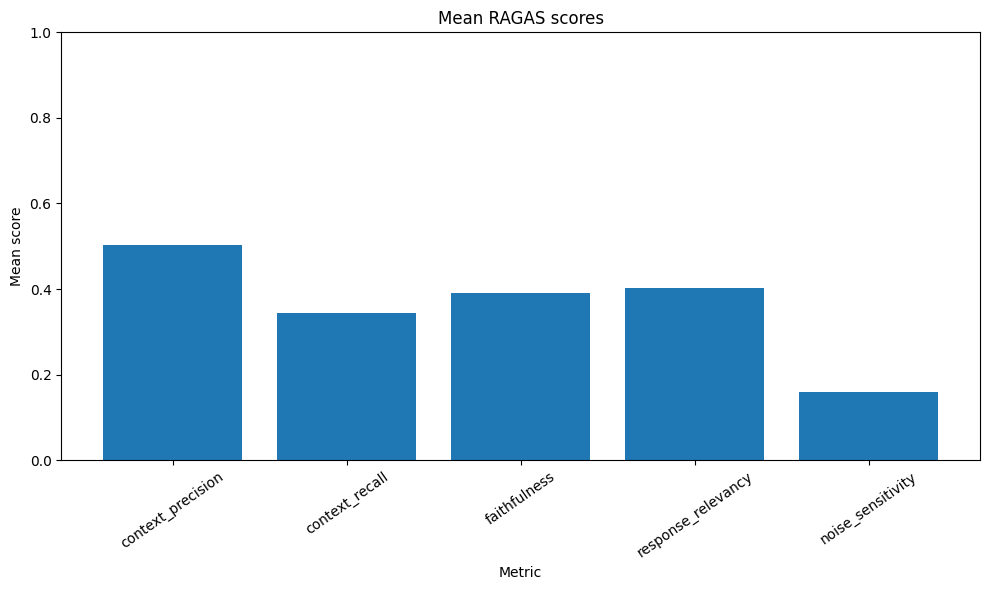

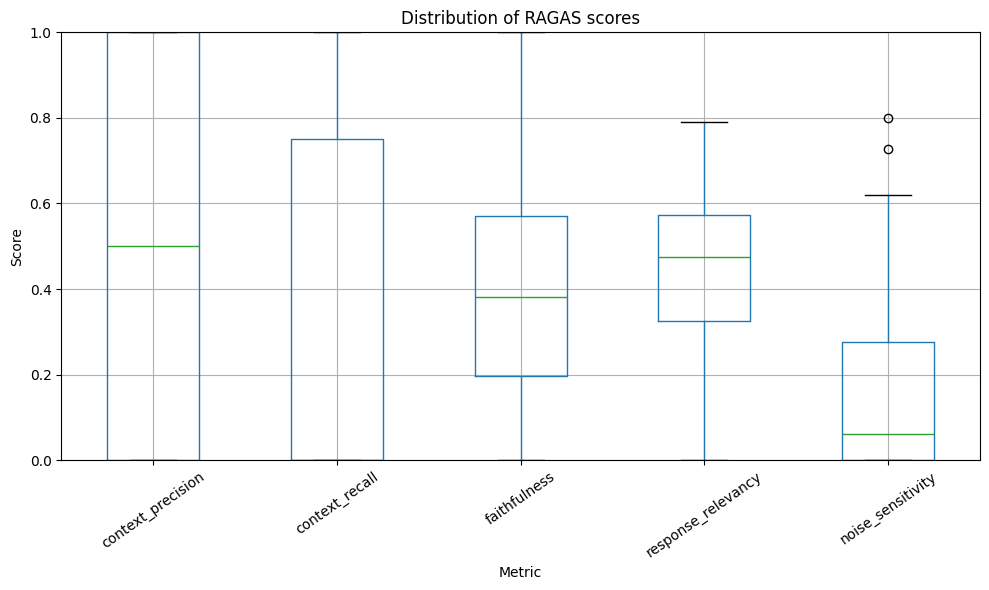

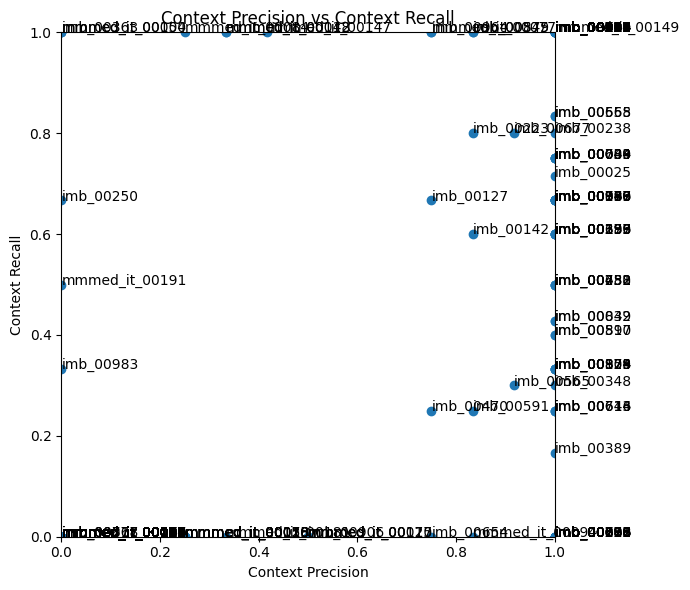

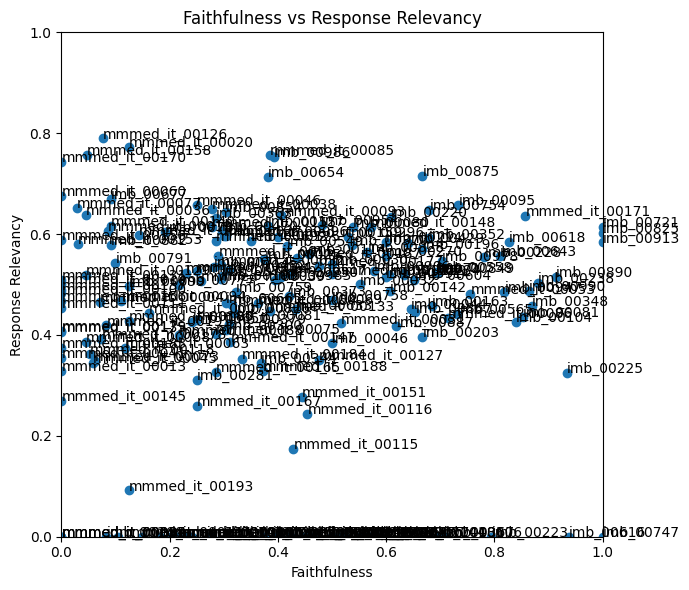

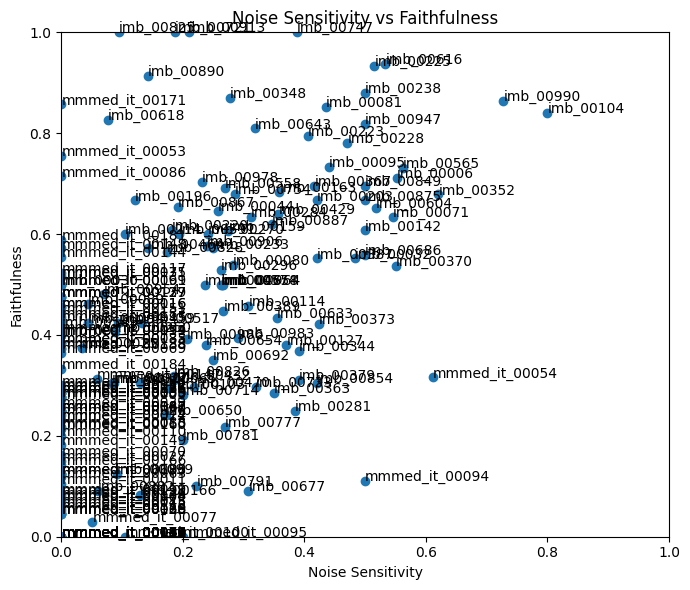


Export completed:
/home/eugrug/Project_CRAG_MedGemma/ragas_results/ragas_v0611_20260719T010434Z

CELL 16.3 COMPLETED SUCCESSFULLY
Per-record score rows : 196
Summary rows          : 5
Noise metric merged   : True
Export enabled        : True

Objects created:
- ragas_core_scores_df
- ragas_scores_df
- ragas_summary_df
- ragas_summary_by_dataset_df
- ragas_summary_by_execution_mode_df
- ragas_correlation_df
- ragas_run_manifest
- RAGAS_RUN_DIR


In [41]:
########################################################################################
# CELL 16.3 — RAGAS RESULTS ANALYSIS, TABLES AND FIGURES v06.10
########################################################################################
#
# Purpose:
# - extract per-record scores from the native RAGAS EvaluationResult
# - join scores with experimental metadata
# - integrate separately computed NoiseSensitivity results
# - calculate descriptive statistics
# - generate publication-oriented tables and exploratory figures
# - export reproducible CSV, JSON and PNG artifacts
#
# Does NOT:
# - call GPT-4o or any OpenAI API
# - rerun RAGAS
# - rerun the CRAG pipeline
# - alter scores, answers, contexts or references
########################################################################################

from pathlib import Path
import datetime
from typing import Dict, List, Any

import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


########################################################################################
# 16.3.1 — Configuration
########################################################################################

RAGAS_EXPORT_RESULTS = True

# Results are written outside the notebook file but inside the current project directory.
RAGAS_RESULTS_ROOT = Path.cwd() / "ragas_results"

RAGAS_RUN_TIMESTAMP_UTC = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")

# RAGAS_RUN_ID = f"ragas_v0610_{RAGAS_RUN_TIMESTAMP_UTC}"
RAGAS_RUN_ID = f"ragas_v0611_{RAGAS_RUN_TIMESTAMP_UTC}"

RAGAS_RUN_DIR = RAGAS_RESULTS_ROOT / RAGAS_RUN_ID


########################################################################################
# 16.3.2 — Preconditions
########################################################################################

required_objects_16_3 = [
    "ragas_raw_result",
    "ragas_eval_metadata_df",
    "ragas_smoke_dataset",
    "ragas_evaluation_elapsed_sec",
    "RAGAS_JUDGE_MODEL",
    "RAGAS_EMBEDDING_MODEL",
]

missing_objects_16_3 = [
    object_name
    for object_name in required_objects_16_3
    if object_name not in globals()
]

if missing_objects_16_3:
    raise RuntimeError(
        "Missing required objects. Run Cells 16.1 and 16.2 first:\n- "
        + "\n- ".join(missing_objects_16_3)
    )

if not isinstance(ragas_eval_metadata_df, pd.DataFrame):
    raise TypeError(
        "ragas_eval_metadata_df is not a pandas DataFrame."
    )

if ragas_eval_metadata_df.empty:
    raise RuntimeError(
        "ragas_eval_metadata_df is empty."
    )

if not hasattr(ragas_raw_result, "scores"):
    raise RuntimeError(
        "ragas_raw_result does not expose the expected 'scores' field."
    )


########################################################################################
# 16.3.3 — Extract native per-record RAGAS scores
########################################################################################

native_score_rows = list(ragas_raw_result.scores)

if not native_score_rows:
    raise RuntimeError(
        "ragas_raw_result.scores is empty."
    )

ragas_core_scores_df = pd.DataFrame(
    native_score_rows
).reset_index(drop=True)

if len(ragas_core_scores_df) != len(ragas_eval_metadata_df):
    raise RuntimeError(
        "Metadata/score row mismatch: "
        f"metadata={len(ragas_eval_metadata_df)}, "
        f"scores={len(ragas_core_scores_df)}."
    )


########################################################################################
# 16.3.4 — Validate and normalize metric names
########################################################################################

metric_column_aliases: Dict[str, str] = {
    "llm_context_precision_with_reference": "context_precision",
    "context_precision": "context_precision",

    "context_recall": "context_recall",
    "llm_context_recall": "context_recall",

    "faithfulness": "faithfulness",

    "answer_relevancy": "response_relevancy",
    "response_relevancy": "response_relevancy",
    "answer_relevance": "response_relevancy",
}

rename_map = {
    existing_name: canonical_name
    for existing_name, canonical_name in metric_column_aliases.items()
    if existing_name in ragas_core_scores_df.columns
}

ragas_core_scores_df = ragas_core_scores_df.rename(
    columns=rename_map
)

required_core_metric_columns = [
    "context_precision",
    "context_recall",
    "faithfulness",
    "response_relevancy",
]

missing_core_metric_columns = [
    metric_name
    for metric_name in required_core_metric_columns
    if metric_name not in ragas_core_scores_df.columns
]

if missing_core_metric_columns:
    raise RuntimeError(
        "Missing expected RAGAS metric columns:\n- "
        + "\n- ".join(missing_core_metric_columns)
        + "\nAvailable columns: "
        + ", ".join(map(str, ragas_core_scores_df.columns))
    )

for metric_name in required_core_metric_columns:
    ragas_core_scores_df[metric_name] = pd.to_numeric(
        ragas_core_scores_df[metric_name],
        errors="coerce"
    )


########################################################################################
# 16.3.5 — Join scores with record metadata
########################################################################################

ragas_scores_df = pd.concat(
    [
        ragas_eval_metadata_df.reset_index(drop=True),
        ragas_core_scores_df[required_core_metric_columns].reset_index(drop=True),
    ],
    axis=1,
)


########################################################################################
# 16.3.6 — Integrate NoiseSensitivity diagnostic results
########################################################################################

noise_data_available = (
    "noise_sensitivity_diagnostic_df" in globals()
    and isinstance(noise_sensitivity_diagnostic_df, pd.DataFrame)
    and not noise_sensitivity_diagnostic_df.empty
)

if noise_data_available:

    required_noise_columns = [
        "sample_id",
        "status",
        "noise_sensitivity",
    ]

    missing_noise_columns = [
        column_name
        for column_name in required_noise_columns
        if column_name not in noise_sensitivity_diagnostic_df.columns
    ]

    if missing_noise_columns:
        raise RuntimeError(
            "noise_sensitivity_diagnostic_df is missing columns:\n- "
            + "\n- ".join(missing_noise_columns)
        )

    noise_join_df = (
        noise_sensitivity_diagnostic_df[
            required_noise_columns
        ]
        .copy()
        .rename(
            columns={
                "status": "noise_sensitivity_status"
            }
        )
    )

    if noise_join_df["sample_id"].duplicated().any():
        duplicated_ids = noise_join_df.loc[
            noise_join_df["sample_id"].duplicated(),
            "sample_id"
        ].tolist()

        raise RuntimeError(
            "Duplicate sample_id values in NoiseSensitivity results: "
            + ", ".join(map(str, duplicated_ids))
        )

    noise_join_df["noise_sensitivity"] = pd.to_numeric(
        noise_join_df["noise_sensitivity"],
        errors="coerce"
    )

    ragas_scores_df = ragas_scores_df.merge(
        noise_join_df,
        on="sample_id",
        how="left",
        validate="one_to_one"
    )

else:

    ragas_scores_df["noise_sensitivity_status"] = "not_available"
    ragas_scores_df["noise_sensitivity"] = np.nan


########################################################################################
# 16.3.7 — Strict score validation
########################################################################################

all_metric_columns = [
    "context_precision",
    "context_recall",
    "faithfulness",
    "response_relevancy",
    "noise_sensitivity",
]

for metric_name in all_metric_columns:

    numeric_values = pd.to_numeric(
        ragas_scores_df[metric_name],
        errors="coerce"
    )

    finite_values = numeric_values.dropna()

    outside_range_mask = (
        (finite_values < 0.0)
        | (finite_values > 1.0)
    )

    if outside_range_mask.any():
        invalid_values = finite_values[
            outside_range_mask
        ].tolist()

        raise RuntimeError(
            f"Metric '{metric_name}' contains values outside [0, 1]: "
            f"{invalid_values}"
        )

    ragas_scores_df[metric_name] = numeric_values


########################################################################################
# 16.3.8 — Add transparent derived fields
########################################################################################

ragas_scores_df["core_metric_mean"] = (
    ragas_scores_df[
        required_core_metric_columns
    ]
    .mean(axis=1, skipna=True)
)

ragas_scores_df["all_metric_mean"] = (
    ragas_scores_df[
        all_metric_columns
    ]
    .mean(axis=1, skipna=True)
)

ragas_scores_df["core_metrics_complete"] = (
    ragas_scores_df[
        required_core_metric_columns
    ]
    .notna()
    .all(axis=1)
)

ragas_scores_df["noise_metric_available"] = (
    ragas_scores_df["noise_sensitivity"].notna()
)


########################################################################################
# 16.3.9 — Descriptive statistics
########################################################################################

ragas_summary_df = (
    ragas_scores_df[
        all_metric_columns
    ]
    .agg(
        [
            "count",
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
    )
    .transpose()
    .reset_index()
    .rename(
        columns={
            "index": "metric"
        }
    )
)

ragas_summary_df["sem"] = (
    ragas_summary_df["std"]
    / np.sqrt(ragas_summary_df["count"])
)

# Normal-approximation interval for exploratory reporting only.
# With n=3 it must not be interpreted as a reliable inferential confidence interval.
ragas_summary_df["ci95_lower_exploratory"] = (
    ragas_summary_df["mean"]
    - 1.96 * ragas_summary_df["sem"]
).clip(lower=0.0)

ragas_summary_df["ci95_upper_exploratory"] = (
    ragas_summary_df["mean"]
    + 1.96 * ragas_summary_df["sem"]
).clip(upper=1.0)


########################################################################################
# 16.3.10 — Dataset-level and execution-mode summaries
########################################################################################

ragas_summary_by_dataset_df = (
    ragas_scores_df
    .groupby(
        "dataset",
        dropna=False
    )[all_metric_columns]
    .agg(
        [
            "count",
            "mean",
            "std",
            "median",
        ]
    )
)

ragas_summary_by_execution_mode_df = (
    ragas_scores_df
    .groupby(
        "execution_mode",
        dropna=False
    )[all_metric_columns]
    .agg(
        [
            "count",
            "mean",
            "std",
            "median",
        ]
    )
)


########################################################################################
# 16.3.11 — Correlation matrix
########################################################################################

ragas_correlation_df = (
    ragas_scores_df[
        all_metric_columns
    ]
    .corr(
        method="spearman",
        min_periods=2
    )
)


########################################################################################
# 16.3.12 — Console report
########################################################################################

print("\n" + "=" * 110)
print("CELL 16.3 — RAGAS RESULTS ANALYSIS")
print("=" * 110)

print("Records analysed       :", len(ragas_scores_df))
print("Judge model            :", RAGAS_JUDGE_MODEL)
print("Embedding model        :", RAGAS_EMBEDDING_MODEL)
print("RAGAS elapsed seconds  :", ragas_evaluation_elapsed_sec)
print("Noise data available   :", noise_data_available)

print("\nPer-record scores:")
display(
    ragas_scores_df[
        [
            "sample_id",
            "dataset",
            "execution_mode",
            "image_used",
            "context_precision",
            "context_recall",
            "faithfulness",
            "response_relevancy",
            "noise_sensitivity",
            "noise_sensitivity_status",
            "core_metric_mean",
        ]
    ]
)

print("\nDescriptive statistics:")
display(ragas_summary_df)

print("\nSummary by dataset:")
display(ragas_summary_by_dataset_df)

print("\nSummary by execution mode:")
display(ragas_summary_by_execution_mode_df)

print("\nSpearman correlation matrix:")
display(ragas_correlation_df)


########################################################################################
# 16.3.13 — Figure data validation helper
########################################################################################

def require_minimum_complete_pairs(
    dataframe: pd.DataFrame,
    x_column: str,
    y_column: str,
    minimum_pairs: int = 2,
) -> pd.DataFrame:
    """
    Returns rows containing both metric values.

    A scatter plot is produced only when at least minimum_pairs complete
    observations exist. This prevents misleading empty or one-point figures.
    """

    complete_pairs = dataframe[
        [x_column, y_column, "sample_id", "dataset"]
    ].dropna(
        subset=[x_column, y_column]
    )

    if len(complete_pairs) < minimum_pairs:
        return pd.DataFrame()

    return complete_pairs


########################################################################################
# 16.3.14 — Bar plot: mean RAGAS metrics
########################################################################################

bar_plot_df = (
    ragas_summary_df[
        ["metric", "mean"]
    ]
    .dropna(subset=["mean"])
    .copy()
)

if not bar_plot_df.empty:

    figure_bar, axis_bar = plt.subplots(
        figsize=(10, 6)
    )

    axis_bar.bar(
        bar_plot_df["metric"],
        bar_plot_df["mean"]
    )

    axis_bar.set_title(
        "Mean RAGAS scores"
    )

    axis_bar.set_xlabel(
        "Metric"
    )

    axis_bar.set_ylabel(
        "Mean score"
    )

    axis_bar.set_ylim(
        0.0,
        1.0
    )

    axis_bar.tick_params(
        axis="x",
        rotation=35
    )

    figure_bar.tight_layout()

    plt.show()


########################################################################################
# 16.3.15 — Box plot: score distributions
########################################################################################

box_plot_df = (
    ragas_scores_df[
        all_metric_columns
    ]
    .copy()
)

if not box_plot_df.dropna(how="all").empty:

    figure_box, axis_box = plt.subplots(
        figsize=(10, 6)
    )

    box_plot_df.boxplot(
        ax=axis_box
    )

    axis_box.set_title(
        "Distribution of RAGAS scores"
    )

    axis_box.set_xlabel(
        "Metric"
    )

    axis_box.set_ylabel(
        "Score"
    )

    axis_box.set_ylim(
        0.0,
        1.0
    )

    axis_box.tick_params(
        axis="x",
        rotation=35
    )

    figure_box.tight_layout()

    plt.show()


########################################################################################
# 16.3.16 — Scatter: Context Precision vs Context Recall
########################################################################################

scatter_cp_cr_df = require_minimum_complete_pairs(
    ragas_scores_df,
    "context_precision",
    "context_recall",
)

if not scatter_cp_cr_df.empty:

    figure_cp_cr, axis_cp_cr = plt.subplots(
        figsize=(7, 6)
    )

    axis_cp_cr.scatter(
        scatter_cp_cr_df["context_precision"],
        scatter_cp_cr_df["context_recall"]
    )

    for row in scatter_cp_cr_df.itertuples(index=False):
        axis_cp_cr.annotate(
            row.sample_id,
            (
                row.context_precision,
                row.context_recall,
            )
        )

    axis_cp_cr.set_title(
        "Context Precision vs Context Recall"
    )

    axis_cp_cr.set_xlabel(
        "Context Precision"
    )

    axis_cp_cr.set_ylabel(
        "Context Recall"
    )

    axis_cp_cr.set_xlim(
        0.0,
        1.0
    )

    axis_cp_cr.set_ylim(
        0.0,
        1.0
    )

    figure_cp_cr.tight_layout()

    plt.show()

else:

    print(
        "\nScatter plot skipped: insufficient complete pairs for "
        "Context Precision vs Context Recall."
    )


########################################################################################
# 16.3.17 — Scatter: Faithfulness vs Response Relevancy
########################################################################################

scatter_f_rr_df = require_minimum_complete_pairs(
    ragas_scores_df,
    "faithfulness",
    "response_relevancy",
)

if not scatter_f_rr_df.empty:

    figure_f_rr, axis_f_rr = plt.subplots(
        figsize=(7, 6)
    )

    axis_f_rr.scatter(
        scatter_f_rr_df["faithfulness"],
        scatter_f_rr_df["response_relevancy"]
    )

    for row in scatter_f_rr_df.itertuples(index=False):
        axis_f_rr.annotate(
            row.sample_id,
            (
                row.faithfulness,
                row.response_relevancy,
            )
        )

    axis_f_rr.set_title(
        "Faithfulness vs Response Relevancy"
    )

    axis_f_rr.set_xlabel(
        "Faithfulness"
    )

    axis_f_rr.set_ylabel(
        "Response Relevancy"
    )

    axis_f_rr.set_xlim(
        0.0,
        1.0
    )

    axis_f_rr.set_ylim(
        0.0,
        1.0
    )

    figure_f_rr.tight_layout()

    plt.show()

else:

    print(
        "\nScatter plot skipped: insufficient complete pairs for "
        "Faithfulness vs Response Relevancy."
    )


########################################################################################
# 16.3.18 — Scatter: Noise Sensitivity vs Faithfulness
########################################################################################

scatter_ns_f_df = require_minimum_complete_pairs(
    ragas_scores_df,
    "noise_sensitivity",
    "faithfulness",
)

if not scatter_ns_f_df.empty:

    figure_ns_f, axis_ns_f = plt.subplots(
        figsize=(7, 6)
    )

    axis_ns_f.scatter(
        scatter_ns_f_df["noise_sensitivity"],
        scatter_ns_f_df["faithfulness"]
    )

    for row in scatter_ns_f_df.itertuples(index=False):
        axis_ns_f.annotate(
            row.sample_id,
            (
                row.noise_sensitivity,
                row.faithfulness,
            )
        )

    axis_ns_f.set_title(
        "Noise Sensitivity vs Faithfulness"
    )

    axis_ns_f.set_xlabel(
        "Noise Sensitivity"
    )

    axis_ns_f.set_ylabel(
        "Faithfulness"
    )

    axis_ns_f.set_xlim(
        0.0,
        1.0
    )

    axis_ns_f.set_ylim(
        0.0,
        1.0
    )

    figure_ns_f.tight_layout()

    plt.show()

else:

    print(
        "\nScatter plot skipped: insufficient complete pairs for "
        "Noise Sensitivity vs Faithfulness."
    )


########################################################################################
# 16.3.19 — Export reproducible artifacts
########################################################################################

ragas_run_manifest: Dict[str, Any] = {
    "run_id": RAGAS_RUN_ID,
    "created_at_utc": RAGAS_RUN_TIMESTAMP_UTC,
    "ragas_version": getattr(
        ragas,
        "__version__",
        "unknown"
    ),
    "judge_model": RAGAS_JUDGE_MODEL,
    "embedding_model": RAGAS_EMBEDDING_MODEL,
    "records_evaluated": int(len(ragas_scores_df)),
    "core_metrics": required_core_metric_columns,
    "noise_metric_available": bool(noise_data_available),
    "ragas_evaluation_elapsed_sec": float(
        ragas_evaluation_elapsed_sec
    ),
    "datasets": sorted(
        ragas_scores_df["dataset"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    ),
    "execution_modes": sorted(
        ragas_scores_df["execution_mode"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    ),
}

if RAGAS_EXPORT_RESULTS:

    RAGAS_RUN_DIR.mkdir(
        parents=True,
        exist_ok=False
    )

    ragas_scores_df.to_csv(
        RAGAS_RUN_DIR / "ragas_scores_per_record.csv",
        index=False
    )

    ragas_summary_df.to_csv(
        RAGAS_RUN_DIR / "ragas_summary_statistics.csv",
        index=False
    )

    ragas_summary_by_dataset_df.to_csv(
        RAGAS_RUN_DIR / "ragas_summary_by_dataset.csv"
    )

    ragas_summary_by_execution_mode_df.to_csv(
        RAGAS_RUN_DIR / "ragas_summary_by_execution_mode.csv"
    )

    ragas_correlation_df.to_csv(
        RAGAS_RUN_DIR / "ragas_spearman_correlations.csv"
    )

    with open(
        RAGAS_RUN_DIR / "ragas_run_manifest.json",
        "w",
        encoding="utf-8"
    ) as manifest_file:

        json.dump(
            ragas_run_manifest,
            manifest_file,
            ensure_ascii=False,
            indent=2
        )

    print("\nExport completed:")
    print(RAGAS_RUN_DIR.resolve())

else:

    print("\nExport disabled: RAGAS_EXPORT_RESULTS=False")


########################################################################################
# 16.3.20 — Final summary
########################################################################################

print("\n" + "=" * 110)
print("CELL 16.3 COMPLETED SUCCESSFULLY")
print("=" * 110)

print("Per-record score rows :", len(ragas_scores_df))
print("Summary rows          :", len(ragas_summary_df))
print("Noise metric merged   :", noise_data_available)
print("Export enabled        :", RAGAS_EXPORT_RESULTS)

print("\nObjects created:")
print("- ragas_core_scores_df")
print("- ragas_scores_df")
print("- ragas_summary_df")
print("- ragas_summary_by_dataset_df")
print("- ragas_summary_by_execution_mode_df")
print("- ragas_correlation_df")
print("- ragas_run_manifest")
print("- RAGAS_RUN_DIR")

print("=" * 110)

In [42]:
print(ragas_scores_df.columns.tolist())
display(ragas_scores_df)
display(ragas_summary_df)
print(RAGAS_RUN_DIR)

['sample_id', 'dataset', 'execution_mode', 'image_used', 'context_precision', 'context_recall', 'faithfulness', 'response_relevancy', 'noise_sensitivity_status', 'noise_sensitivity', 'core_metric_mean', 'all_metric_mean', 'core_metrics_complete', 'noise_metric_available']


,sample_id,dataset,execution_mode,image_used,context_precision,context_recall,faithfulness,response_relevancy,noise_sensitivity_status,noise_sensitivity,core_metric_mean,all_metric_mean,core_metrics_complete,noise_metric_available
0,imb_00654,IMB_Curated_Test_Set_1000,text_only,False,0.75,0.000000,0.380952,0.712653,success,0.238095,0.460901,0.416340,True,True
1,imb_00114,IMB_Curated_Test_Set_1000,text_only,False,1.00,1.000000,0.458333,0.560550,success,0.307692,0.754721,0.665315,True,True
2,imb_00025,IMB_Curated_Test_Set_1000,text_only,False,1.00,0.714286,0.375000,0.551581,success,0.034483,0.660217,0.535070,True,True
3,imb_00759,IMB_Curated_Test_Set_1000,text_only,False,1.00,0.666667,0.322581,0.486126,failed,NaN,0.618843,0.618843,True,False
4,imb_00281,IMB_Curated_Test_Set_1000,text_only,False,1.00,0.500000,0.250000,0.310164,success,0.384615,0.515041,0.488956,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,mmmed_it_00013,MMMED_Italian,multimodal,True,0.00,0.000000,0.000000,0.327936,success,0.000000,0.081984,0.065587,True,True
192,mmmed_it_00088,MMMED_Italian,multimodal,True,0.00,0.000000,0.217391,0.400145,success,0.000000,0.154384,0.123507,True,True
193,mmmed_it_00158,MMMED_Italian,multimodal,True,0.00,0.000000,0.047619,0.757135,success,0.000000,0.201188,0.160951,True,True
194,mmmed_it_00054,MMMED_Italian,multimodal,True,0.00,1.000000,0.315789,0.459416,success,0.611111,0.443801,0.477263,True,True


,metric,count,mean,std,median,min,max,sem,ci95_lower_exploratory,ci95_upper_exploratory
0,context_precision,196.0,0.503827,0.474214,0.500000,0.0,1.00000,0.033872,0.437437,0.570216
1,context_recall,196.0,0.344752,0.414017,0.000000,0.0,1.00000,0.029573,0.286790,0.402715
2,faithfulness,195.0,0.389871,0.262532,0.380952,0.0,1.00000,0.018800,0.353022,0.426719
3,response_relevancy,196.0,0.401996,0.232249,0.474188,0.0,0.78956,0.016589,0.369481,0.434510
4,noise_sensitivity,193.0,0.158256,0.193167,0.060606,0.0,0.80000,0.013904,0.131003,0.185509


/home/eugrug/Project_CRAG_MedGemma/ragas_results/ragas_v0611_20260719T010434Z


In [43]:
########################################################################################
# CELL 16.3-bis — COMPLETE RAGAS EXPERIMENT EXPORT v06.10
########################################################################################
#
# Purpose:
# - complete the artifacts exported by Cell 16.3
# - preserve canonical RAGAS inputs and per-record outputs
# - preserve pipeline diagnostics and NoiseSensitivity diagnostics
# - save generated figures in PNG and PDF formats
# - extend the experimental run manifest
#
# Does NOT:
# - call OpenAI APIs
# - rerun RAGAS
# - rerun the CRAG pipeline
# - modify scores or benchmark records
########################################################################################

from pathlib import Path
from typing import Any, Dict
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
import ragas


########################################################################################
# 16.3-bis.1 — Preconditions
########################################################################################

required_objects_16_3_bis = [
    "RAGAS_RUN_DIR",
    "RAGAS_RUN_ID",
    "RAGAS_RUN_TIMESTAMP_UTC",
    "ragas_scores_df",
    "ragas_summary_df",
    "ragas_raw_result",
    "ragas_eval_metadata_df",
    "ragas_dataset_df",
    "RAGAS_JUDGE_MODEL",
    "RAGAS_EMBEDDING_MODEL",
]

missing_objects_16_3_bis = [
    object_name
    for object_name in required_objects_16_3_bis
    if object_name not in globals()
]

if missing_objects_16_3_bis:
    raise RuntimeError(
        "Missing required objects. Run Cells 15, 16.2 and 16.3 first:\n- "
        + "\n- ".join(missing_objects_16_3_bis)
    )

RAGAS_RUN_DIR = Path(RAGAS_RUN_DIR)

if not RAGAS_RUN_DIR.exists():
    raise RuntimeError(
        f"RAGAS run directory not found: {RAGAS_RUN_DIR}"
    )

selected_sample_ids = (
    ragas_scores_df["sample_id"]
    .astype(str)
    .tolist()
)

if not selected_sample_ids:
    raise RuntimeError(
        "ragas_scores_df contains no sample identifiers."
    )


########################################################################################
# 16.3-bis.2 — JSON serialization helper
########################################################################################

def _json_safe_value(value: Any) -> Any:
    """
    Converts common NumPy, pandas and container objects to JSON-safe values.
    """

    if value is None:
        return None

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating,)):
        if np.isnan(value):
            return None
        return float(value)

    if isinstance(value, (np.bool_,)):
        return bool(value)

    if isinstance(value, pd.Timestamp):
        return value.isoformat()

    if isinstance(value, np.ndarray):
        return [
            _json_safe_value(item)
            for item in value.tolist()
        ]

    if isinstance(value, (list, tuple)):
        return [
            _json_safe_value(item)
            for item in value
        ]

    if isinstance(value, dict):
        return {
            str(key): _json_safe_value(item)
            for key, item in value.items()
        }

    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass

    return value


def _write_json_file(
    file_path: Path,
    payload: Any,
) -> None:
    """
    Writes a JSON file using UTF-8 without ASCII escaping.
    """

    with open(
        file_path,
        "w",
        encoding="utf-8"
    ) as json_file:

        json.dump(
            _json_safe_value(payload),
            json_file,
            ensure_ascii=False,
            indent=2
        )


def _write_dataframe_jsonl(
    dataframe: pd.DataFrame,
    file_path: Path,
) -> None:
    """
    Writes one JSON object per DataFrame row.
    Lists such as retrieved_contexts remain structured.
    """

    records = dataframe.to_dict(
        orient="records"
    )

    with open(
        file_path,
        "w",
        encoding="utf-8"
    ) as jsonl_file:

        for record in records:
            jsonl_file.write(
                json.dumps(
                    _json_safe_value(record),
                    ensure_ascii=False
                )
                + "\n"
            )


########################################################################################
# 16.3-bis.3 — Export canonical RAGAS evaluation inputs
########################################################################################

canonical_columns = [
    "sample_id",
    "dataset",
    "execution_mode",
    "image_used",
    "user_input",
    "response",
    "retrieved_contexts",
    "reference",
]

missing_canonical_columns = [
    column_name
    for column_name in canonical_columns
    if column_name not in ragas_dataset_df.columns
]

if missing_canonical_columns:
    raise RuntimeError(
        "ragas_dataset_df is missing canonical columns:\n- "
        + "\n- ".join(missing_canonical_columns)
    )

ragas_canonical_input_df = (
    ragas_dataset_df[
        ragas_dataset_df["sample_id"]
        .astype(str)
        .isin(selected_sample_ids)
    ][canonical_columns]
    .copy()
)

# Preserve exactly the order used by the RAGAS evaluation.
ragas_canonical_input_df["_evaluation_order"] = (
    ragas_canonical_input_df["sample_id"]
    .astype(str)
    .map({
        sample_id: position
        for position, sample_id in enumerate(selected_sample_ids)
    })
)

ragas_canonical_input_df = (
    ragas_canonical_input_df
    .sort_values("_evaluation_order")
    .drop(columns="_evaluation_order")
    .reset_index(drop=True)
)

if len(ragas_canonical_input_df) != len(ragas_scores_df):
    raise RuntimeError(
        "Canonical input export mismatch: "
        f"inputs={len(ragas_canonical_input_df)}, "
        f"scores={len(ragas_scores_df)}."
    )

ragas_canonical_input_df.to_csv(
    RAGAS_RUN_DIR / "ragas_canonical_inputs.csv",
    index=False
)

_write_dataframe_jsonl(
    ragas_canonical_input_df,
    RAGAS_RUN_DIR / "ragas_canonical_inputs.jsonl"
)


########################################################################################
# 16.3-bis.4 — Export complete per-record results
########################################################################################

ragas_complete_results_df = ragas_canonical_input_df.merge(
    ragas_scores_df,
    on=[
        "sample_id",
        "dataset",
        "execution_mode",
        "image_used",
    ],
    how="inner",
    validate="one_to_one"
)

if len(ragas_complete_results_df) != len(ragas_scores_df):
    raise RuntimeError(
        "Complete result export mismatch after input/score join."
    )

ragas_complete_results_df.to_csv(
    RAGAS_RUN_DIR / "ragas_complete_results_per_record.csv",
    index=False
)

_write_dataframe_jsonl(
    ragas_complete_results_df,
    RAGAS_RUN_DIR / "ragas_complete_results_per_record.jsonl"
)


########################################################################################
# 16.3-bis.5 — Export Pipeline Diagnostic Metrics
########################################################################################

pipeline_diagnostics_exported = False
selected_pipeline_diagnostics_df = pd.DataFrame()

if (
    "benchmark_diagnostics_df" in globals()
    and isinstance(benchmark_diagnostics_df, pd.DataFrame)
    and not benchmark_diagnostics_df.empty
):

    selected_pipeline_diagnostics_df = (
        benchmark_diagnostics_df[
            benchmark_diagnostics_df["sample_id"]
            .astype(str)
            .isin(selected_sample_ids)
        ]
        .copy()
    )

    if not selected_pipeline_diagnostics_df.empty:

        selected_pipeline_diagnostics_df.to_csv(
            RAGAS_RUN_DIR / "pipeline_diagnostics_per_record.csv",
            index=False
        )

        _write_dataframe_jsonl(
            selected_pipeline_diagnostics_df,
            RAGAS_RUN_DIR / "pipeline_diagnostics_per_record.jsonl"
        )

        pipeline_diagnostics_exported = True


########################################################################################
# 16.3-bis.6 — Export original CRAG benchmark outputs when available
########################################################################################

source_outputs_exported = False
selected_source_outputs_df = pd.DataFrame()

if (
    "selected_source_records" in globals()
    and isinstance(selected_source_records, list)
    and selected_source_records
):

    selected_source_records_for_export = [
        record
        for record in selected_source_records
        if str(record.get("sample_id", "")) in selected_sample_ids
    ]

    if selected_source_records_for_export:

        selected_source_outputs_df = pd.DataFrame(
            selected_source_records_for_export
        )

        preferred_source_columns = [
            "sample_id",
            "dataset",
            "execution_mode",
            "question",
            "reference_answer",
            "image_url",
            "source_image",
            "raw_generated_response",
            "answer_for_ragas",
            "local_contexts",
            "web_context",
            "final_context",
            "routing_decision",
            "latency_sec",
            "reasoning_leakage_detected",
            "answer_extraction_ok",
            "post_filter_applied",
            "post_filter_notes",
            "metadata",
            "_source_container",
        ]

        available_source_columns = [
            column_name
            for column_name in preferred_source_columns
            if column_name in selected_source_outputs_df.columns
        ]

        selected_source_outputs_df = (
            selected_source_outputs_df[
                available_source_columns
            ]
            .copy()
        )

        selected_source_outputs_df.to_csv(
            RAGAS_RUN_DIR / "crag_outputs_selected_records.csv",
            index=False
        )

        _write_dataframe_jsonl(
            selected_source_outputs_df,
            RAGAS_RUN_DIR / "crag_outputs_selected_records.jsonl"
        )

        source_outputs_exported = True


########################################################################################
# 16.3-bis.7 — Export NoiseSensitivity diagnostic details
########################################################################################

noise_diagnostics_exported = False

if (
    "noise_sensitivity_diagnostic_df" in globals()
    and isinstance(noise_sensitivity_diagnostic_df, pd.DataFrame)
    and not noise_sensitivity_diagnostic_df.empty
):

    selected_noise_diagnostics_df = (
        noise_sensitivity_diagnostic_df[
            noise_sensitivity_diagnostic_df["sample_id"]
            .astype(str)
            .isin(selected_sample_ids)
        ]
        .copy()
    )

    selected_noise_diagnostics_df.to_csv(
        RAGAS_RUN_DIR / "noise_sensitivity_diagnostics.csv",
        index=False
    )

    _write_dataframe_jsonl(
        selected_noise_diagnostics_df,
        RAGAS_RUN_DIR / "noise_sensitivity_diagnostics.jsonl"
    )

    noise_diagnostics_exported = True


########################################################################################
# 16.3-bis.8 — Export native RAGAS score representation
########################################################################################

raw_score_rows = [
    _json_safe_value(score_row)
    for score_row in list(ragas_raw_result.scores)
]

_write_json_file(
    RAGAS_RUN_DIR / "ragas_native_scores.json",
    raw_score_rows
)

with open(
    RAGAS_RUN_DIR / "ragas_native_result_repr.txt",
    "w",
    encoding="utf-8"
) as result_repr_file:

    result_repr_file.write(
        repr(ragas_raw_result)
    )


########################################################################################
# 16.3-bis.9 — Save figures in PNG and PDF
########################################################################################

figure_objects = {
    "mean_ragas_scores": globals().get("figure_bar"),
    "ragas_score_distributions": globals().get("figure_box"),
    "context_precision_vs_recall": globals().get("figure_cp_cr"),
    "faithfulness_vs_response_relevancy": globals().get("figure_f_rr"),
    "noise_sensitivity_vs_faithfulness": globals().get("figure_ns_f"),
}

saved_figure_files = []

for figure_name, figure_object in figure_objects.items():

    if figure_object is None:
        continue

    png_path = RAGAS_RUN_DIR / f"{figure_name}.png"
    pdf_path = RAGAS_RUN_DIR / f"{figure_name}.pdf"

    figure_object.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    figure_object.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    saved_figure_files.extend([
        png_path.name,
        pdf_path.name,
    ])


########################################################################################
# 16.3-bis.10 — Extended experimental manifest
########################################################################################

def _optional_global_value(
    variable_name: str,
    default: Any = None,
) -> Any:
    """
    Reads an optional global configuration value without inventing it.
    """

    return globals().get(
        variable_name,
        default
    )


extended_manifest: Dict[str, Any] = {
    "run_identity": {
        "run_id": RAGAS_RUN_ID,
        "created_at_utc": RAGAS_RUN_TIMESTAMP_UTC,
        "run_directory": str(RAGAS_RUN_DIR.resolve()),
    },

    "software_environment": {
        "python_version": platform.python_version(),
        "platform": platform.platform(),
        "ragas_version": getattr(
            ragas,
            "__version__",
            "unknown"
        ),
        "pandas_version": pd.__version__,
        "numpy_version": np.__version__,
        "matplotlib_version": matplotlib.__version__,
    },

    "evaluation_configuration": {

        "judge_model": RAGAS_JUDGE_MODEL,

        "embedding_model": RAGAS_EMBEDDING_MODEL,

        "benchmark_run_mode": _optional_global_value(
            "BENCHMARK_RUN_MODE"
        ),

        "benchmark_run_label": _optional_global_value(
            "BENCHMARK_RUN_LABEL"
        ),

        "requested_source_records": _optional_global_value(
            "BENCHMARK_REQUESTED_TOTAL"
        ),

        "requested_imb_records": _optional_global_value(
            "N_IMB_BENCHMARK"
        ),

        "requested_mmmed_records": _optional_global_value(
            "N_MMMED_BENCHMARK"
        ),

        "dataset_selection_mode": _optional_global_value(
            "ragas_dataset_selection_mode"
        ),

        "records_evaluated": int(
            len(ragas_scores_df)
        ),

        "ragas_evaluation_elapsed_sec": float(
            ragas_evaluation_elapsed_sec
        ),

        "core_metrics": [
            "context_precision",
            "context_recall",
            "faithfulness",
            "response_relevancy",
        ],

        "noise_sensitivity_evaluated_separately": bool(
            _optional_global_value(
                "RAGAS_ENABLE_NOISE_SENSITIVITY",
                False
            )
        ),
    },

    "dataset_configuration": {
        "datasets": sorted(
            ragas_scores_df["dataset"]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        ),
        "execution_modes": sorted(
            ragas_scores_df["execution_mode"]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        ),
        "sample_ids": selected_sample_ids,
        "benchmark_random_seed": _optional_global_value(
            "BENCHMARK_RANDOM_SEED"
        ),
        "multimodal_random_seed": _optional_global_value(
            "MULTIMODAL_RANDOM_SEED"
        ),
        "requested_mmmed_multimodal": _optional_global_value(
            "N_MMMED_MULTIMODAL"
        ),
    },

    "pipeline_generation_configuration": {
        "medgemma_context_window": _optional_global_value(
            "MEDGEMMA_CONTEXT_WINDOW"
        ),
        "benchmark_max_new_tokens": _optional_global_value(
            "BENCHMARK_MAX_NEW_TOKENS"
        ),
        "benchmark_min_new_tokens": _optional_global_value(
            "BENCHMARK_MIN_NEW_TOKENS"
        ),
        "benchmark_safety_margin": _optional_global_value(
            "BENCHMARK_SAFETY_MARGIN"
        ),
        "max_generation_query_chars": _optional_global_value(
            "MAX_GENERATION_QUERY_CHARS"
        ),
        "max_generation_local_context_chars": _optional_global_value(
            "MAX_GENERATION_LOCAL_CONTEXT_CHARS"
        ),
        "max_generation_web_context_chars": _optional_global_value(
            "MAX_GENERATION_WEB_CONTEXT_CHARS"
        ),
    },

    "artifact_status": {
        "canonical_inputs_exported": True,
        "complete_results_exported": True,
        "pipeline_diagnostics_exported": pipeline_diagnostics_exported,
        "source_outputs_exported": source_outputs_exported,
        "noise_diagnostics_exported": noise_diagnostics_exported,
        "saved_figures": saved_figure_files,
    },
}

_write_json_file(
    RAGAS_RUN_DIR / "ragas_extended_run_manifest.json",
    extended_manifest
)


########################################################################################
# 16.3-bis.11 — Artifact inventory
########################################################################################

artifact_inventory = []

for artifact_path in sorted(
    RAGAS_RUN_DIR.iterdir()
):

    if artifact_path.is_file():

        artifact_inventory.append({
            "filename": artifact_path.name,
            "size_bytes": artifact_path.stat().st_size,
            "suffix": artifact_path.suffix.lower(),
        })

ragas_artifact_inventory_df = pd.DataFrame(
    artifact_inventory
)

ragas_artifact_inventory_df.to_csv(
    RAGAS_RUN_DIR / "artifact_inventory.csv",
    index=False
)


########################################################################################
# 16.3-bis.12 — Final validation and summary
########################################################################################

mandatory_artifacts = [
    "ragas_scores_per_record.csv",
    "ragas_summary_statistics.csv",
    "ragas_canonical_inputs.csv",
    "ragas_canonical_inputs.jsonl",
    "ragas_complete_results_per_record.csv",
    "ragas_complete_results_per_record.jsonl",
    "ragas_native_scores.json",
    "ragas_extended_run_manifest.json",
]

missing_mandatory_artifacts = [
    artifact_name
    for artifact_name in mandatory_artifacts
    if not (
        RAGAS_RUN_DIR / artifact_name
    ).exists()
]

if missing_mandatory_artifacts:
    raise RuntimeError(
        "Complete export failed. Missing mandatory artifacts:\n- "
        + "\n- ".join(missing_mandatory_artifacts)
    )


print("\n" + "=" * 110)
print("CELL 16.3-bis — COMPLETE EXPORT SUMMARY")
print("=" * 110)

print("Run directory                 :", RAGAS_RUN_DIR.resolve())
print("Evaluated records             :", len(ragas_scores_df))
print("Canonical inputs exported     :", len(ragas_canonical_input_df))
print("Complete result rows          :", len(ragas_complete_results_df))
print("Pipeline diagnostics exported :", pipeline_diagnostics_exported)
print("CRAG source outputs exported  :", source_outputs_exported)
print("Noise diagnostics exported    :", noise_diagnostics_exported)
print("Figure files saved            :", len(saved_figure_files))
print("Total files in run directory  :", len(ragas_artifact_inventory_df))

print("\nSaved figures:")

if saved_figure_files:
    for saved_figure in saved_figure_files:
        print("-", saved_figure)
else:
    print("No figure objects were available.")

print("\nArtifact inventory:")
display(ragas_artifact_inventory_df)

print("\nObjects created:")
print("- ragas_canonical_input_df")
print("- ragas_complete_results_df")
print("- selected_pipeline_diagnostics_df")
print("- selected_source_outputs_df")
print("- extended_manifest")
print("- ragas_artifact_inventory_df")

print("=" * 110)


CELL 16.3-bis — COMPLETE EXPORT SUMMARY
Run directory                 : /home/eugrug/Project_CRAG_MedGemma/ragas_results/ragas_v0611_20260719T010434Z
Evaluated records             : 196
Canonical inputs exported     : 196
Complete result rows          : 196
Pipeline diagnostics exported : True
CRAG source outputs exported  : True
Noise diagnostics exported    : True
Figure files saved            : 10
Total files in run directory  : 29

Saved figures:
- mean_ragas_scores.png
- mean_ragas_scores.pdf
- ragas_score_distributions.png
- ragas_score_distributions.pdf
- context_precision_vs_recall.png
- context_precision_vs_recall.pdf
- faithfulness_vs_response_relevancy.png
- faithfulness_vs_response_relevancy.pdf
- noise_sensitivity_vs_faithfulness.png
- noise_sensitivity_vs_faithfulness.pdf

Artifact inventory:


,filename,size_bytes,suffix
0,context_precision_vs_recall.pdf,15064,.pdf
1,context_precision_vs_recall.png,250084,.png
2,crag_outputs_selected_records.csv,2458961,.csv
3,crag_outputs_selected_records.jsonl,2535442,.jsonl
4,faithfulness_vs_response_relevancy.pdf,20132,.pdf
5,faithfulness_vs_response_relevancy.png,743825,.png
6,mean_ragas_scores.pdf,12712,.pdf
7,mean_ragas_scores.png,151998,.png
8,noise_sensitivity_diagnostics.csv,12304,.csv
9,noise_sensitivity_diagnostics.jsonl,35554,.jsonl



Objects created:
- ragas_canonical_input_df
- ragas_complete_results_df
- selected_pipeline_diagnostics_df
- selected_source_outputs_df
- extended_manifest
- ragas_artifact_inventory_df


In [45]:
########################################################################################
# CELL 16.4 — ADVANCED SCIENTIFIC FIGURES FROM SAVED RAGAS ARTIFACTS v06.10
########################################################################################
#
# Purpose:
# - reload final benchmark artifacts from disk
# - generate publication-oriented figures without rerunning CRAG or RAGAS
# - produce cloud-style scatter plots with dataset groups and robust outliers
# - generate histograms, ECDF curves, violin/strip distributions,
#   correlation heatmaps, stacked bars and donut charts
# - export figures as PNG and vector PDF
#
# Does NOT:
# - call OpenAI
# - call Tavily
# - rerun RAGAS
# - alter the original benchmark artifacts
########################################################################################

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)


########################################################################################
# 16.4.1 — Configuration
########################################################################################

if "RAGAS_RUN_DIR" not in globals():
    raise RuntimeError(
        "RAGAS_RUN_DIR non disponibile. "
        "Eseguire prima le Celle 16.3 e 16.3-bis."
    )

FINAL_RUN_DIR = Path(RAGAS_RUN_DIR)

ADVANCED_FIGURE_DIR = FINAL_RUN_DIR / "advanced_figures"

SAVE_PNG = True
SAVE_PDF = True

FIGURE_DPI = 300

# Robust outlier threshold.
# Approximately comparable to a conservative multivariate threshold.
OUTLIER_ROBUST_Z_THRESHOLD = 3.5

# Reproducible jitter for cloud-style scatter plots.
PLOT_RANDOM_SEED = 42


########################################################################################
# 16.4.2 — Input validation
########################################################################################

if not FINAL_RUN_DIR.exists():
    raise FileNotFoundError(
        f"Final run directory not found:\n{FINAL_RUN_DIR}"
    )

ADVANCED_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

primary_candidates = [
    FINAL_RUN_DIR / "ragas_complete_results_per_record.csv",
    FINAL_RUN_DIR / "ragas_scores_per_record.csv",
]

primary_path = next(
    (
        path
        for path in primary_candidates
        if path.exists()
    ),
    None,
)

if primary_path is None:
    raise FileNotFoundError(
        "Neither ragas_complete_results_per_record.csv "
        "nor ragas_scores_per_record.csv was found."
    )

results_df = pd.read_csv(primary_path)

print("\n" + "=" * 110)
print("CELL 16.4 — ADVANCED SCIENTIFIC FIGURES")
print("=" * 110)
print(f"Run directory     : {FINAL_RUN_DIR}")
print(f"Primary input     : {primary_path.name}")
print(f"Input rows        : {len(results_df)}")
print(f"Input columns     : {len(results_df.columns)}")


########################################################################################
# 16.4.3 — Column resolution
########################################################################################

def resolve_column(
    dataframe,
    candidates,
    required=True,
):
    """
    Return the first existing column from a candidate list.
    """

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    if required:
        raise KeyError(
            "None of the required columns was found:\n- "
            + "\n- ".join(candidates)
        )

    return None


sample_id_col = resolve_column(
    results_df,
    ["sample_id", "id"],
)

dataset_col = resolve_column(
    results_df,
    ["dataset", "dataset_name"],
)

execution_mode_col = resolve_column(
    results_df,
    ["execution_mode", "mode"],
    required=False,
)

routing_col = resolve_column(
    results_df,
    [
        "routing_decision",
        "route",
        "crag_route",
        "evaluation",
    ],
    required=False,
)

web_context_col = resolve_column(
    results_df,
    [
        "web_context_present",
        "web_search_used",
        "web_used",
    ],
    required=False,
)

latency_col = resolve_column(
    results_df,
    [
        "latency_sec",
        "pipeline_latency_sec",
        "elapsed_sec",
    ],
    required=False,
)

metric_candidates = {
    "context_precision": [
        "context_precision",
        "llm_context_precision_with_reference",
    ],
    "context_recall": [
        "context_recall",
    ],
    "faithfulness": [
        "faithfulness",
    ],
    "response_relevancy": [
        "response_relevancy",
        "answer_relevancy",
        "answer_relevance",
    ],
    "noise_sensitivity": [
        "noise_sensitivity",
        "noise_sensitivity_relevant",
    ],
}

metric_columns = {}

for canonical_name, candidates in metric_candidates.items():

    resolved = resolve_column(
        results_df,
        candidates,
        required=True,
    )

    metric_columns[canonical_name] = resolved

    results_df[resolved] = pd.to_numeric(
        results_df[resolved],
        errors="coerce",
    )


########################################################################################
# 16.4.4 — Scientific labels
########################################################################################

metric_labels = {
    "context_precision": "Context Precision",
    "context_recall": "Context Recall",
    "faithfulness": "Faithfulness",
    "response_relevancy": "Response Relevancy",
    "noise_sensitivity": "Noise Sensitivity",
}

dataset_label_map = {
    "IMB_Curated_Test_Set_1000": "IMB-QA",
    "MMMED_Italian": "MMMED",
}

results_df["_dataset_label"] = (
    results_df[dataset_col]
    .astype(str)
    .map(dataset_label_map)
    .fillna(results_df[dataset_col].astype(str))
)


########################################################################################
# 16.4.5 — Helper functions
########################################################################################

def save_figure(
    figure,
    basename,
):
    """
    Save a figure in PNG and vector PDF formats.
    """

    saved_paths = []

    if SAVE_PNG:

        png_path = ADVANCED_FIGURE_DIR / f"{basename}.png"

        figure.savefig(
            png_path,
            dpi=FIGURE_DPI,
            bbox_inches="tight",
        )

        saved_paths.append(png_path)

    if SAVE_PDF:

        pdf_path = ADVANCED_FIGURE_DIR / f"{basename}.pdf"

        figure.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        saved_paths.append(pdf_path)

    plt.close(figure)

    return saved_paths


def robust_z_scores(values):
    """
    Compute median/MAD-based robust z-scores.

    A scale fallback is used when MAD equals zero.
    """

    array = np.asarray(
        values,
        dtype=float,
    )

    median = np.nanmedian(array)

    mad = np.nanmedian(
        np.abs(array - median)
    )

    if not np.isfinite(mad) or mad == 0:

        q75, q25 = np.nanpercentile(
            array,
            [75, 25],
        )

        scale = (q75 - q25) / 1.349

        if not np.isfinite(scale) or scale == 0:
            scale = np.nanstd(array)

        if not np.isfinite(scale) or scale == 0:
            scale = 1.0

        return (array - median) / scale

    return 0.67448975 * (array - median) / mad


def add_identity_grid(
    axis,
    x_label,
    y_label,
    title,
):
    """
    Apply common bounded-score formatting.
    """

    axis.set_xlim(-0.03, 1.03)
    axis.set_ylim(-0.03, 1.03)

    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)
    axis.set_title(title)

    axis.grid(
        True,
        linestyle="--",
        alpha=0.25,
    )


def empirical_cdf(values):
    """
    Return sorted values and empirical cumulative probabilities.
    """

    clean = pd.Series(values).dropna().sort_values().to_numpy()

    if len(clean) == 0:
        return np.array([]), np.array([])

    probability = np.arange(
        1,
        len(clean) + 1,
    ) / len(clean)

    return clean, probability


########################################################################################
# 16.4.6 — Cloud-style scatter plot
########################################################################################

def create_cloud_scatter(
    dataframe,
    x_metric,
    y_metric,
    basename,
):
    """
    Create a cloud-style scatter plot grouped by dataset.

    Outliers are defined using the joint robust z-distance:
        sqrt(z_x^2 + z_y^2) > threshold

    The criterion is exploratory and must not be interpreted as
    a clinical anomaly detector.
    """

    x_col = metric_columns[x_metric]
    y_col = metric_columns[y_metric]

    plot_df = dataframe[
        [
            sample_id_col,
            "_dataset_label",
            x_col,
            y_col,
        ]
    ].dropna().copy()

    z_x = robust_z_scores(
        plot_df[x_col].to_numpy()
    )

    z_y = robust_z_scores(
        plot_df[y_col].to_numpy()
    )

    plot_df["_robust_distance"] = np.sqrt(
        np.square(z_x)
        + np.square(z_y)
    )

    plot_df["_is_outlier"] = (
        plot_df["_robust_distance"]
        > OUTLIER_ROBUST_Z_THRESHOLD
    )

    figure, axis = plt.subplots(
        figsize=(11.5, 8.0)
    )

    dataset_groups = list(
        plot_df["_dataset_label"]
        .dropna()
        .unique()
    )

    # No manually assigned colors:
    # matplotlib uses its default publication-safe color cycle.
    for dataset_name in dataset_groups:

        group = plot_df[
            (
                plot_df["_dataset_label"]
                == dataset_name
            )
            & (~plot_df["_is_outlier"])
        ]

        axis.scatter(
            group[x_col],
            group[y_col],
            s=58,
            alpha=0.53,
            edgecolors="none",
            label=(
                f"{dataset_name} "
                f"(n={len(group)})"
            ),
        )

    outlier_df = plot_df[
        plot_df["_is_outlier"]
    ]

    if not outlier_df.empty:

        axis.scatter(
            outlier_df[x_col],
            outlier_df[y_col],
            marker="x",
            s=105,
            linewidths=1.8,
            label=(
                "Robust bivariate outliers "
                f"(n={len(outlier_df)})"
            ),
        )

        # Label only a limited number of the strongest outliers.
        labelled_outliers = (
            outlier_df
            .sort_values(
                "_robust_distance",
                ascending=False,
            )
            .head(8)
        )

        for _, row in labelled_outliers.iterrows():

            axis.annotate(
                str(row[sample_id_col]),
                (
                    row[x_col],
                    row[y_col],
                ),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
                alpha=0.85,
            )

    add_identity_grid(
        axis=axis,
        x_label=metric_labels[x_metric],
        y_label=metric_labels[y_metric],
        title=(
            f"{metric_labels[x_metric]} vs "
            f"{metric_labels[y_metric]}"
        ),
    )

    axis.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=max(2, len(dataset_groups) + 1),
        frameon=False,
    )

    figure.tight_layout()

    saved = save_figure(
        figure,
        basename,
    )

    outlier_path = (
        ADVANCED_FIGURE_DIR
        / f"{basename}_outliers.csv"
    )

    outlier_df[
        [
            sample_id_col,
            "_dataset_label",
            x_col,
            y_col,
            "_robust_distance",
        ]
    ].to_csv(
        outlier_path,
        index=False,
    )

    return saved, outlier_path


cloud_pairs = [
    (
        "context_precision",
        "context_recall",
        "cloud_context_precision_vs_recall",
    ),
    (
        "faithfulness",
        "response_relevancy",
        "cloud_faithfulness_vs_response_relevancy",
    ),
    (
        "context_precision",
        "faithfulness",
        "cloud_context_precision_vs_faithfulness",
    ),
    (
        "context_recall",
        "faithfulness",
        "cloud_context_recall_vs_faithfulness",
    ),
    (
        "noise_sensitivity",
        "faithfulness",
        "cloud_noise_sensitivity_vs_faithfulness",
    ),
    (
        "noise_sensitivity",
        "response_relevancy",
        "cloud_noise_sensitivity_vs_response_relevancy",
    ),
]

created_files = []

for x_metric, y_metric, basename in cloud_pairs:

    saved_paths, outlier_path = create_cloud_scatter(
        results_df,
        x_metric,
        y_metric,
        basename,
    )

    created_files.extend(saved_paths)
    created_files.append(outlier_path)


########################################################################################
# 16.4.7 — Histograms by metric and dataset
########################################################################################

for canonical_metric, column_name in metric_columns.items():

    figure, axis = plt.subplots(
        figsize=(10.5, 6.5)
    )

    for dataset_name, group in results_df.groupby(
        "_dataset_label"
    ):

        values = (
            group[column_name]
            .dropna()
            .clip(0, 1)
        )

        axis.hist(
            values,
            bins=np.linspace(0, 1, 16),
            alpha=0.50,
            density=False,
            label=(
                f"{dataset_name} "
                f"(n={len(values)})"
            ),
        )

    axis.set_xlim(0, 1)
    axis.set_xlabel(
        metric_labels[canonical_metric]
    )
    axis.set_ylabel("Number of records")
    axis.set_title(
        f"Distribution of "
        f"{metric_labels[canonical_metric]}"
    )

    axis.grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.25,
    )

    axis.legend(
        frameon=False
    )

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            f"histogram_{canonical_metric}",
        )
    )


########################################################################################
# 16.4.8 — ECDF curves
########################################################################################

for canonical_metric, column_name in metric_columns.items():

    figure, axis = plt.subplots(
        figsize=(10.5, 6.5)
    )

    for dataset_name, group in results_df.groupby(
        "_dataset_label"
    ):

        x_values, probabilities = empirical_cdf(
            group[column_name]
        )

        if len(x_values) == 0:
            continue

        axis.step(
            x_values,
            probabilities,
            where="post",
            linewidth=2,
            label=(
                f"{dataset_name} "
                f"(n={len(x_values)})"
            ),
        )

    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1.02)

    axis.set_xlabel(
        metric_labels[canonical_metric]
    )
    axis.set_ylabel(
        "Empirical cumulative probability"
    )

    axis.set_title(
        f"Empirical CDF of "
        f"{metric_labels[canonical_metric]}"
    )

    axis.grid(
        True,
        linestyle="--",
        alpha=0.25,
    )

    axis.legend(
        frameon=False
    )

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            f"ecdf_{canonical_metric}",
        )
    )


########################################################################################
# 16.4.9 — Violin plots with individual observations
########################################################################################

for canonical_metric, column_name in metric_columns.items():

    grouped_values = []
    group_labels = []

    for dataset_name, group in results_df.groupby(
        "_dataset_label"
    ):

        clean_values = (
            group[column_name]
            .dropna()
            .to_numpy()
        )

        if len(clean_values) == 0:
            continue

        grouped_values.append(
            clean_values
        )

        group_labels.append(
            dataset_name
        )

    if not grouped_values:
        continue

    figure, axis = plt.subplots(
        figsize=(9.5, 6.5)
    )

    violin = axis.violinplot(
        grouped_values,
        showmeans=True,
        showmedians=True,
        showextrema=True,
    )

    random_generator = np.random.default_rng(
        PLOT_RANDOM_SEED
    )

    for position, values in enumerate(
        grouped_values,
        start=1,
    ):

        jitter = random_generator.normal(
            loc=0,
            scale=0.035,
            size=len(values),
        )

        axis.scatter(
            np.full(
                len(values),
                position,
            ) + jitter,
            values,
            s=28,
            alpha=0.38,
            edgecolors="none",
        )

    axis.set_xticks(
        range(
            1,
            len(group_labels) + 1,
        )
    )

    axis.set_xticklabels(
        group_labels
    )

    axis.set_ylim(-0.03, 1.03)

    axis.set_ylabel(
        metric_labels[canonical_metric]
    )

    axis.set_title(
        f"{metric_labels[canonical_metric]} "
        "by evaluation set"
    )

    axis.grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.25,
    )

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            f"violin_strip_{canonical_metric}",
        )
    )


########################################################################################
# 16.4.10 — Correlation matrix
########################################################################################

correlation_input = pd.DataFrame({
    metric_labels[canonical_name]:
        results_df[column_name]
    for canonical_name, column_name
    in metric_columns.items()
})

spearman_matrix = correlation_input.corr(
    method="spearman"
)

figure, axis = plt.subplots(
    figsize=(8.5, 7.0)
)

image = axis.imshow(
    spearman_matrix.to_numpy(),
    vmin=-1,
    vmax=1,
    aspect="equal",
)

axis.set_xticks(
    np.arange(
        len(spearman_matrix.columns)
    )
)

axis.set_yticks(
    np.arange(
        len(spearman_matrix.index)
    )
)

axis.set_xticklabels(
    spearman_matrix.columns,
    rotation=35,
    ha="right",
)

axis.set_yticklabels(
    spearman_matrix.index
)

for row_index in range(
    spearman_matrix.shape[0]
):

    for column_index in range(
        spearman_matrix.shape[1]
    ):

        value = spearman_matrix.iloc[
            row_index,
            column_index,
        ]

        axis.text(
            column_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
        )

axis.set_title(
    "Spearman Correlations between RAGAS Metrics"
)

figure.colorbar(
    image,
    ax=axis,
    label="Spearman ρ",
)

figure.tight_layout()

created_files.extend(
    save_figure(
        figure,
        "spearman_correlation_heatmap",
    )
)

spearman_matrix.to_csv(
    ADVANCED_FIGURE_DIR
    / "spearman_correlation_matrix.csv"
)


########################################################################################
# 16.4.11 — Routing distribution
########################################################################################

if routing_col is not None:

    routing_table = pd.crosstab(
        results_df["_dataset_label"],
        results_df[routing_col].astype(str),
    )

    figure, axis = plt.subplots(
        figsize=(10.0, 6.5)
    )

    routing_table.plot(
        kind="bar",
        stacked=True,
        ax=axis,
    )

    axis.set_xlabel("Evaluation set")
    axis.set_ylabel("Number of RAGAS-eligible records")
    axis.set_title(
        "CRAG Routing Distribution by Evaluation Set"
    )

    axis.tick_params(
        axis="x",
        rotation=0,
    )

    axis.grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.25,
    )

    axis.legend(
        title="Routing decision",
        frameon=False,
    )

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            "routing_distribution_stacked_bar",
        )
    )

    routing_counts = (
        results_df[routing_col]
        .astype(str)
        .value_counts()
    )

    figure, axis = plt.subplots(
        figsize=(7.5, 7.5)
    )

    axis.pie(
        routing_counts.values,
        labels=routing_counts.index,
        autopct=lambda percentage: (
            f"{percentage:.1f}%"
        ),
        startangle=90,
        wedgeprops={
            "width": 0.42,
            "edgecolor": "white",
        },
    )

    axis.set_title(
        "Overall CRAG Routing Distribution"
    )

    axis.axis("equal")

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            "routing_distribution_donut",
        )
    )


########################################################################################
# 16.4.12 — Web-context activation distribution
########################################################################################

if web_context_col is not None:

    web_boolean = (
        results_df[web_context_col]
        .astype(str)
        .str.lower()
        .isin(
            [
                "true",
                "1",
                "yes",
            ]
        )
    )

    web_counts = (
        web_boolean
        .map({
            True: "Web context present",
            False: "No web context",
        })
        .value_counts()
    )

    figure, axis = plt.subplots(
        figsize=(7.5, 7.5)
    )

    axis.pie(
        web_counts.values,
        labels=web_counts.index,
        autopct=lambda percentage: (
            f"{percentage:.1f}%"
        ),
        startangle=90,
        wedgeprops={
            "width": 0.42,
            "edgecolor": "white",
        },
    )

    axis.set_title(
        "External Web Context Activation"
    )

    axis.axis("equal")

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            "web_context_activation_donut",
        )
    )


########################################################################################
# 16.4.13 — Latency distributions
########################################################################################

if latency_col is not None:

    results_df[latency_col] = pd.to_numeric(
        results_df[latency_col],
        errors="coerce",
    )

    figure, axis = plt.subplots(
        figsize=(10.5, 6.5)
    )

    for dataset_name, group in results_df.groupby(
        "_dataset_label"
    ):

        values = group[latency_col].dropna()

        if len(values) == 0:
            continue

        axis.hist(
            values,
            bins=15,
            alpha=0.50,
            label=(
                f"{dataset_name} "
                f"(n={len(values)})"
            ),
        )

    axis.set_xlabel("Pipeline latency (seconds)")
    axis.set_ylabel("Number of records")
    axis.set_title(
        "Pipeline Latency Distribution"
    )

    axis.grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.25,
    )

    axis.legend(
        frameon=False
    )

    figure.tight_layout()

    created_files.extend(
        save_figure(
            figure,
            "latency_histogram_by_dataset",
        )
    )


########################################################################################
# 16.4.14 — Figure inventory
########################################################################################

figure_inventory_df = pd.DataFrame(
    [
        {
            "filename": path.name,
            "suffix": path.suffix,
            "size_bytes": path.stat().st_size,
        }
        for path in sorted(
            ADVANCED_FIGURE_DIR.iterdir()
        )
        if path.is_file()
    ]
)

figure_inventory_df.to_csv(
    ADVANCED_FIGURE_DIR
    / "advanced_figure_inventory.csv",
    index=False,
)

print("\n" + "=" * 110)
print("ADVANCED FIGURE GENERATION COMPLETED")
print("=" * 110)

print(
    f"Output directory : "
    f"{ADVANCED_FIGURE_DIR}"
)

print(
    f"Files generated  : "
    f"{len(figure_inventory_df)}"
)

print("\nGenerated artifact inventory:")
display(figure_inventory_df)

print("=" * 110)


CELL 16.4 — ADVANCED SCIENTIFIC FIGURES
Run directory     : /home/eugrug/Project_CRAG_MedGemma/ragas_results/ragas_v0611_20260719T010434Z
Primary input     : ragas_complete_results_per_record.csv
Input rows        : 196
Input columns     : 18

ADVANCED FIGURE GENERATION COMPLETED
Output directory : /home/eugrug/Project_CRAG_MedGemma/ragas_results/ragas_v0611_20260719T010434Z/advanced_figures
Files generated  : 51

Generated artifact inventory:


,filename,suffix,size_bytes
0,cloud_context_precision_vs_faithfulness.pdf,.pdf,17479
1,cloud_context_precision_vs_faithfulness.png,.png,217555
2,cloud_context_precision_vs_faithfulness_outlie...,.csv,73
3,cloud_context_precision_vs_recall.pdf,.pdf,15567
4,cloud_context_precision_vs_recall.png,.png,156622
5,cloud_context_precision_vs_recall_outliers.csv,.csv,75
6,cloud_context_recall_vs_faithfulness.pdf,.pdf,17338
7,cloud_context_recall_vs_faithfulness.png,.png,227270
8,cloud_context_recall_vs_faithfulness_outliers.csv,.csv,70
9,cloud_faithfulness_vs_response_relevancy.pdf,.pdf,20176
